# From Forecasts to Decisions: Cannibalization and Shared Capacity

Suppose that a retail chain sells $20$ products in $10$ stores, so $200$ store-product series, and plans a promotion week: three products get a $30\%$ price cut. The promoted products sell more, and part of what they gain comes from their close substitutes, which sell less. This loss of demand of the substitutes is called **cannibalization**. At the same time, every store can receive a fixed number of units per day, so the orders of the products of a store compete for the same capacity. We have to decide today how many units of each product to order for each store on each of the next $15$ days.

In the [first post](https://juanitorduz.github.io/forecast_to_decision/) we planned the orders of one product. We turned the posterior predictive draws of a demand model into demand scenarios, ran an inventory simulator on them, and minimized a loss with two prices: a holding cost per unit left over and a lost margin per unit short. We saw that a plan built on a point forecast is the most expensive one on every metric, and that plans built on the same scenarios under different decision rules differ by tens of percent in cost. In this post we keep that loop and change the object it acts on.

Here we are interested in the following question: what does a plan built on a forecast that ignores cannibalization cost, where does the cost come from, and does the shared capacity change the answer? To answer it we fit two forecasting models to the same data. The **independent model** is the model of the first post applied to every series on its own. The **cross model** adds a cross-price term that moves demand between the products of a substitution group. We build the same plans on the scenarios of each model and score them on draws from the true demand process, which we know because the data are synthetic.

Three things change with respect to the first post.

- **Many series.** One joint demand model for the $200$ series, with a cross-price matrix that moves demand within each substitution group. Cannibalization as the cross-item part of a promotion bump is well documented in the marketing literature, see [van Heerde, Leeflang and Wittink (2004)](https://doi.org/10.1287/mksc.1040.0061).
- **Shared capacity.** The clip at zero of the projected gradient solver becomes a projection onto the set of non-negative orders that fit the daily capacity of the store.
- **Variational inference.** With about $73K$ latent variables and two models to fit, we replace NUTS by stochastic variational inference (SVI) and replace its diagnostics by three checks against the known truth.

We leave the choice of the promotion itself, margins, lead times and a rolling horizon out of scope. The real-data version of this problem, with the promotion as the decision, is the [promotion pricing example](https://github.com/juanitorduz/numpyro_forecast/pull/121) of [`numpyro_forecast`](https://juanitorduz.github.io/numpyro_forecast/) (a pull request at the time of writing). The inventory setting with its shortage and holding costs follows the VN2 challenge described by [Szabłowski (2026)](https://arxiv.org/abs/2601.18919).

We assume that you have read the first post. We do not repeat the loss, the decision rules or the solver, and we copy the simulator and the solver from there with the few changes the new problem needs.

Here is the outline:

1. **Prepare Notebook.** Imports and plotting defaults.
2. **The Decision Problem.** The loss over many series, the capacity constraint and its projection.
3. **Generate Data.** The panel, the promotion calendar, the demand model with cross-price effects, the priors elicited with PreliZ, one draw of the history and the true future, and the evaluation scenarios.
4. **Forecasting Model.** The independent model and the cross model.
5. **Prior Predictive Checks.** Draws from the priors of the cross model against the data.
6. **Model Fitting.** SVI with a mean-field guide, the choice of the parameterization of the random walk, and the fits of both models.
7. **Parameter Recovery.** The two checks against the truth that, with the loss trace, replace the NUTS diagnostics.
8. **Demand Scenarios.** The optimization scenarios of each model, the capacity, and the forecasts of two groups.
9. **Inventory Simulator.** The simulator of the first post over many series, and the mean forecast plans.
10. **Decision Plans.** The expected cost plans of each model and what they order.
11. **Out of Sample Evaluation.** Scores on the true future, and where the cost of ignoring cannibalization comes from.
12. **Capacity Sensitivity.** The gap between the plans as the capacity tightens.
13. **Conclusion.** What we learned.
14. **Next Steps.** Extensions.

## Prepare Notebook

In [1]:
import warnings
from collections.abc import Callable
from enum import StrEnum
from typing import NamedTuple

import arviz as az
import graphviz as gr
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import optax
import polars as pl
import preliz as pz
import seaborn as sns
import xarray as xr
from jax import random
from jaxtyping import Array, Bool, Float, Int, PRNGKeyArray, ScalarLike
from matplotlib.colors import ListedColormap
from matplotlib.ticker import PercentFormatter
from numpyro import handlers
from numpyro.handlers import do
from numpyro.infer import SVI, Predictive, Trace_ELBO
from numpyro.infer.autoguide import AutoNormal
from numpyro.infer.initialization import init_to_median
from numpyro.infer.reparam import LocScaleReparam
from numpyro.infer.svi import SVIRunResult
from numpyro.optim import Adam
from numpyro_forecast import (
    Horizon,
    draw_posterior,
    forecast,
    innovations,
    predict,
    time_reparam,
)
from numpyro_forecast.evaluate import eval_coverage
from numpyro_forecast.features import fourier_features
from numpyro_forecast.metrics import crps_empirical
from numpyro_forecast.typing import ForecastModel

# PreliZ warns that PyMC is not installed, which we do not need here
warnings.filterwarnings("ignore", category=UserWarning, module="preliz")

seed: int = 42
rng: np.random.Generator = np.random.default_rng(seed=seed)
rng_key: PRNGKeyArray = random.PRNGKey(seed)

CI_PROB = 0.94

az.style.use("arviz-darkgrid")
az.rcParams["stats.ci_kind"] = "eti"
az.rcParams["stats.ci_prob"] = CI_PROB
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

## The Decision Problem

We index the stores by $s = 1, \dots, S$ and the products by $j = 1, \dots, P$. Every product belongs to one **substitution group** $g(j)$ of $K$ products, and there are $G$ groups. A **series** is a store and product pair $i = (s, j)$, and there are $M = S P$ of them. Let $H$ be the **number of days in the planning horizon** and let $D_{t,i}$ be the **demand of series** $i$ **on day** $t$.

Recall from the first post that at the start of a day we receive the units ordered in advance, that customers buy what is there and go elsewhere for the rest, and that a leftover unit stays on the shelf. Let $a_{t,i} \geq 0$ be the **order** of series $i$ on day $t$, $I_{t,i}$ the **stock on hand** at the end of the day, and $U_{t,i}$ the **lost sales**, the unmet demand of the day. These follow the dynamics of the first post series by series. The whole plan is the array $a = (a_{t,i})$ of $H \times M$ orders.

Two unit costs define the loss, as before. Let $h$ be the **holding cost** of one unit that sits on the shelf at the end of a day, and let $p$ be the **lost margin** of one unit of demand that we cannot serve. The **loss** of the plan $a$ against the demand paths $D = (D_{t,i})$ adds up over the series:

$$
L(a, D) = \sum_{t=1}^{H} \sum_{i=1}^{M} \left[ h \, I_{t,i} + p \, U_{t,i} \right].
$$

Note that the loss is additive over the series. Without a constraint that links the series, the expected cost plan would split into $M$ copies of the problem of the first post, and the only thing a joint forecast would change is the scenarios of each series. The link comes from the **capacity**: store $s$ can receive at most $C_s$ units per day over all its products,

$$
\sum_{j=1}^{P} a_{t,(s,j)} \leq C_s \quad \text{for every day } t \text{ and store } s.
$$

In the first post the solver kept the orders feasible by clipping them at zero after every gradient step. The clip is the Euclidean projection onto the set of non-negative orders. The feasible set of one store and one day is now

$$
A_C = \left\{ a \in \mathbb{R}^P : a \geq 0, \; \sum_{j=1}^{P} a_j \leq C \right\},
$$

and the clip becomes the **Euclidean projection** onto $A_C$, the closest point of $A_C$ to the vector of orders. The projection has two cases.

- If the clipped vector $\max(a, 0)$ fits the capacity, it is the projection. It is the closest non-negative vector, and it is in $A_C$.
- If the clipped vector exceeds the capacity, the projection lies on the face $\sum_j a_j = C$. Suppose it did not, so that the projection had slack capacity. Then it would also be the closest point of the non-negative orthant alone, which is the clipped vector, and the clipped vector does not fit. So the capacity is active. On the face, the projection subtracts one common **threshold** $\theta$ from every order and clips at zero, with $\theta$ chosen so that the result sums to $C$. This is the projection onto a simplex, and [Duchi et al. (2008)](https://doi.org/10.1145/1390156.1390191) give the sort-based algorithm that finds $\theta$ (their Algorithm 1).

To make this concrete, we store the costs in the `InventoryConfig` tuple of the first post, write the projection, and draw it in two dimensions. The initial stock is no longer a field of the tuple because the series differ in size, so we set it per series in the *Demand Scenarios* section.

In [2]:
class InventoryConfig(NamedTuple):
    """Costs of the inventory problem."""

    holding_cost: float
    lost_sales_cost: float


config = InventoryConfig(holding_cost=0.1, lost_sales_cost=2.0)
ALPHA = 0.05  # tail probability of the CVaR

The function `project_capacity` computes both cases and selects one with `jnp.where`, which keeps the function simple under `jax.vmap`. We vectorize it over the stores of one day and then over the days of the horizon. Four checks follow the definition: a feasible point comes back unchanged, the worked example $[3, -1, 2]$ with a capacity of $4$ gives $[2.5, 0, 1.5]$, on a random point the projection subtracts the same amount from every order that stays positive, and without a capacity the projection is the clip at zero of the first post, which the *Capacity Sensitivity* section relies on.

In [3]:
def project_capacity(
    a: Float[Array, " n_products"], capacity: ScalarLike
) -> Float[Array, " n_products"]:
    """Euclidean projection onto {a >= 0, sum(a) <= capacity}."""
    clipped = jnp.maximum(a, 0.0)
    # projection onto the simplex {a >= 0, sum(a) = capacity} (Duchi et al., 2008)
    u = jnp.sort(a)[::-1]
    cumulative = jnp.cumsum(u)
    k = jnp.arange(1, a.shape[0] + 1)
    rho = jnp.max(jnp.where(u - (cumulative - capacity) / k > 0.0, k, 0))
    theta = (cumulative[rho - 1] - capacity) / rho
    on_simplex = jnp.maximum(a - theta, 0.0)
    return jnp.where(clipped.sum() <= capacity, clipped, on_simplex)


# the orders of one day for every store: (n_stores, n_products), capacity: (n_stores,)
project_day = jax.vmap(project_capacity, in_axes=(0, 0))
# the orders of the whole horizon: (horizon, n_stores, n_products)
project_orders = jax.vmap(project_day, in_axes=(0, None))

feasible = jnp.array([1.0, 2.0, 0.5])
assert jnp.allclose(project_capacity(feasible, 4.0), feasible)
assert jnp.allclose(
    project_capacity(jnp.array([3.0, -1.0, 2.0]), 4.0), jnp.array([2.5, 0.0, 1.5])
)
point = jnp.asarray(rng.normal(size=20)) * 5
projection = project_capacity(point, 10.0)
assert jnp.allclose(projection.sum(), 10.0) and bool((projection >= 0).all())
support = projection > 0
gap = (point - projection)[support]
assert jnp.allclose(gap, gap[0], atol=1e-4)
# without a capacity the projection is the clip at zero of the first post
assert jnp.allclose(project_capacity(point, jnp.inf), jnp.maximum(point, 0.0))

The next figure shows the projection in two dimensions, for three points and a capacity of $10$ units.

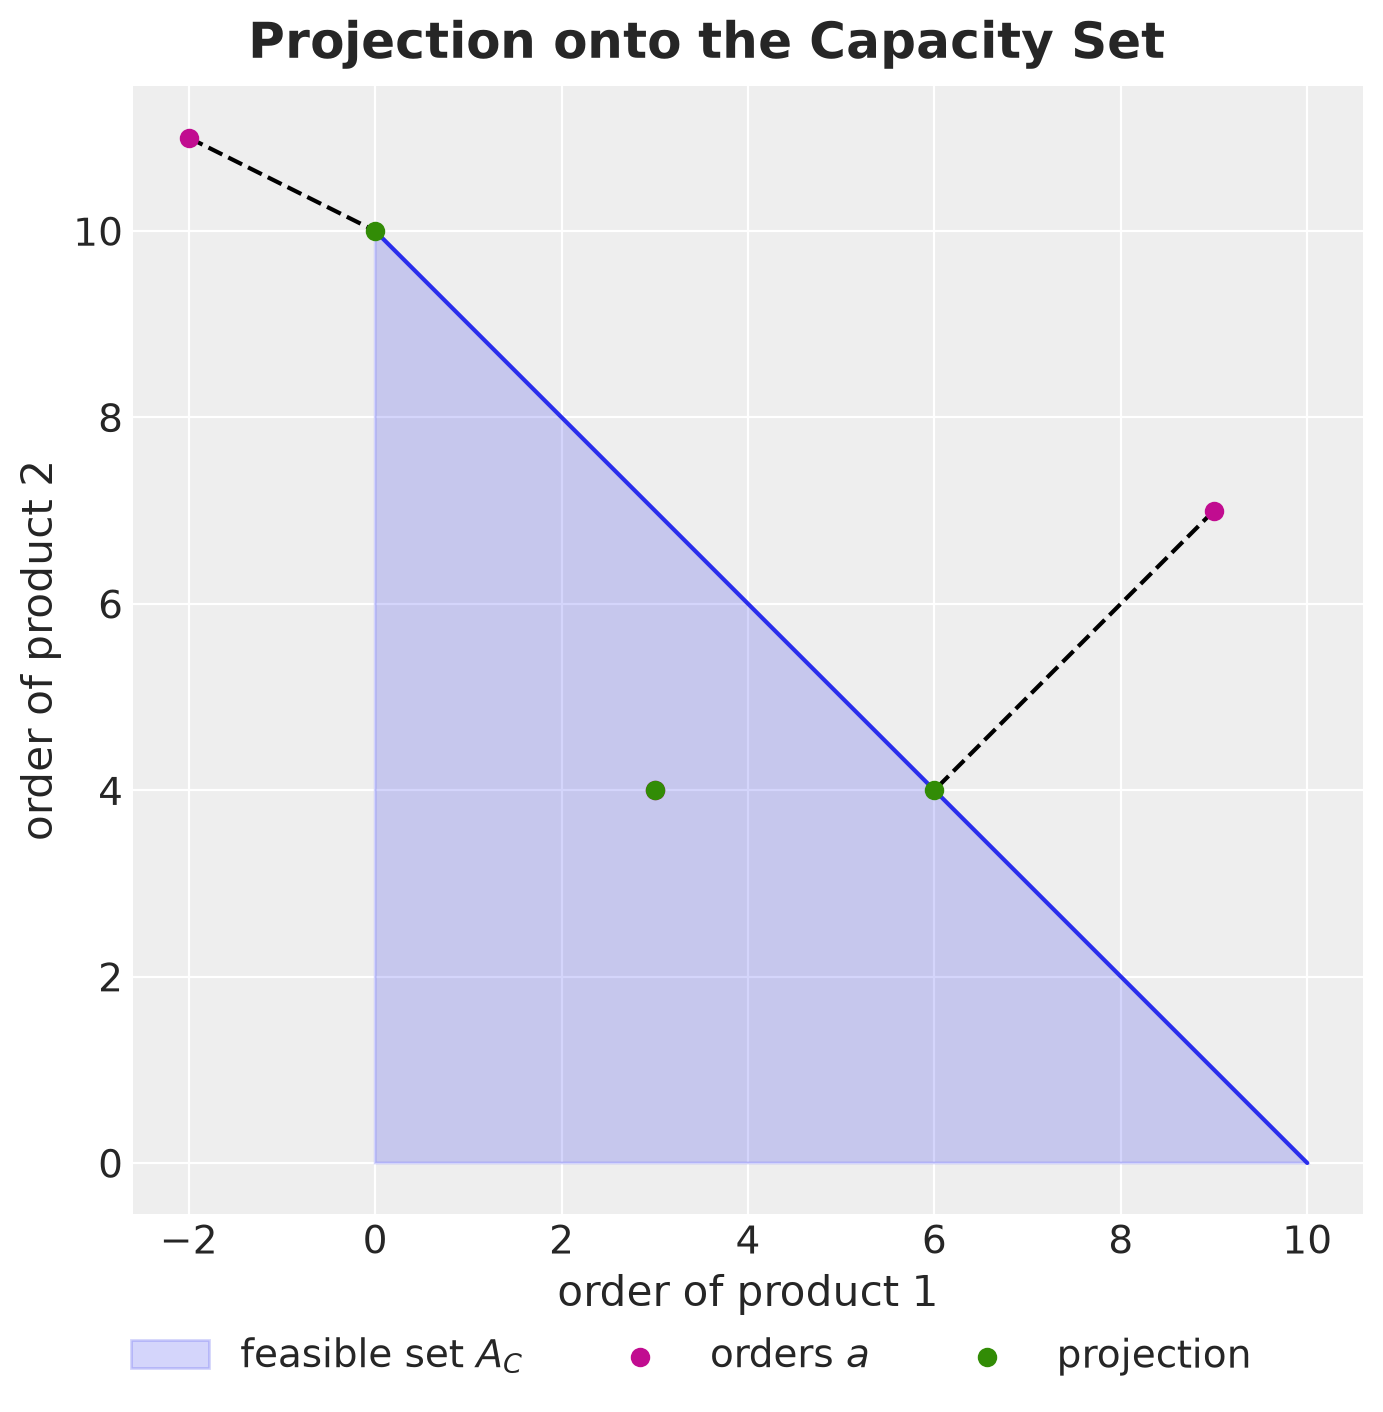

In [4]:
capacity_example = 10.0
points = jnp.array([[3.0, 4.0], [-2.0, 11.0], [9.0, 7.0]])
projected = jax.vmap(project_capacity, in_axes=(0, None))(points, capacity_example)

fig, ax = plt.subplots(figsize=(7, 7))
ax.fill(
    [0, capacity_example, 0],
    [0, 0, capacity_example],
    color="C0",
    alpha=0.2,
    label="feasible set $A_C$",
)
ax.plot([0, capacity_example], [capacity_example, 0], color="C0")
for (x, y), (px, py) in zip(points, projected, strict=True):
    ax.plot([x, px], [y, py], "--", color="black")
ax.scatter(points[:, 0], points[:, 1], color="C3", zorder=3, label="orders $a$")
ax.scatter(projected[:, 0], projected[:, 1], color="C2", zorder=3, label="projection")
ax.set(xlabel="order of product 1", ylabel="order of product 2", aspect="equal")
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Projection onto the Capacity Set", fontsize=18, fontweight="bold");

The point inside the triangle stays where it is. The point above the diagonal moves along the normal of the face: the projection takes the same amount from both products and leaves the larger order larger. The point with a negative coordinate first loses that coordinate, and since the clipped vector still exceeds the capacity, it then moves onto the face, to the corner where the whole capacity goes to product $2$.

## Generate Data

### Panel and Calendar

The panel has $G = 5$ substitution groups of $K = 4$ products, so $P = 20$ products, sold in $S = 10$ stores: $M = 200$ series. The history is one year of daily demand and the horizon is $15$ days, as in the first post.

The promotion calendar is chain-wide: a product is on promotion in all stores at once, at a $30\%$ discount, for a whole calendar week. In the history every product has a promotion week with probability $0.1$, independently of the other products. In the horizon the retailer plans a promotion for the first product of groups $1$, $2$ and $3$ in the second week.

We give the products four **roles** for the horizon:

- `promoted`: the three promoted products.
- `sibling`: the nine other products of the promoted groups.
- `control (cross)`: group $4$, which has cannibalization in its history but no promotion in the horizon.
- `control (no cross)`: group $5$, which has neither.

The two control groups serve different purposes. Nothing in group $5$ depends on cannibalization, so the plans of the two models must agree on it up to the noise of the scenarios. Group $4$ tells us whether the sibling promotions of the past leave a trace in a model that cannot explain them.

We store the sizes in a `Setup` tuple and the index arrays of the panel in a `Panel` tuple. The series are store-major: series $i = s P + j$ with the store and the product indexed from zero. The `pair_rows` and `pair_cols` arrays list the within-group pairs of distinct products, the cells of the cross-price matrix that the model estimates.

In [5]:
class Setup(NamedTuple):
    """Sizes of the panel, the history and the horizon, and the promotion settings."""

    t_obs: int = 364  # one year of daily history
    horizon: int = 15  # days to plan
    discount: float = 0.3  # price cut in a promotion week
    promo_prob: float = 0.1  # chance that a product is on promotion in a given week
    n_groups: int = 5  # substitution groups
    n_per_group: int = 4  # products per group
    n_stores: int = 10
    n_fourier_terms: int = 3  # harmonics of the weekly cycle

    @property
    def n_products(self) -> int:
        return self.n_groups * self.n_per_group

    @property
    def n_series(self) -> int:
        return self.n_stores * self.n_products

    @property
    def n_fourier(self) -> int:
        return 2 * self.n_fourier_terms

    @property
    def n_weeks(self) -> int:
        return self.t_obs // 7

    @property
    def duration(self) -> int:
        return self.t_obs + self.horizon


class Panel(NamedTuple):
    """Index arrays of the panel. Series are store-major: series = store * P + j."""

    series_to_product: Int[np.ndarray, " n_series"]
    series_to_store: Int[np.ndarray, " n_series"]
    product_to_group: Int[np.ndarray, " n_products"]
    pair_rows: Int[np.ndarray, " n_pairs"]
    pair_cols: Int[np.ndarray, " n_pairs"]


def make_panel(setup: Setup) -> Panel:
    """Build the index arrays and the within-group pairs of distinct products."""
    product_to_group = np.repeat(np.arange(setup.n_groups), setup.n_per_group)
    same_group = product_to_group[:, None] == product_to_group[None, :]
    off_diagonal = ~np.eye(setup.n_products, dtype=bool)
    pair_rows, pair_cols = np.where(same_group & off_diagonal)
    return Panel(
        series_to_product=np.tile(np.arange(setup.n_products), setup.n_stores),
        series_to_store=np.repeat(np.arange(setup.n_stores), setup.n_products),
        product_to_group=product_to_group,
        pair_rows=pair_rows,
        pair_cols=pair_cols,
    )


setup = Setup()
panel = make_panel(setup)
n_pairs = panel.pair_rows.shape[0]
assert (setup.n_products, setup.n_series, n_pairs) == (20, 200, 60)

days = np.arange(setup.duration)
days_future = days[setup.t_obs :]
fourier = fourier_features(setup.duration, period=7.0, num_terms=setup.n_fourier_terms)

# the horizon plan: the first product of groups 1 to 3, promoted in the second week
promoted_products = np.arange(3) * setup.n_per_group
promo_future = (
    jnp.zeros((setup.horizon, setup.n_products)).at[7:14, promoted_products].set(1.0)
)
promo_days_future = days_future[7:14]
# the true cross elasticity of every group, fixed below with the other true values
group_cross = np.array([0.6, 0.3, 0.0, 0.3, 0.0])

ROLES = ["promoted", "sibling", "control (cross)", "control (no cross)"]
ROLE_COLORS = dict(zip(ROLES, ["C3", "C1", "C0", "C9"], strict=True))
promoted_groups = panel.product_to_group[promoted_products]
product_role = np.where(
    np.isin(np.arange(setup.n_products), promoted_products),
    ROLES[0],
    np.where(
        np.isin(panel.product_to_group, promoted_groups),
        ROLES[1],
        np.where(group_cross[panel.product_to_group] > 0, ROLES[2], ROLES[3]),
    ),
)
series_role = product_role[panel.series_to_product]
products = pl.DataFrame(
    {
        "product": np.arange(setup.n_products),
        "group": panel.product_to_group + 1,
        "role": product_role,
    }
)
products.group_by("role").len().sort("role")

role,len
str,u32
"""control (cross)""",4
"""control (no cross)""",4
"""promoted""",3
"""sibling""",9


The four roles cover the $20$ products: $3$ promoted, $9$ siblings, $4$ in the control group with cross effects and $4$ in the one without.

The calendar is the only random input besides the demand. We draw it from a small generative model, one Bernoulli per product and week, and append the planned horizon. The deterministic `log_price` site is the log of the price relative to the list price, $\log(1 - 0.3)$ in a promotion week and zero otherwise.

In [6]:
def calendar_generator(
    setup: Setup, promo_future: Float[Array, "horizon n_products"]
) -> None:
    """Chain-wide promotion weeks of the history, followed by the planned horizon."""
    with (
        numpyro.plate("product", setup.n_products, dim=-1),
        numpyro.plate("week", setup.n_weeks, dim=-2),
    ):
        promo_week = numpyro.sample("promo_week", dist.Bernoulli(setup.promo_prob))
    promo_history = jnp.repeat(promo_week, 7, axis=0)
    promo = jnp.concatenate([promo_history, promo_future], axis=0)
    numpyro.deterministic("log_price", promo * jnp.log(1.0 - setup.discount))


rng_key, key_calendar = random.split(rng_key)
calendar = Predictive(calendar_generator, num_samples=1)(
    key_calendar, setup, promo_future
)
log_price = calendar["log_price"][0]  # (duration, n_products)
promo_week_true = np.asarray(calendar["promo_week"][0])  # (n_weeks, n_products)
promo_full = np.concatenate(
    [np.repeat(promo_week_true, 7, axis=0), np.asarray(promo_future)], axis=0
)

# one array of covariates: the Fourier columns, then one log price column per product
covariates = jnp.concatenate([fourier, log_price], axis=1)
covariates_train = covariates[: setup.t_obs]
assert covariates.shape == (setup.duration, setup.n_fourier + setup.n_products)

The following heatmap shows the calendar, one row per product, with the group borders in orange and the start of the horizon as a dashed line. We count the product-weeks in which at least one sibling of the product is on promotion, which identify its cross elasticities, and the group-weeks in which two products of a group are on promotion at once.

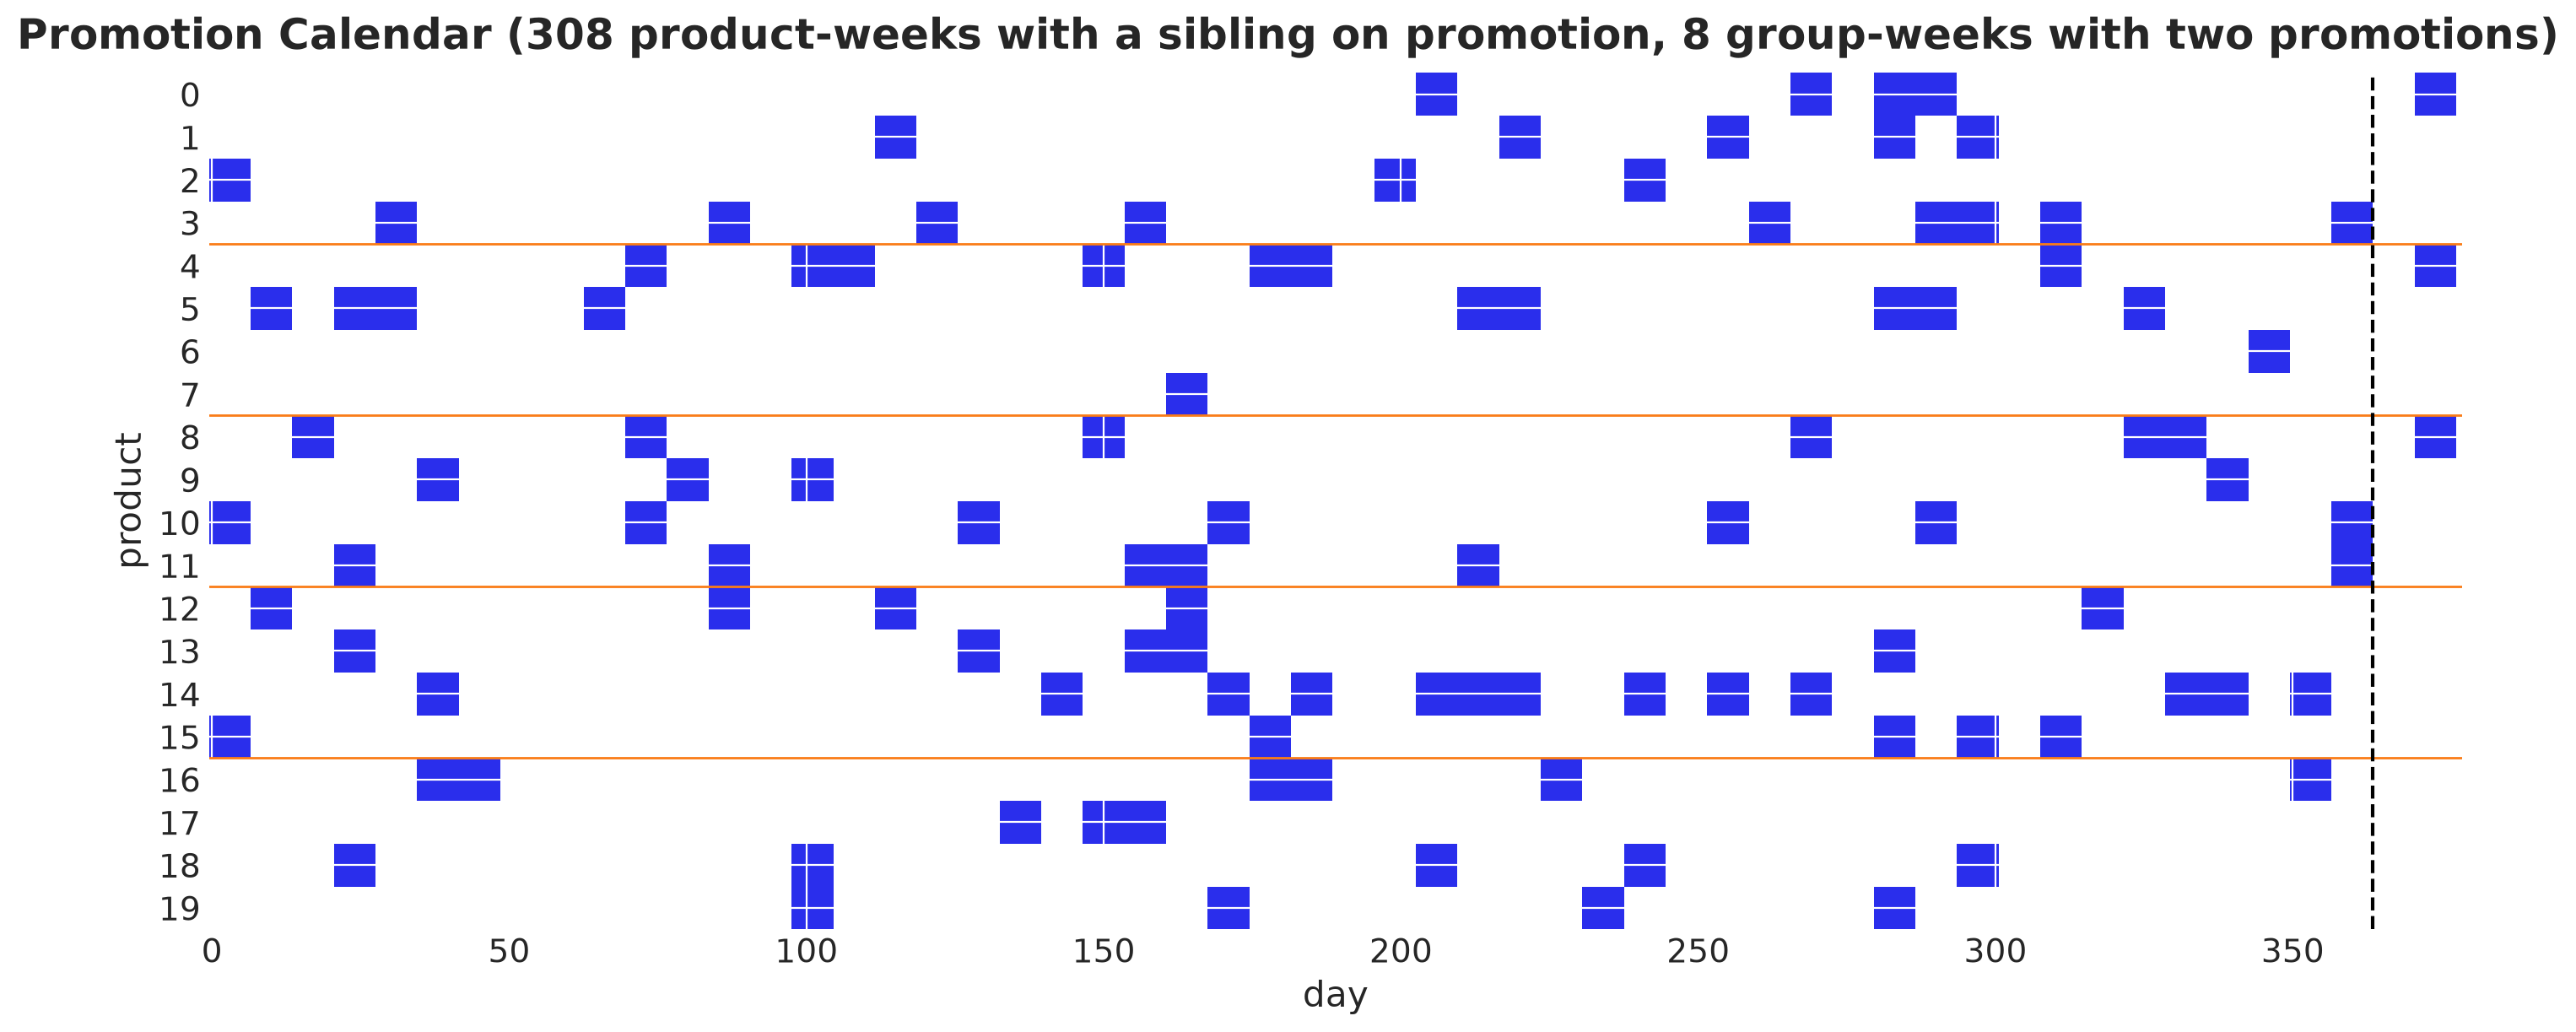

In [7]:
sibling_promo_weeks = sum(
    int(
        (
            promo_week_true[:, panel.product_to_group == g].sum(axis=1)
            - promo_week_true[:, j]
            > 0
        ).sum()
    )
    for j, g in enumerate(panel.product_to_group)
)
double_promo_weeks = sum(
    int((promo_week_true[:, panel.product_to_group == g].sum(axis=1) >= 2).sum())
    for g in range(setup.n_groups)
)

fig, ax = plt.subplots(figsize=(14, 6))
ax.imshow(
    promo_full.T,
    aspect="auto",
    cmap=ListedColormap(["white", "C0"]),
    interpolation="nearest",
)
for g in range(1, setup.n_groups):
    ax.axhline(g * setup.n_per_group - 0.5, color="C1", linewidth=1)
ax.axvline(setup.t_obs - 0.5, color="black", linestyle="--")
ax.set(xlabel="day", ylabel="product", yticks=range(setup.n_products))
fig.suptitle(
    f"Promotion Calendar ({sibling_promo_weeks} product-weeks with a sibling "
    f"on promotion, {double_promo_weeks} group-weeks with two promotions)",
    fontsize=18,
    fontweight="bold",
);

The blue cells are the promotion weeks. Every product has a handful of own promotion weeks in the history, and the title counts the product-weeks in which at least one sibling is on promotion, which is where the data say how much a product loses to its siblings. The three cells on the right of the dashed line are the planned promotion of the horizon.

### Demand Model

Let $\mu_{t,i}$ be the **expected demand** of series $i = (s, j)$ on day $t$. Let $\ell_{t,i}$ be its **latent level**, a random walk with **initial level** $\ell_{0,i}$ and **daily increments** $\delta_{t,i}$ of scale $\sigma_i$. Let $f_t$ be the **vector of Fourier features** of the weekly cycle and $\beta_j$ the **Fourier coefficients** of product $j$, shared by its stores. Let $x_{t,k} = \log r_{t,k} \leq 0$ be the **log relative price** of product $k$ on day $t$, where $r_{t,k}$ is the price relative to the list price. The log of the expected demand is

$$
\log \mu_{t,i} = \ell_{t,i} + f_t^\top \beta_j + \sum_{k \in g(j)} \gamma_{kj} \, x_{t,k},
\qquad
\ell_{t,i} = \ell_{0,i} + \sum_{u \leq t} \delta_{u,i},
\qquad
\delta_{u,i} \sim \text{Normal}(0, \sigma_i).
$$

The sum runs over the products $k$ of the group of $j$, including $j$ itself. The matrix $\Gamma = (\gamma_{kj})$ is the **elasticity matrix** of the group. Its diagonal entry $\gamma_{jj}$ is the **own elasticity** of product $j$, the response of its demand to its own price, which is negative. An off-diagonal entry $\gamma_{kj}$ with $k \neq j$ is a **cross elasticity**, the response of the demand of product $j$ to the price of product $k$. A promotion of a sibling $k$ makes $x_{t,k}$ negative, so a positive $\gamma_{kj}$ lowers the demand of $j$: positive cross elasticities are cannibalization. Taking exponentials, a $30\%$ cut on product $k$ multiplies the demand of a sibling $j$ by $0.7^{\gamma_{kj}}$, so a cross elasticity of $0.6$ is a loss of $1 - 0.7^{0.6} \approx 19\%$.

The likelihood is the negative binomial of the first post, with a **concentration** $\phi_j$ per product. With respect to the first post, the Fourier vector $x_t$ is now $f_t$, since $x$ is the log price, and the intercept $\beta_0$ plus the level is now the level $\ell_{t,i}$ with its own initial value per series:

$$
D_{t,i} \sim \text{NegativeBinomial}(\mu_{t,i}, \phi_j).
$$

We write each term of the log mean as a function that samples its own sites and returns its contribution with shape `(duration, n_series)`, the pattern of the NumPyro [Hilbert space Gaussian process example](https://num.pyro.ai/en/stable/examples/hsgp.html). The same function is the generator (with the true parameters fixed through `do`) and the two fitted models, so the true parameters are in the support of the model by construction. The `cross` flag adds or removes the cross-price term, and the `reparam` flag switches on the non-centered parameterization of the level increments and of the cross elasticities, which the guide needs and the generator does not.

The prices are chain-wide, so the cross-price term of a series depends on its product only. We compute it as the matrix product of the log prices with the elasticity matrix $\Gamma$ and gather it to the series axis. The own elasticities form the diagonal of $\Gamma$, and the `cross_elasticity` site over the within-group pairs fills the off-diagonal cells, shrunk toward zero by the common scale `cross_scale`.

In [8]:
class Priors(NamedTuple):
    """Prior hyperparameters of the demand model."""

    intercept_mu: float
    intercept_sigma: float
    drift_mu: float
    drift_sigma: float
    concentration_alpha: float
    concentration_beta: float
    cross_scale_sigma: float
    seasonal_sigma: float = 0.3
    elasticity_mu: float = -1.0
    elasticity_sigma: float = 1.0


def local_level(
    h: Horizon, series_plate: numpyro.plate, priors: Priors, *, reparam: bool
) -> Float[Array, "duration n_series"]:
    """Random-walk level per series: the initial level plus the summed increments."""
    with series_plate:
        intercept = numpyro.sample(
            "intercept", dist.Normal(priors.intercept_mu, priors.intercept_sigma)
        )
        drift_scale = numpyro.sample(
            "drift_scale", dist.LogNormal(priors.drift_mu, priors.drift_sigma)
        )
        drift = innovations(
            h,
            "drift",
            dist.Normal(0.0, drift_scale),
            reparam=LocScaleReparam(0) if reparam else None,
        )
    return intercept + jnp.cumsum(drift, axis=-2)


def weekly_seasonality(
    fourier: Float[Array, "duration n_fourier"],
    product_plate: numpyro.plate,
    fourier_plate: numpyro.plate,
    panel: Panel,
    priors: Priors,
) -> Float[Array, "duration n_series"]:
    """Weekly Fourier seasonality with one coefficient vector per product."""
    with fourier_plate, product_plate:
        beta = numpyro.sample("beta", dist.Normal(0.0, priors.seasonal_sigma))
    return (fourier @ beta)[:, panel.series_to_product]


def price_effects(
    log_price: Float[Array, "duration n_products"],
    product_plate: numpyro.plate,
    pair_plate: numpyro.plate,
    panel: Panel,
    priors: Priors,
    *,
    cross: bool,
    reparam: bool,
) -> Float[Array, "duration n_series"]:
    """Own price elasticities, plus the cross elasticities of the within-group pairs."""
    with product_plate:
        elasticity = numpyro.sample(
            "elasticity", dist.Normal(priors.elasticity_mu, priors.elasticity_sigma)
        )
    matrix = jnp.diag(elasticity)
    if cross:
        cross_scale = numpyro.sample(
            "cross_scale", dist.HalfNormal(priors.cross_scale_sigma)
        )
        # non-centered: the guide sees standardized cross elasticities
        reparam_config = {"cross_elasticity": LocScaleReparam(0)} if reparam else {}
        with pair_plate, handlers.reparam(config=reparam_config):
            cross_elasticity = numpyro.sample(
                "cross_elasticity", dist.Normal(0.0, cross_scale)
            )
        matrix = matrix.at[panel.pair_rows, panel.pair_cols].set(cross_elasticity)
    # effect[t, i] = sum_k matrix[k, j(i)] * log_price[t, k]
    return (log_price @ matrix)[:, panel.series_to_product]


def dispersion(
    product_plate: numpyro.plate, panel: Panel, priors: Priors
) -> Float[Array, " n_series"]:
    """Negative binomial concentration per product, gathered to the series axis."""
    with product_plate:
        concentration = numpyro.sample(
            "concentration",
            dist.Gamma(priors.concentration_alpha, priors.concentration_beta),
        )
    return concentration[panel.series_to_product]


def make_demand_model(
    panel: Panel, setup: Setup, priors: Priors, *, cross: bool, reparam: bool = True
) -> ForecastModel:
    """Build the demand model as a plain `(covariates, data=None)` function."""
    n_products, n_series, n_fourier = setup.n_products, setup.n_series, setup.n_fourier
    n_pairs = panel.pair_rows.shape[0]

    def demand_model(
        covariates: Float[Array, "duration inputs"],
        data: Int[Array, "t_obs n_series"] | None = None,
    ) -> None:
        h = Horizon.from_data(covariates, data)
        fourier, log_price = covariates[:, :n_fourier], covariates[:, n_fourier:]
        series_plate = numpyro.plate("series", n_series, dim=-1)
        product_plate = numpyro.plate("product", n_products, dim=-1)
        fourier_plate = numpyro.plate("fourier", n_fourier, dim=-2)
        pair_plate = numpyro.plate("pair", n_pairs, dim=-1)

        log_rate = local_level(h, series_plate, priors, reparam=reparam)
        log_rate = log_rate + weekly_seasonality(
            fourier, product_plate, fourier_plate, panel, priors
        )
        log_rate = log_rate + price_effects(
            log_price,
            product_plate,
            pair_plate,
            panel,
            priors,
            cross=cross,
            reparam=reparam,
        )
        concentration = dispersion(product_plate, panel, priors)
        predict(
            h, lambda eta: dist.NegativeBinomial2(jnp.exp(eta), concentration), log_rate
        )

    return demand_model

### Prior Elicitation

We elicit the priors here, before the forecasting model, because the generator of the next section needs a `Priors` tuple, and because the two forecasting models of this notebook share them.

The model has six families of global parameters. For four of them we state what we believe on the scale of the data and use [PreliZ](https://preliz.readthedocs.io/) to turn the statement into a distribution: `pz.maxent` returns the member of a family that puts a given mass between two bounds (the one with maximum entropy, so it adds nothing beyond our constraints). Three of the four are the priors of the first post, and we repeat the reasoning because the model has grown. Here is the reasoning for each of them.

- **`intercept`**: $\exp(\ell_{0,i})$ is the demand per day of series $i$ at the start of the history at the list price, with the weekly pattern averaged out on the log scale (the Fourier terms sum to zero over a week). We believe it lies between $10$ and $300$ units for every series of the chain, a wide range for products that sell tens of units per day. So we ask for a Normal on $\ell_{0,i}$ with $94\%$ of its mass between $\log 10$ and $\log 300$.

- **`drift_scale`**: the level of a series is a random walk, so after $T$ days the standard deviation of the log level is $\sigma_i \sqrt{T}$, and $\exp(\sigma_i \sqrt{T})$ is the typical factor by which the level has moved. Over the $364$ days of history we believe that factor lies between $1.04$ and $2$, that is, from a $4\%$ move to a doubling. So we ask for a LogNormal on $\sigma_i$ with $94\%$ of its mass between $\log(1.04) / \sqrt{T}$ and $\log(2) / \sqrt{T}$.

- **`concentration`**: the negative binomial adds $\mu_{t,i}^2 / \phi_j$ to the Poisson variance, so the extra day-to-day noise is a fraction $1 / \sqrt{\phi_j}$ of the level. We believe that fraction lies between a tenth and a half, which is $\phi_j$ between $4$ and $100$. So we ask for a Gamma with $94\%$ of its mass in that range.

- **`cross_scale`**: this is the new one. The cross elasticities of a group share the prior $\gamma_{kj} \sim \text{Normal}(0, \sigma_\gamma)$ for $k \neq j$, centered at zero and shrunk by the common scale $\sigma_\gamma$, so the data can also say that a group has no cannibalization. To reason about $\sigma_\gamma$ on the data scale, consider a sibling whose cross elasticity is one prior standard deviation, $\gamma_{kj} = \sigma_\gamma$. Under a $30\%$ cut on product $k$, this sibling loses a share $1 - 0.7^{\sigma_\gamma}$ of its demand. We believe that this typical loss lies below $15\%$, which is a cross elasticity of $\log(0.85) / \log(0.7) \approx 0.46$. The scale is positive, so we ask for a HalfNormal on $\sigma_\gamma$ with $94\%$ of its mass between $0$ and $0.46$.

The other two priors we state directly, as in the first post.

- Each Fourier coefficient in `beta` gets a $\text{Normal}(0, 0.3)$, so two standard deviations multiply the demand by $e^{\pm 0.6}$, between $0.55$ and $1.8$.

- The own `elasticity` of every product gets a $\text{Normal}(-1, 1)$: a higher price should lower the demand, so we center the prior on a negative value, and the standard deviation of $1$ leaves a positive value possible if the data ask for it.

We run the four elicitations and store the results in the `Priors` tuple that the model functions read.

In [9]:
ELICITATION_MASS = 0.94
intercept_bounds = (float(np.log(10)), float(np.log(300)))
drift_bounds = (
    float(np.log(1.04) / np.sqrt(setup.t_obs)),
    float(np.log(2) / np.sqrt(setup.t_obs)),
)
concentration_bounds = (4.0, 100.0)
cross_bounds = (0.0, float(np.log(0.85) / np.log(1 - setup.discount)))

intercept_prior = pz.maxent(
    pz.Normal(), *intercept_bounds, mass=ELICITATION_MASS, plot=False
)
drift_prior = pz.maxent(
    pz.LogNormal(), *drift_bounds, mass=ELICITATION_MASS, plot=False
)
concentration_prior = pz.maxent(
    pz.Gamma(), *concentration_bounds, mass=ELICITATION_MASS, plot=False
)
cross_prior = pz.maxent(
    pz.HalfNormal(), *cross_bounds, mass=ELICITATION_MASS, plot=False
)

priors = Priors(
    intercept_mu=float(intercept_prior.mu),
    intercept_sigma=float(intercept_prior.sigma),
    drift_mu=float(drift_prior.mu),
    drift_sigma=float(drift_prior.sigma),
    concentration_alpha=float(concentration_prior.alpha),
    concentration_beta=float(concentration_prior.beta),
    cross_scale_sigma=float(cross_prior.sigma),
)
priors

Priors(intercept_mu=4.003183782859332, intercept_sigma=0.9041923524778083, drift_mu=-4.256238821541877, drift_sigma=0.6030939337649646, concentration_alpha=2.770404672643779, concentration_beta=0.057794400394901864, cross_scale_sigma=0.2422647572740421, seasonal_sigma=0.3, elasticity_mu=-1.0, elasticity_sigma=1.0)

Next, we plot the four elicited densities in two rows. The top row is the parameter scale, with the elicited density and the two bounds we asked for. The bottom row is the data scale: the density of the quantity we reasoned about (demand per day, level multiplier after one year, noise fraction, sibling loss at one prior standard deviation under a $30\%$ cut), with the bounds mapped through the same transform.

The bottom row needs no draws. If $\psi = T(\eta)$ is a monotone transform of the parameter $\eta$ with density $q$, the density of $\psi$ is $q(T^{-1}(\psi)) \, |dT^{-1} / d\psi|$ by the change of variables formula. We write the inverse transforms in `jax.numpy` and take the derivative with `jax.grad`.

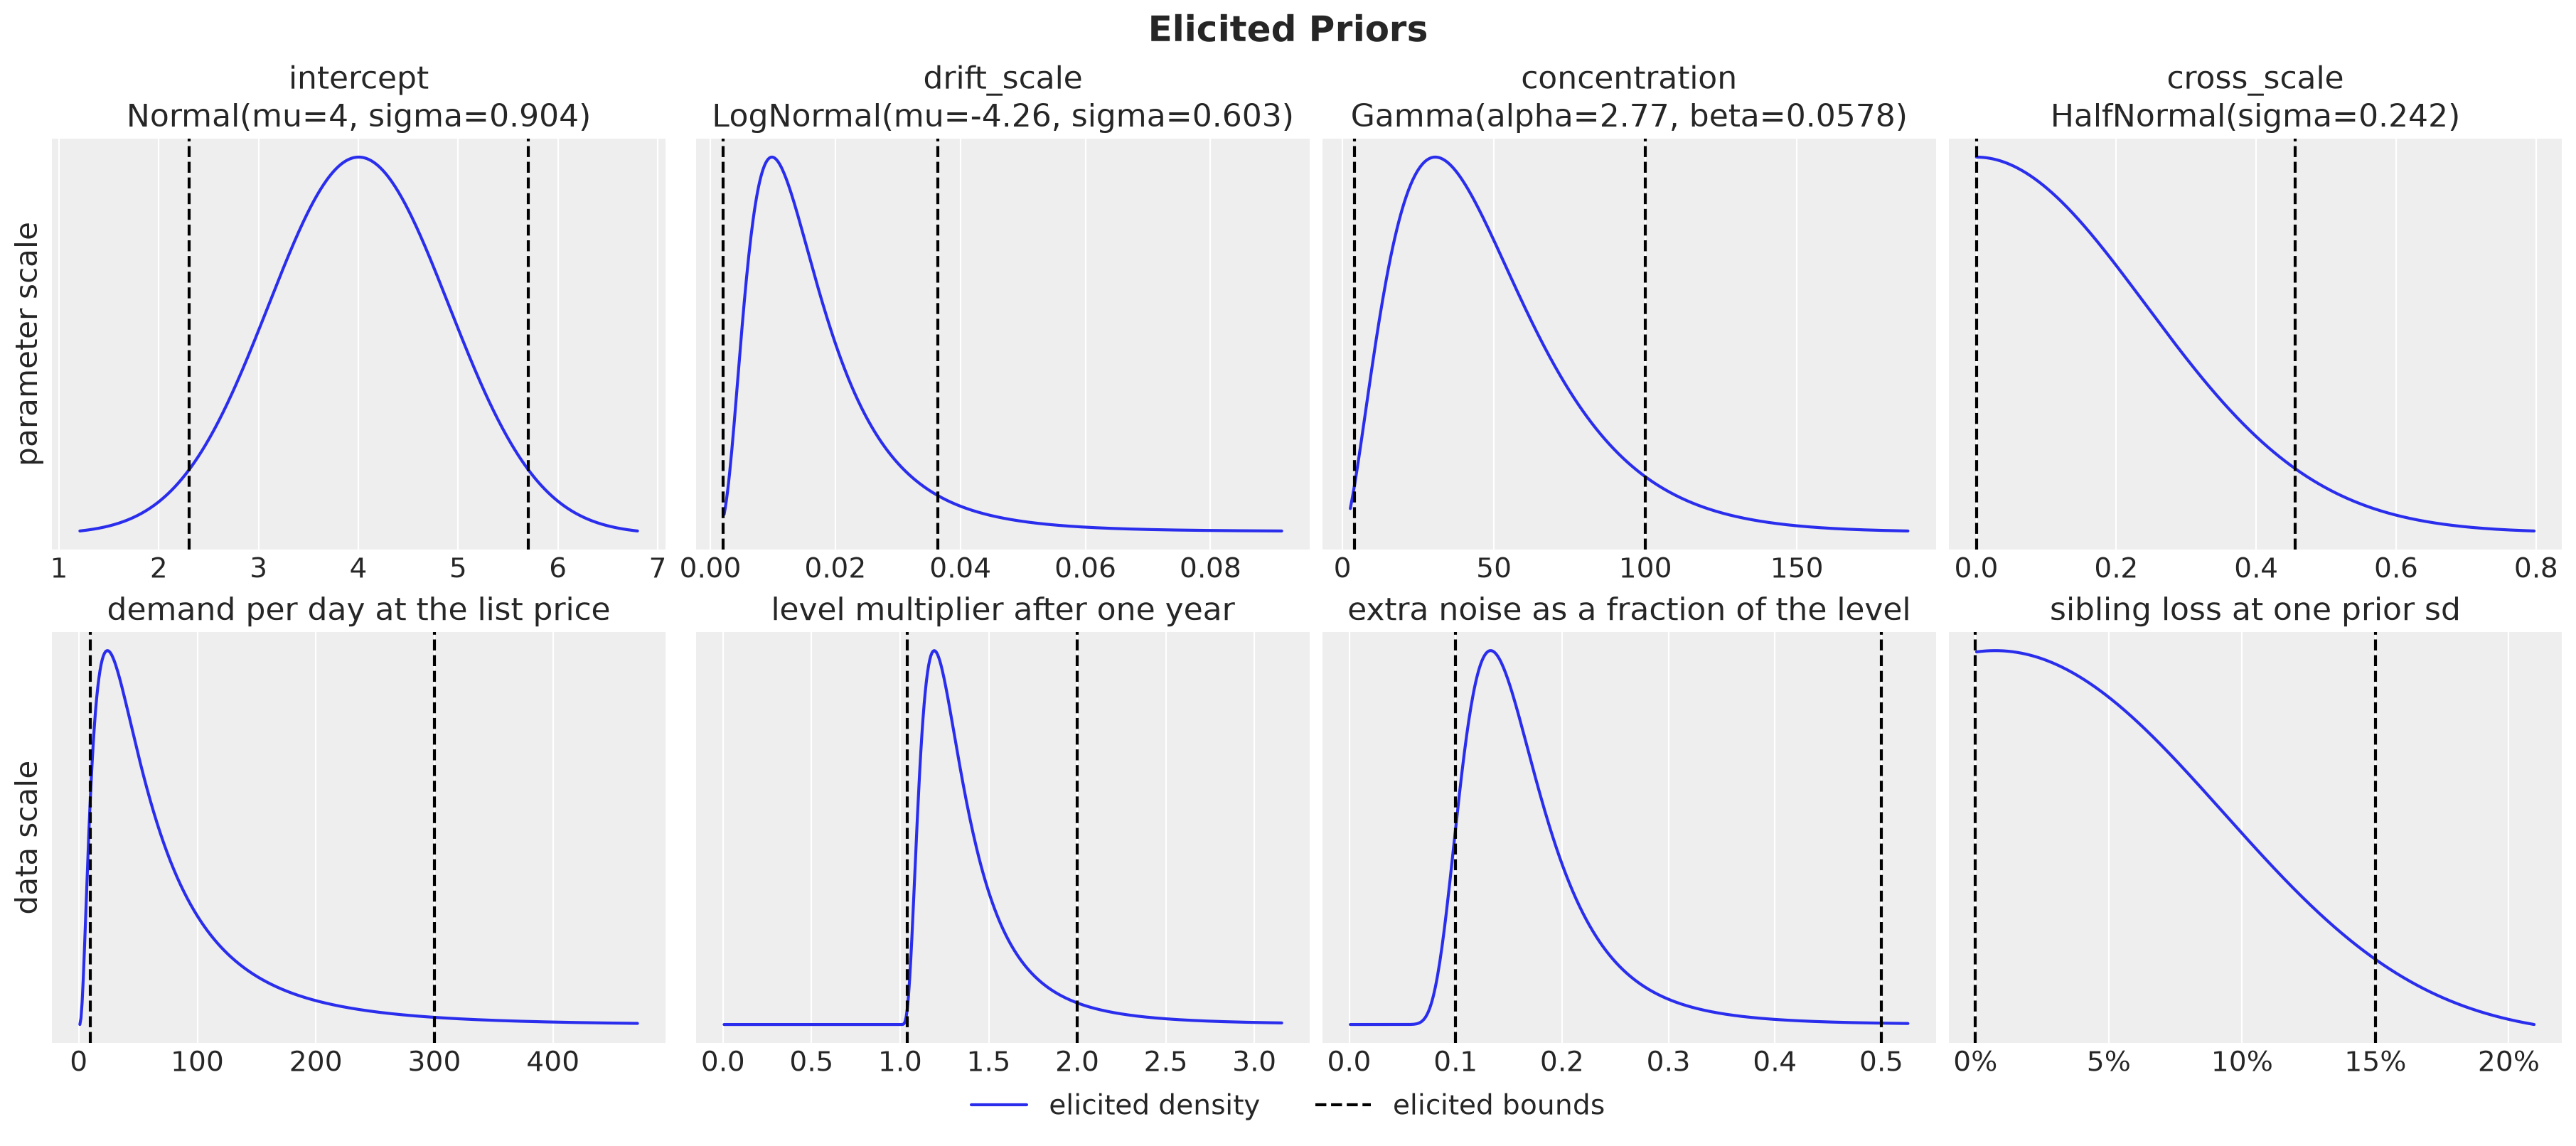

In [10]:
priors_elicited = {
    "intercept": (intercept_prior, intercept_bounds),
    "drift_scale": (drift_prior, drift_bounds),
    "concentration": (concentration_prior, concentration_bounds),
    "cross_scale": (cross_prior, cross_bounds),
}
# the quantity on the data scale that each prior is about, with the inverse transform
log_discount = np.log(1 - setup.discount)
data_scale = {
    "intercept": ("demand per day at the list price", jnp.exp, jnp.log),
    "drift_scale": (
        "level multiplier after one year",
        lambda x: jnp.exp(x * jnp.sqrt(setup.t_obs)),
        lambda y: jnp.log(y) / jnp.sqrt(setup.t_obs),
    ),
    "concentration": (
        "extra noise as a fraction of the level",
        lambda x: 1 / jnp.sqrt(x),
        lambda y: 1 / y**2,
    ),
    "cross_scale": (
        "sibling loss at one prior sd",
        lambda x: 1 - jnp.exp(x * log_discount),
        lambda y: jnp.log(1 - y) / log_discount,
    ),
}


def density_on_data_scale(
    prior: pz.distributions.distributions.Continuous,
    inverse: Callable[[Float[Array, " grid"]], Float[Array, " grid"]],
    grid: Float[Array, " grid"],
) -> Float[Array, " grid"]:
    """Density of a monotone transform of the prior, by change of variables."""
    jacobian = jnp.abs(jax.vmap(jax.grad(inverse))(grid))
    return prior.pdf(inverse(grid)) * jacobian


fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 8), layout="constrained")

for j, (name, (prior, bounds)) in enumerate(priors_elicited.items()):
    label, transform, inverse = data_scale[name]
    # parameter scale: the elicited density and the bounds
    ax = axes[0, j]
    x = np.linspace(*prior.ppf([0.001, 0.999]), 500)
    ax.plot(x, prior.pdf(x), color="C0", label="elicited density")
    ax.axvline(bounds[0], color="black", linestyle="--", label="elicited bounds")
    ax.axvline(bounds[1], color="black", linestyle="--")
    ax.set(title=f"{name}\n{prior}", yticks=[])
    # data scale: the same density after the transform, from near zero to the
    # larger of the 99th percentile and the upper bound
    ax = axes[1, j]
    bounds_data = transform(jnp.asarray(bounds))
    upper = 1.05 * max(
        float(transform(prior.ppf([0.01, 0.99])).max()), float(bounds_data.max())
    )
    grid = jnp.linspace(upper / 500, upper, 500)
    ax.plot(grid, density_on_data_scale(prior, inverse, grid), color="C0")
    for bound in bounds_data:
        ax.axvline(bound, color="black", linestyle="--")
    ax.set(title=label, yticks=[])

axes[1, 3].xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
axes[0, 0].set(ylabel="parameter scale")
axes[1, 0].set(ylabel="data scale")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=2)
fig.suptitle("Elicited Priors", fontsize=18, fontweight="bold");

The elicited priors are a $\text{Normal}(4.0, 0.9)$ for the `intercept`, a $\text{LogNormal}(-4.3, 0.6)$ for the drift scale and a $\text{Gamma}$ with shape $2.8$ and rate $0.06$ for the concentration, the values of the first post, and a $\text{HalfNormal}(0.24)$ for the scale of the cross elasticities.

The top row shows the four elicited densities with their bounds, and the mass between the bounds is $94\%$ in each panel. The bottom row shows what these priors say on the data scale. The demand per day spreads between a few units and a few hundred, with most of the mass below $100$ units. The level multiplier after one year sits between no move and a doubling, with a tail beyond. The noise fraction sits mostly between $0.1$ and $0.3$. The sibling loss at one prior standard deviation has most of its mass below $10\%$, so the prior favors small cross effects and leaves room for large ones.

Note that `pz.maxent` fixes the total mass between the bounds and not the two tails. The Gamma puts almost all of its remaining $6\%$ above $100$, which is the tail below $0.1$ in the noise panel, and the HalfNormal starts at zero, so all of its remaining $6\%$ sits above a loss of $15\%$. The true values we fix in the next cell sit inside all four priors: the initial levels between $\log 12$ and $\log 225$, the drift scales between $0.005$ and $0.02$, the concentrations between $20$ and $40$, and a root mean square cross elasticity of $0.33$ across the $60$ pairs.

### True Parameters and Data

We fix the true parameters by hand, with the numpy generator for the values that differ across products and stores. The product baselines range from $20$ to $150$ units per day and the store multipliers from $0.6$ to $1.5$, so the initial level of a series is the log of their product. The own elasticities lie between $-2$ and $-1$, the concentrations between $20$ and $40$, and the drift scales between $0.005$ and $0.02$. The cross elasticities are constant within a group: $0.6$, $0.3$, $0$, $0.3$ and $0$ for groups $1$ to $5$. Under a $30\%$ cut a sibling loses $1 - 0.7^{\gamma}$ of its demand: $19\%$, $10\%$ and nothing. Group $3$ is promoted but has no cannibalization, so the cross model must learn not to move demand there.

In [11]:
base_product = np.exp(rng.uniform(np.log(20), np.log(150), size=setup.n_products))
store_multiplier = rng.uniform(0.6, 1.5, size=setup.n_stores)

true_params: dict[str, Array] = {
    "intercept": jnp.asarray(
        np.log(
            base_product[panel.series_to_product]
            * store_multiplier[panel.series_to_store]
        )
    ),
    "drift_scale": jnp.asarray(rng.uniform(0.005, 0.02, size=setup.n_series)),
    "beta": jnp.asarray(
        rng.normal(0.0, 0.05, size=(setup.n_fourier, setup.n_products))
    ),
    "elasticity": jnp.asarray(rng.uniform(-2.0, -1.0, size=setup.n_products)),
    # fixed for completeness: the pairs below are fixed too, so it has no effect
    "cross_scale": jnp.asarray(0.3),
    "cross_elasticity": jnp.asarray(
        group_cross[panel.product_to_group[panel.pair_rows]]
    ),
    "concentration": jnp.asarray(rng.uniform(20.0, 40.0, size=setup.n_products)),
}

products = products.with_columns(
    baseline=base_product.round(1),
    elasticity=np.asarray(true_params["elasticity"]).round(2),
    concentration=np.asarray(true_params["concentration"]).round(1),
    cross_elasticity=group_cross[panel.product_to_group],
)
products

product,group,role,baseline,elasticity,concentration,cross_elasticity
i64,i64,str,f64,f32,f32,f64
0,1,"""promoted""",92.1,-1.85,29.1,0.6
1,1,"""sibling""",40.9,-1.06,36.5,0.6
2,1,"""sibling""",141.4,-1.56,25.9,0.6
3,1,"""sibling""",120.9,-1.62,29.200001,0.6
4,2,"""promoted""",96.0,-1.27,28.799999,0.3
…,…,…,…,…,…,…
15,4,"""control (cross)""",29.3,-1.36,33.299999,0.3
16,5,"""control (no cross)""",26.0,-1.88,33.0,0.0
17,5,"""control (no cross)""",52.2,-1.41,21.799999,0.0


We draw the demand of the whole duration once, from the model with the true parameters fixed. We keep the realized level increments of the history, because the true future distribution conditions on them. The observed data are the first $364$ days and the true future the last $15$.

In [12]:
generator = make_demand_model(panel, setup, priors, cross=True, reparam=False)
rng_key, key_data = random.split(rng_key)
draw = Predictive(
    do(generator, data=true_params), num_samples=1, return_sites=["obs", "drift"]
)(key_data, covariates)
demand_full = draw["obs"][0]  # (duration, n_series)
drift_true = draw["drift"][0][: setup.t_obs]  # (t_obs, n_series)
data = demand_full[: setup.t_obs].astype(jnp.int32)
demand_future_true = demand_full[setup.t_obs :].astype(jnp.float32)
assert data.shape == (setup.t_obs, setup.n_series)
assert demand_future_true.shape == (setup.horizon, setup.n_series)

The next figure shows the four products of group $1$ in store $1$ over the last eight weeks of the history and the horizon. The own promotion weeks of a product are shaded in one color and the weeks in which a sibling is on promotion in another.

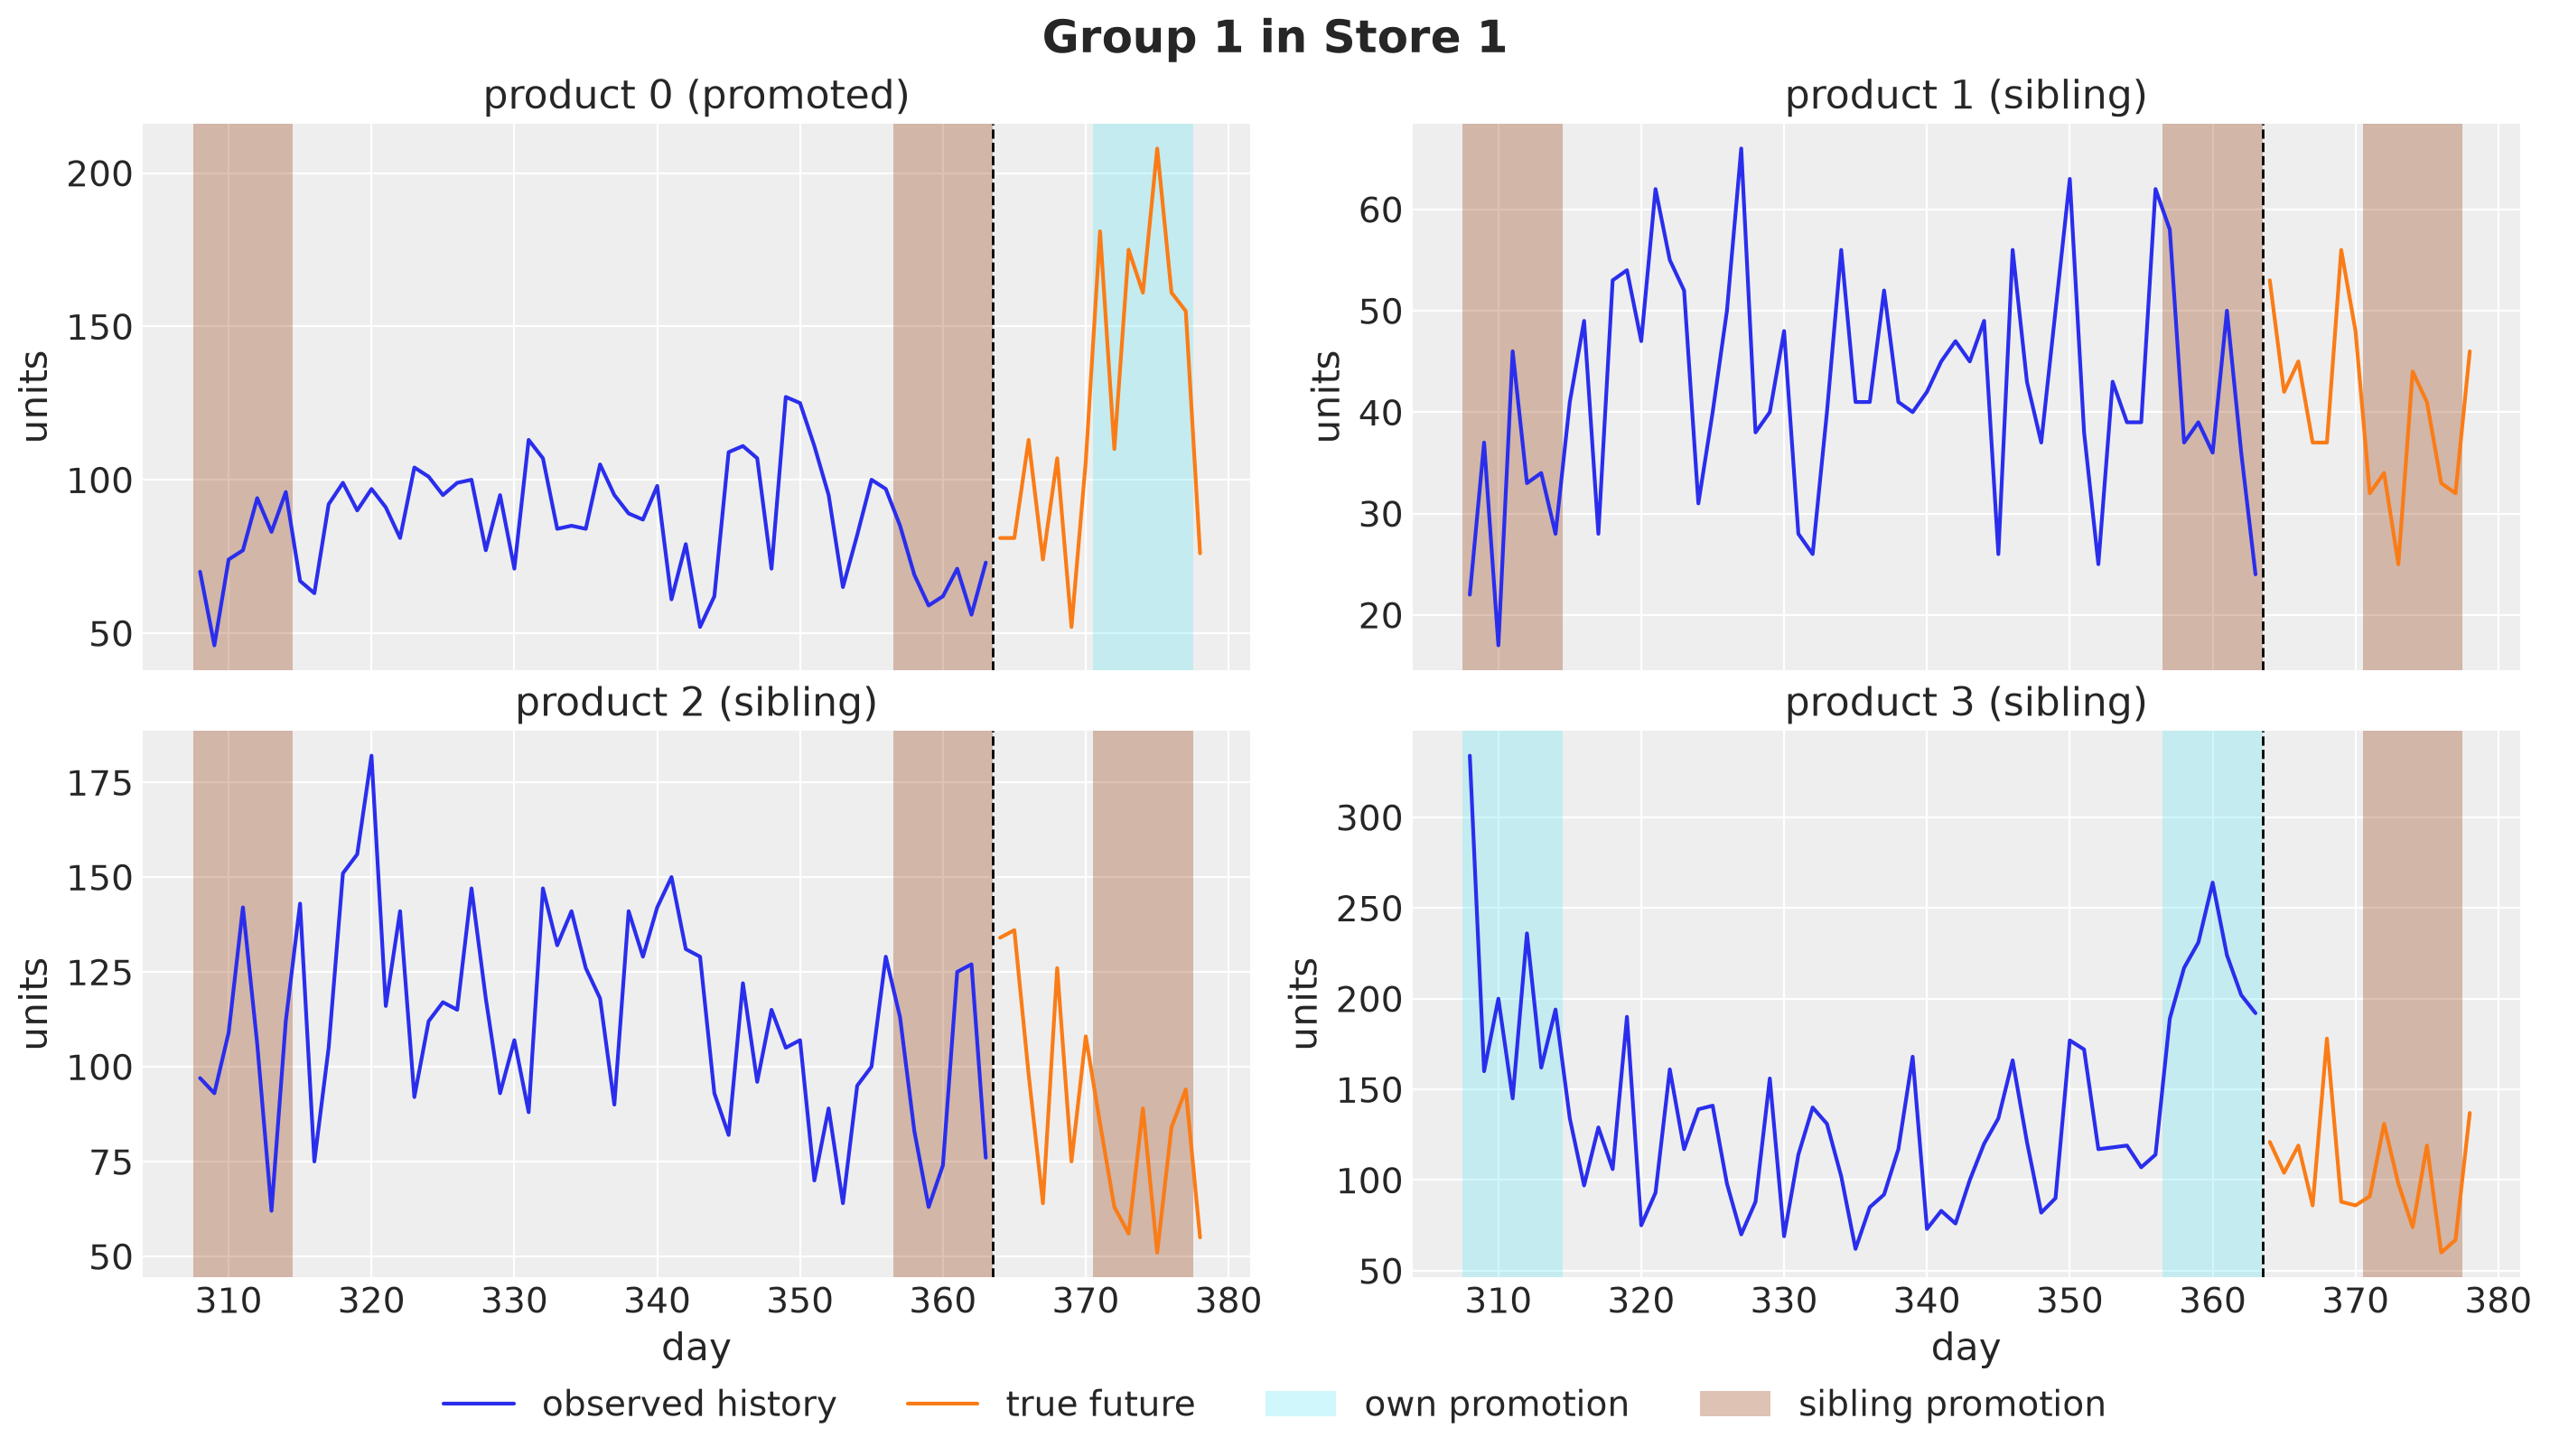

In [13]:
def shade_promotions(ax: plt.Axes, product: int, start: int, end: int) -> None:
    """Shade the own and the sibling promotion days of a product in [start, end)."""
    own = promo_full[start:end, product] > 0
    group = panel.product_to_group == panel.product_to_group[product]
    siblings = group & (np.arange(setup.n_products) != product)
    sibling_days = promo_full[start:end][:, siblings].sum(axis=1) > 0
    for mask, color, label in [
        (own, "C5", "own promotion"),
        (sibling_days, "C4", "sibling promotion"),
    ]:
        for d in np.flatnonzero(mask):
            ax.axvspan(
                start + d - 0.5,
                start + d + 0.5,
                color=color,
                alpha=0.3,
                lw=0,
                label=label,
            )


def dedupe_legend(fig: plt.Figure, ax: plt.Axes, ncol: int) -> None:
    """One legend entry per label, at the bottom of the figure."""
    handles, labels = ax.get_legend_handles_labels()
    unique = dict(zip(labels, handles, strict=True))
    fig.legend(unique.values(), unique.keys(), loc="outside lower center", ncol=ncol)


def plot_group(store: int, group: int, start: int = setup.t_obs - 56) -> None:
    """Demand of the four products of a group in a store, from `start` to the end."""
    group_products = np.flatnonzero(panel.product_to_group == group).tolist()
    fig, axes = plt.subplots(
        nrows=2, ncols=2, figsize=(14, 8), sharex=True, layout="constrained"
    )
    for ax, product in zip(axes.flat, group_products, strict=True):
        series = store * setup.n_products + product
        ax.plot(
            days[start : setup.t_obs],
            demand_full[start : setup.t_obs, series],
            color="C0",
            label="observed history",
        )
        ax.plot(
            days_future, demand_future_true[:, series], color="C1", label="true future"
        )
        ax.axvline(setup.t_obs - 0.5, color="black", linestyle="--", linewidth=1)
        shade_promotions(ax, product, start, setup.duration)
        ax.set(title=f"product {product} ({product_role[product]})", ylabel="units")
    for ax in axes[-1]:
        ax.set(xlabel="day")
    dedupe_legend(fig, axes[0, 0], ncol=4)
    fig.suptitle(
        f"Group {group + 1} in Store {store + 1}", fontsize=18, fontweight="bold"
    )


plot_group(store=0, group=0);

The promoted product jumps in the second week of the horizon, to about twice its level, and the three siblings dip in the same week. This is cannibalization in the data. The history shows the same pattern. Product $3$ was on promotion in the last week of the history, so that week is a sibling promotion week for products $0$, $1$ and $2$, and their demand was lower in that week. Keep this in mind, because the forecast of these three products starts right after a dip.

### Evaluation Scenarios

In the first post we scored the plans on held-out draws of the same posterior that built them. Those draws check a plan against new draws of the same forecast, not against the forecast being wrong. Here we can do better, because we know the true process. We draw $3{,}000$ futures from the generator with the true parameters and the realized level increments of the history fixed, so that only the future increments and the observation noise are fresh. These paths are the distribution of the true future given the history, and no posterior can produce them. We call them the **evaluation scenarios** and score every plan on them, which tests every plan against the misspecification of its model.

In [14]:
N_SCENARIOS_EVAL = 3_000

rng_key, key_eval = random.split(rng_key)
true_future_generator = do(generator, data={**true_params, "drift": drift_true})
demand_eval = Predictive(
    true_future_generator, num_samples=N_SCENARIOS_EVAL, return_sites=["forecast"]
)(key_eval, covariates, data)["forecast"].astype(jnp.float32)
assert demand_eval.shape == (N_SCENARIOS_EVAL, setup.horizon, setup.n_series)

## Forecasting Model

We fit two models to the same history. The **cross model** is the demand model of the previous section: the level per series, the weekly seasonality, the own elasticity and the concentration per product, and the cross elasticities within each group. The **independent model** is the same model without the cross-price term, so it is the model of the first post applied to every series, with the seasonality, the elasticity and the concentration shared by the stores of a product.

The following graph shows the two paths from a promotion to the demand of a group of two products. The price of product A moves its own demand through the own elasticity and the demand of product B through the cross elasticity. The red arrows are what the independent model drops.

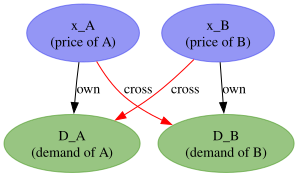

In [15]:
dag = gr.Digraph()
dag.node("xA", label="x_A\n(price of A)", color="#2a2eec80", style="filled")
dag.node("xB", label="x_B\n(price of B)", color="#2a2eec80", style="filled")
dag.node("DA", label="D_A\n(demand of A)", color="#328c0680", style="filled")
dag.node("DB", label="D_B\n(demand of B)", color="#328c0680", style="filled")
dag.edge("xA", "DA", label="own")
dag.edge("xB", "DB", label="own")
dag.edge("xA", "DB", label="cross", color="red")
dag.edge("xB", "DA", label="cross", color="red")
dag

The independent model keeps the two black arrows only.

Here is an important observation: the independent model is misspecified on the history, not only on the horizon. In the history, a product loses $10\%$ to $19\%$ of its demand in every week in which a sibling is on promotion. The independent model has no term for these dips, so it has to explain them with the two things it has, the level of the series and the noise of the likelihood. We check in the *Parameter Recovery* section what this does to its estimates.

Both models take the same covariates and data. Let's build them and render the cross model on the training window.

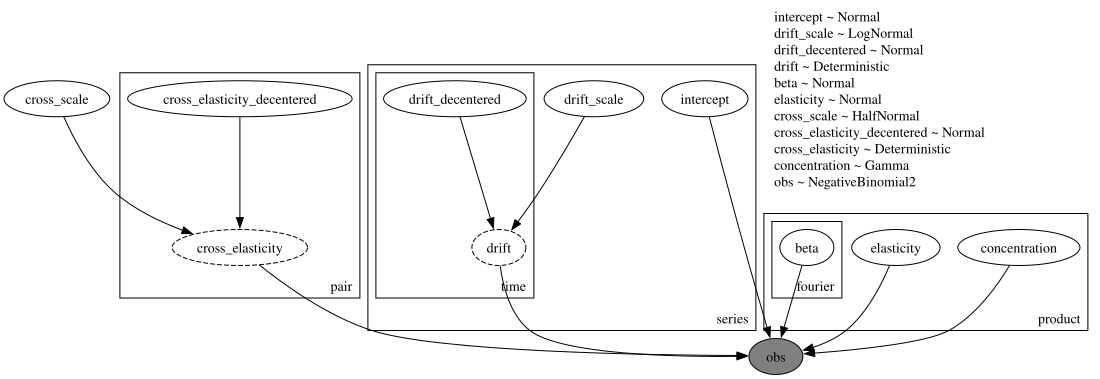

In [16]:
model_independent = make_demand_model(panel, setup, priors, cross=False)
model_cross = make_demand_model(panel, setup, priors, cross=True)
MODEL_COLORS = {"independent": "C3", "cross": "C2"}

numpyro.render_model(
    model_cross,
    model_args=(covariates_train, data),
    render_distributions=True,
    render_params=False,
)

The `series` plate holds the level, the `product` plate the seasonality, the own elasticity and the concentration, and the `pair` plate the $60$ cross elasticities under their common scale. Inside the `time` plate we see `drift_decentered`, the standardized increments that the `LocScaleReparam` samples.

## Prior Predictive Checks

Before we fit the models, we draw demand paths from the priors of the cross model and compare them with the training data. We plot the $50\%$ and $94\%$ equal-tailed intervals (ETI) of $300$ draws for the first product of groups $1$ to $4$ in store $1$, on a log axis because the log link gives the prior a long upper tail. As in the first post, every band of this notebook is an equal-tailed interval, which runs between two percentiles.

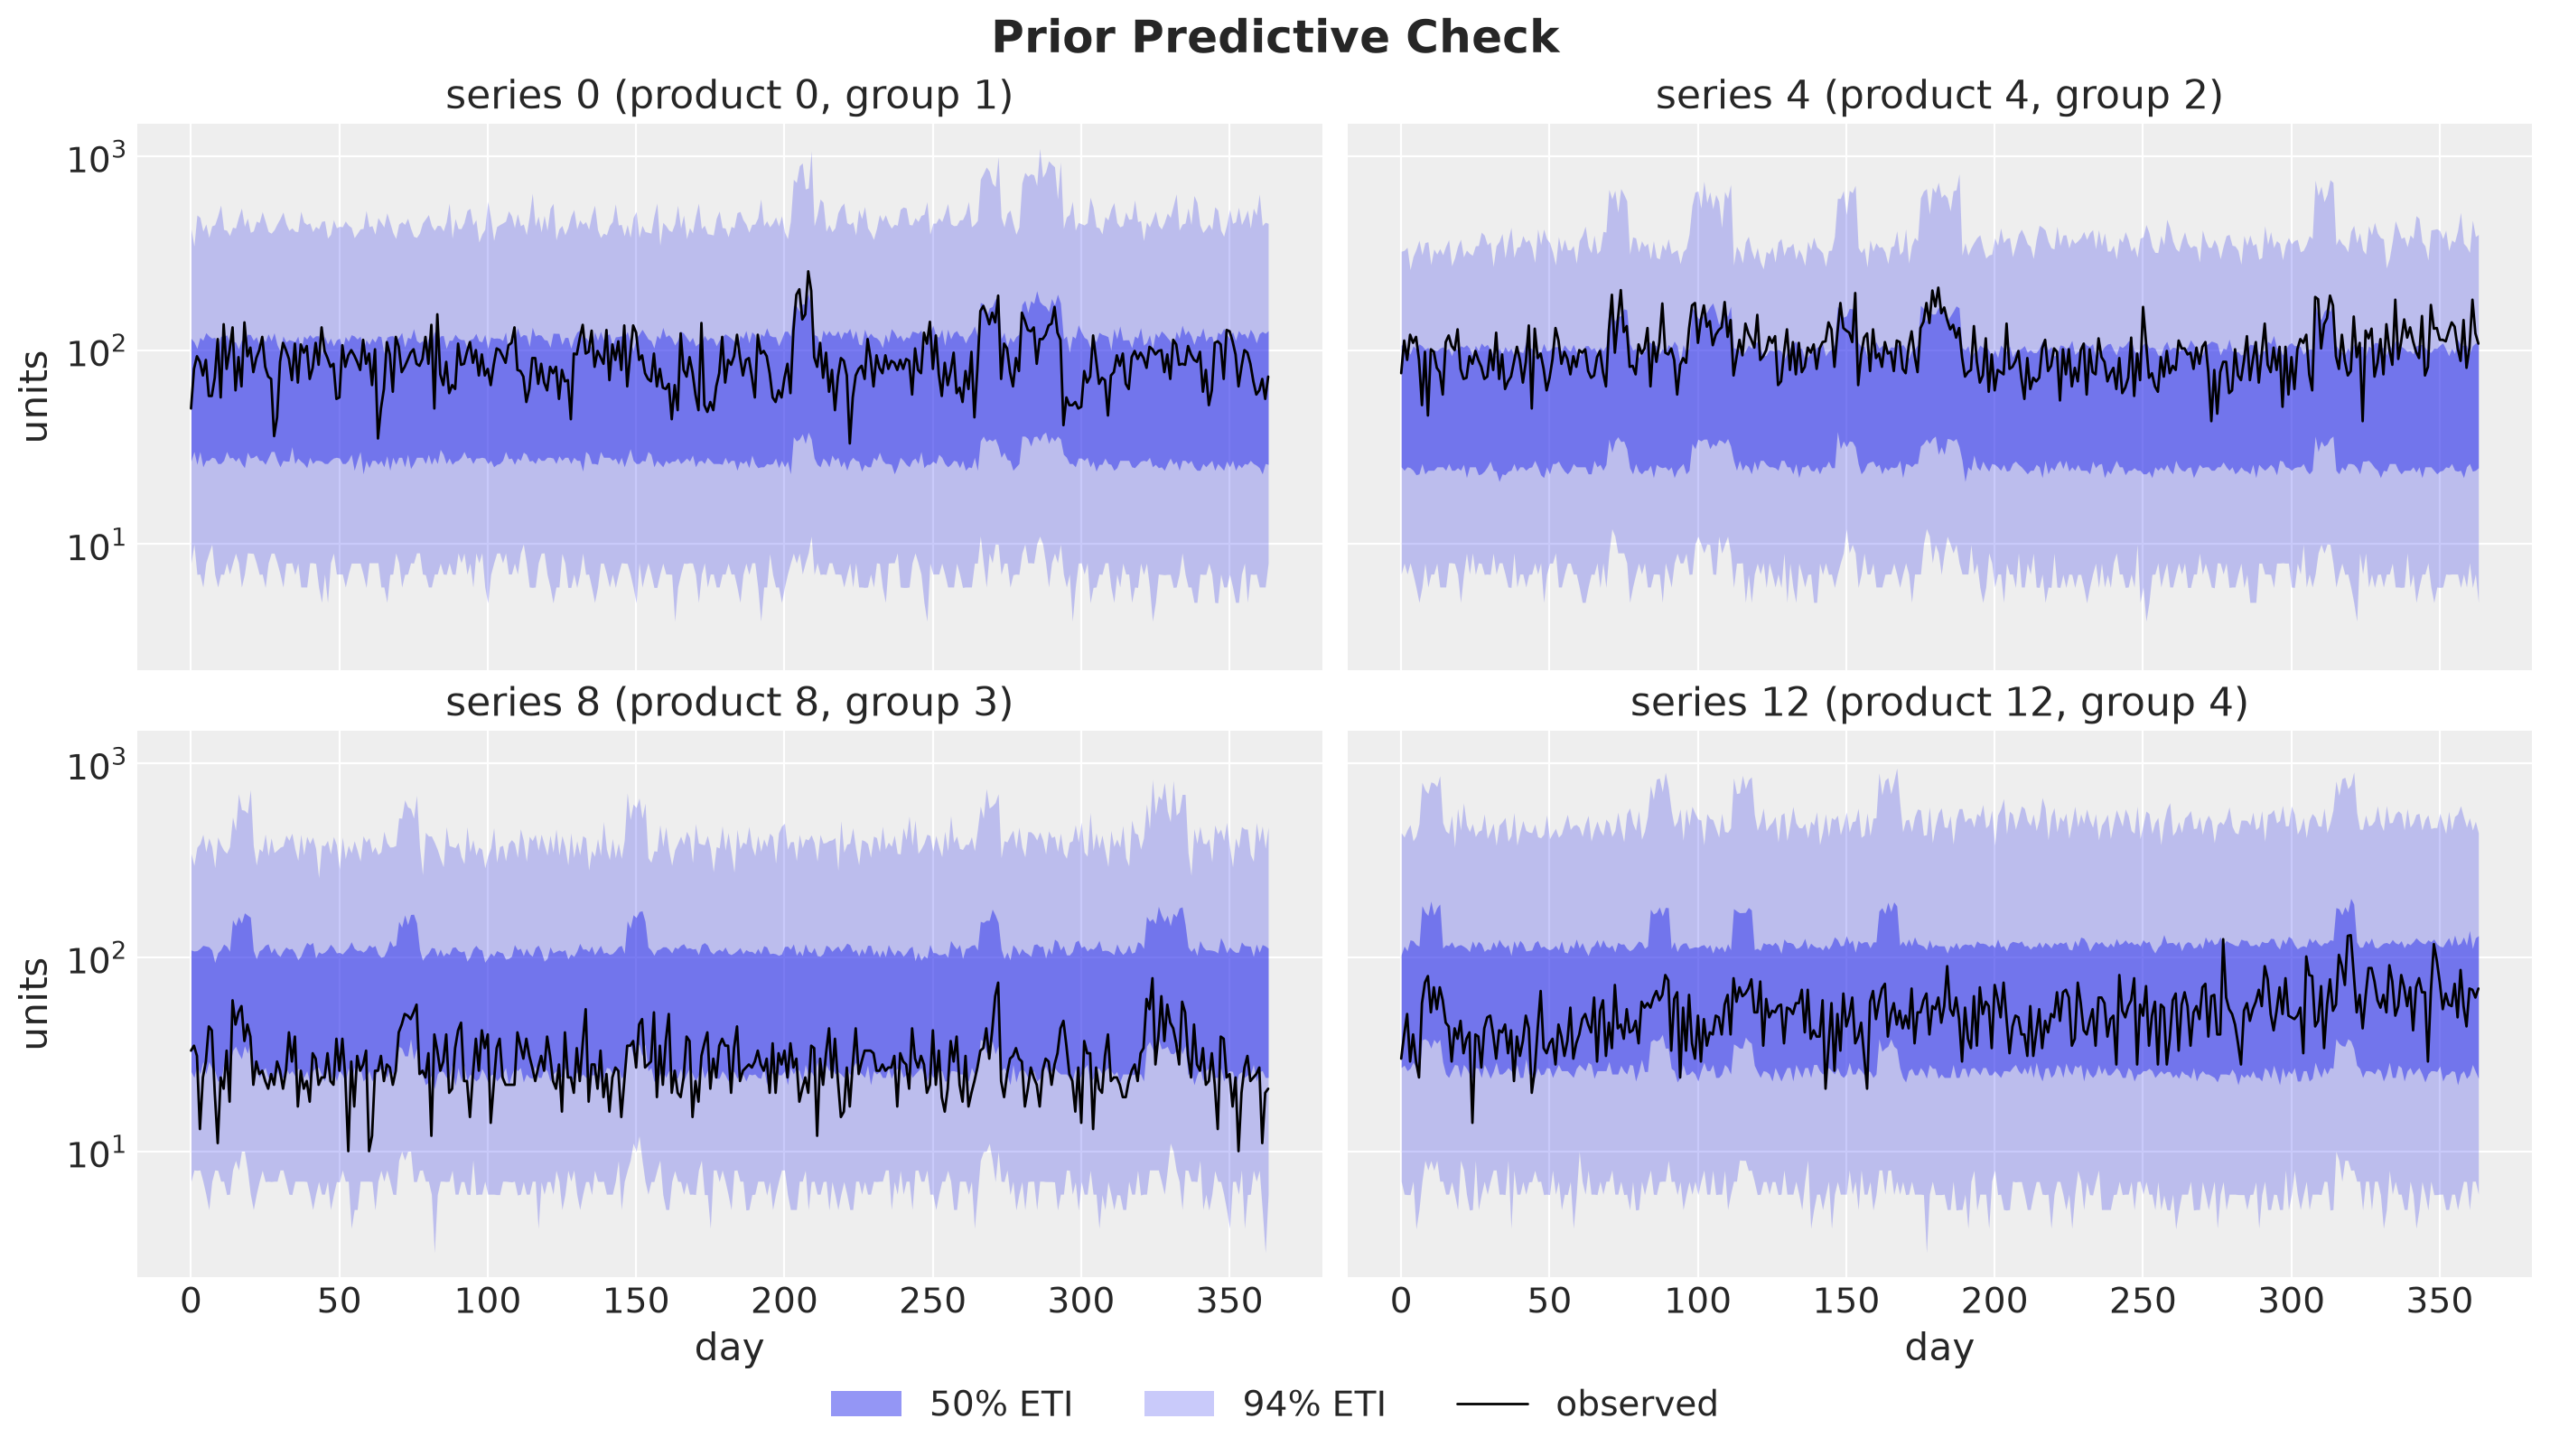

In [17]:
def lighten_bands(
    pc: az.PlotCollection, x: str, prob_alpha: tuple = ((0.5, 0.5), (CI_PROB, 0.25))
) -> None:
    """Set the alpha of the credible bands of a `plot_lm` collection."""
    bands = pc.viz["ci_band"][x]
    for prob, alpha in prob_alpha:
        for band in bands.sel(prob=prob).values.flat:
            band.set_alpha(alpha)


rng_key, key_prior = random.split(rng_key)
prior_obs = Predictive(model_cross, num_samples=300, return_sites=["obs"])(
    key_prior, covariates_train
)["obs"]
check_series = np.arange(4) * setup.n_per_group  # the first product of groups 1 to 4
check_labels = [
    f"series {i} (product {i}, group {g + 1})" for g, i in enumerate(check_series)
]

prior_tree = az.from_dict(
    {
        "prior_predictive": {
            "obs": prior_obs[None][..., check_series].transpose(0, 1, 3, 2)
        },
        "observed_data": {"obs": data[:, check_series].T},
        "constant_data": {"day": np.tile(days[: setup.t_obs].astype(float), (4, 1))},
    },
    coords={"series": check_labels, "time": days[: setup.t_obs]},
    dims={"obs": ["series", "time"], "day": ["series", "time"]},
)

pc = az.plot_lm(
    prior_tree,
    x="day",
    y="obs",
    y_obs="obs",
    plot_dim="time",
    group="prior_predictive",
    smooth=False,
    ci_prob=(0.5, CI_PROB),
    visuals={
        "ci_band": {"color": "C0"},
        "observed_scatter": False,
        "pe_line": False,
        "xlabel": False,
        "ylabel": False,
    },
    col_wrap=2,
    figure_kwargs={"figsize": (14, 8), "sharex": True, "sharey": True},
)
lighten_bands(pc, "day")
for k, label in enumerate(check_labels):
    ax = pc.get_target("day", {"series": label})
    bands = pc.viz["ci_band"]["day"].sel(series=label)
    bands.sel(prob=0.5).item().set_label("50% ETI")
    bands.sel(prob=CI_PROB).item().set_label(f"{CI_PROB:.0%} ETI")
    ax.plot(
        days[: setup.t_obs],
        data[:, check_series[k]],
        color="black",
        linewidth=1,
        label="observed",
    )
    ax.set(
        title=label,
        yscale="log",
        xlabel="day" if k >= 2 else "",
        ylabel="units" if k % 2 == 0 else "",
    )
fig = pc.viz["figure"].item()
fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle("Prior Predictive Check", fontsize=18, fontweight="bold");

The priors put the demand on the right scale and not much more. The $94\%$ band runs from about $7$ units to between $360$ and $500$ units on a typical day, the $50\%$ band from about $25$ to about $110$ units, and the four observed series stay inside the wide band on every day. The bumps of the bands are the own promotion weeks of each product, which the log price moves through the own elasticity. Nothing here is implausible for products that sell tens of units per day, so we move on to the fit.

## Model Fitting

### Variational Inference

Each model has about $73K$ latent variables, $72{,}800$ of them the level increments of the $200$ series, which puts NUTS out of reach for a notebook and makes the comparison of two models cheap with stochastic variational inference (SVI). We use a mean-field Normal guide, `AutoNormal`, which gives every latent variable its own Normal and ignores the posterior correlations. A guide of this form tends to underestimate the posterior variance, see [Blei, Kucukelbir and McAuliffe (2017)](https://doi.org/10.1080/01621459.2017.1285773), and the level increments of a random walk and their scale are correlated a posteriori, so we expect it to be too narrow somewhere.

Instead of the convergence diagnostics of NUTS we run three checks, which the synthetic data make possible:

1. **The loss trace.** The negative ELBO has to settle.
2. **Parameter recovery.** The posterior has to cover the true parameters, including the level at the end of the history that the forecast starts from.
3. **Forecast width.** The predictive distribution has to be as wide as the true future, which we measure against the evaluation scenarios.

The function `fit_svi` runs `Adam` on the ELBO for a fixed number of steps and returns the guide and the result. We initialize at the median of a few prior draws.

In [18]:
def fit_svi(
    model: ForecastModel, rng_key: PRNGKeyArray, num_steps: int = 10_000
) -> tuple[AutoNormal, SVIRunResult]:
    """Fit a mean-field Normal guide to `model` on the training window."""
    guide = AutoNormal(model, init_loc_fn=init_to_median(num_samples=15))
    svi = SVI(model, guide, Adam(step_size=0.01), Trace_ELBO())
    result = svi.run(rng_key, num_steps, covariates_train, data, progress_bar=False)
    return guide, result

### Choosing the Parameterization

The random walk of every series can be written in two bases. The plain one samples the $364$ standardized increments of the series one by one. The `time_reparam` wrapper of `numpyro_forecast`, a port of the `time_reparam` option of Pyro's [forecasting module](https://docs.pyro.ai/en/stable/contrib.forecast.html), samples their discrete cosine transform (DCT) instead. The transform is orthonormal, so the model is the same. What changes is the geometry that the guide sees: the increments of a random walk are correlated a posteriori, because the data pin down their partial sums, and the cosine basis is one in which they are less correlated, which is where a mean-field guide loses the least.

We fit the cross model both ways, with the same key and the same number of steps, and compare the loss and the recovery of two parameters: the drift scale and the concentration. We also draw $1{,}000$ posterior samples of each fit with `draw_posterior` and forecast the horizon with `forecast`, so that we can score the forecast of each basis on the realized future.

In [19]:
%%time

N_SVI_STEPS = 10_000
N_SCENARIOS_OPT = 1_000

basis_models = {"plain": model_cross, "dct": time_reparam(model_cross, "dct")}
rng_key, key_svi = random.split(rng_key)
basis_fits = {
    name: fit_svi(model, key_svi, N_SVI_STEPS) for name, model in basis_models.items()
}

CPU times: user 1min 40s, sys: 38.6 s, total: 2min 18s
Wall time: 29.4 s


In [20]:
def latent_sites(guide: AutoNormal) -> list[str]:
    """Names of the sample sites of the guide, without the deterministic copies."""
    return [
        name
        for name, site in guide.prototype_trace.items()
        if site["type"] == "sample" and not site["is_observed"]
    ]


def draw_fit(
    rng_key: PRNGKeyArray, model: ForecastModel, guide: AutoNormal, result: SVIRunResult
) -> tuple[
    dict[str, Array],
    Float[Array, "sample n_series"],
    Float[Array, "sample horizon n_series"],
]:
    """Posterior draws, level of every series at the end of history, and forecast."""
    key_draw, key_forecast = random.split(rng_key)
    draws = draw_posterior(key_draw, guide, result.params, N_SCENARIOS_OPT)
    level_end = draws["intercept"] + draws["drift"].sum(axis=1)
    # `forecast` rebuilds the increments from their sampled site, so it needs the
    # sample sites only, not the deterministic copies that `draw_posterior` returns
    posterior = {name: draws[name] for name in latent_sites(guide)}
    scenarios = forecast(
        key_forecast, model, posterior, data, covariates, batch_size=250
    ).astype(jnp.float32)
    # for the analysis we keep the parameters on their natural scale and drop the
    # increments, which are 1,000 x 364 x 200 floats per site
    draws = {k: v for k, v in draws.items() if v.shape[1:2] != (setup.t_obs,)}
    return draws, level_end, scenarios


level_end_true = np.asarray(true_params["intercept"] + drift_true.sum(axis=0))
basis_draws = {}
for name, (guide, result) in basis_fits.items():
    rng_key, key_fit = random.split(rng_key)
    basis_draws[name] = draw_fit(key_fit, basis_models[name], guide, result)


def recovery_ratio(
    draws: Float[Array | np.ndarray, " sample *shape"],
    truth: Float[Array | np.ndarray, " *shape"],
) -> float:
    """Median over the entries of the posterior mean divided by the truth."""
    draws, truth = np.asarray(draws), np.asarray(truth)
    nonzero = truth != 0
    return float(np.median(draws.mean(axis=0)[nonzero] / truth[nonzero]))


basis_check = pl.DataFrame(
    [
        {
            "basis": name,
            "negative ELBO": float(np.asarray(result.losses[-500:]).mean()),
            "drift_scale: posterior mean / truth": recovery_ratio(
                posterior["drift_scale"], true_params["drift_scale"]
            ),
            "concentration: posterior mean / truth": recovery_ratio(
                posterior["concentration"], true_params["concentration"]
            ),
            "level at end: error sd": float(
                (level_end.mean(axis=0) - level_end_true).std()
            ),
            "CRPS on the realized future": float(
                crps_empirical(scenarios, demand_future_true).mean()
            ),
            f"coverage {CI_PROB:.0%}": float(
                eval_coverage(scenarios, demand_future_true, alpha=CI_PROB)
            ),
        }
        for (name, (guide, result)), (posterior, level_end, scenarios) in zip(
            basis_fits.items(), basis_draws.values(), strict=True
        )
    ]
)
basis_check

basis,negative ELBO,drift_scale: posterior mean / truth,concentration: posterior mean / truth,level at end: error sd,CRPS on the realized future,coverage 94%
str,f64,f64,f64,f64,f64,f64
"""plain""",300339.1875,0.282208,0.877004,0.081423,10.021811,0.95
"""dct""",297822.46875,0.904532,0.978378,0.056332,9.656346,0.945


The DCT basis wins on the columns that matter for the plan. The plain basis puts the drift scale at $28\%$ of its true value and the concentration $12\%$ too low, so it explains the day-to-day movement of the series with noise instead of with the level. The DCT basis recovers the concentration ($98\%$ of the truth) and most of the drift scale ($90\%$), reaches a negative ELBO about $2{,}500$ nats lower, and its posterior mean of the level at the end of the history is closer to the truth (an error standard deviation of $0.056$ against $0.081$ on the log scale). The two forecasts of the realized future are close on coverage and CRPS, because the observation noise dominates a single day, but the level is what the plan starts from, so we keep the DCT fit.

### Fitting Both Models

We fit the independent model in the DCT basis with the same settings and keep the two DCT fits from here on: the guides, the posterior draws, the level of every series at the end of the history, and the forecast scenarios.

In [21]:
%%time

models = {
    "independent": time_reparam(model_independent, "dct"),
    "cross": basis_models["dct"],
}
guides = {"cross": basis_fits["dct"][0]}
svi_results = {"cross": basis_fits["dct"][1]}
guides["independent"], svi_results["independent"] = fit_svi(
    models["independent"], key_svi, N_SVI_STEPS
)

posteriors: dict[str, dict[str, Array]] = {"cross": basis_draws["dct"][0]}
level_end: dict[str, Array] = {"cross": basis_draws["dct"][1]}
scenarios: dict[str, Array] = {"cross": basis_draws["dct"][2]}
rng_key, key_fit = random.split(rng_key)
posteriors["independent"], level_end["independent"], scenarios["independent"] = (
    draw_fit(
        key_fit,
        models["independent"],
        guides["independent"],
        svi_results["independent"],
    )
)
for name in models:
    assert scenarios[name].shape == (N_SCENARIOS_OPT, setup.horizon, setup.n_series)

CPU times: user 1min 54s, sys: 40.4 s, total: 2min 34s
Wall time: 30.6 s


The following figure shows the loss of the two fits after the first fifth of the steps, where the scale of the first steps no longer hides the end of the trace. The legend carries the mean of the last $500$ steps of each trace.

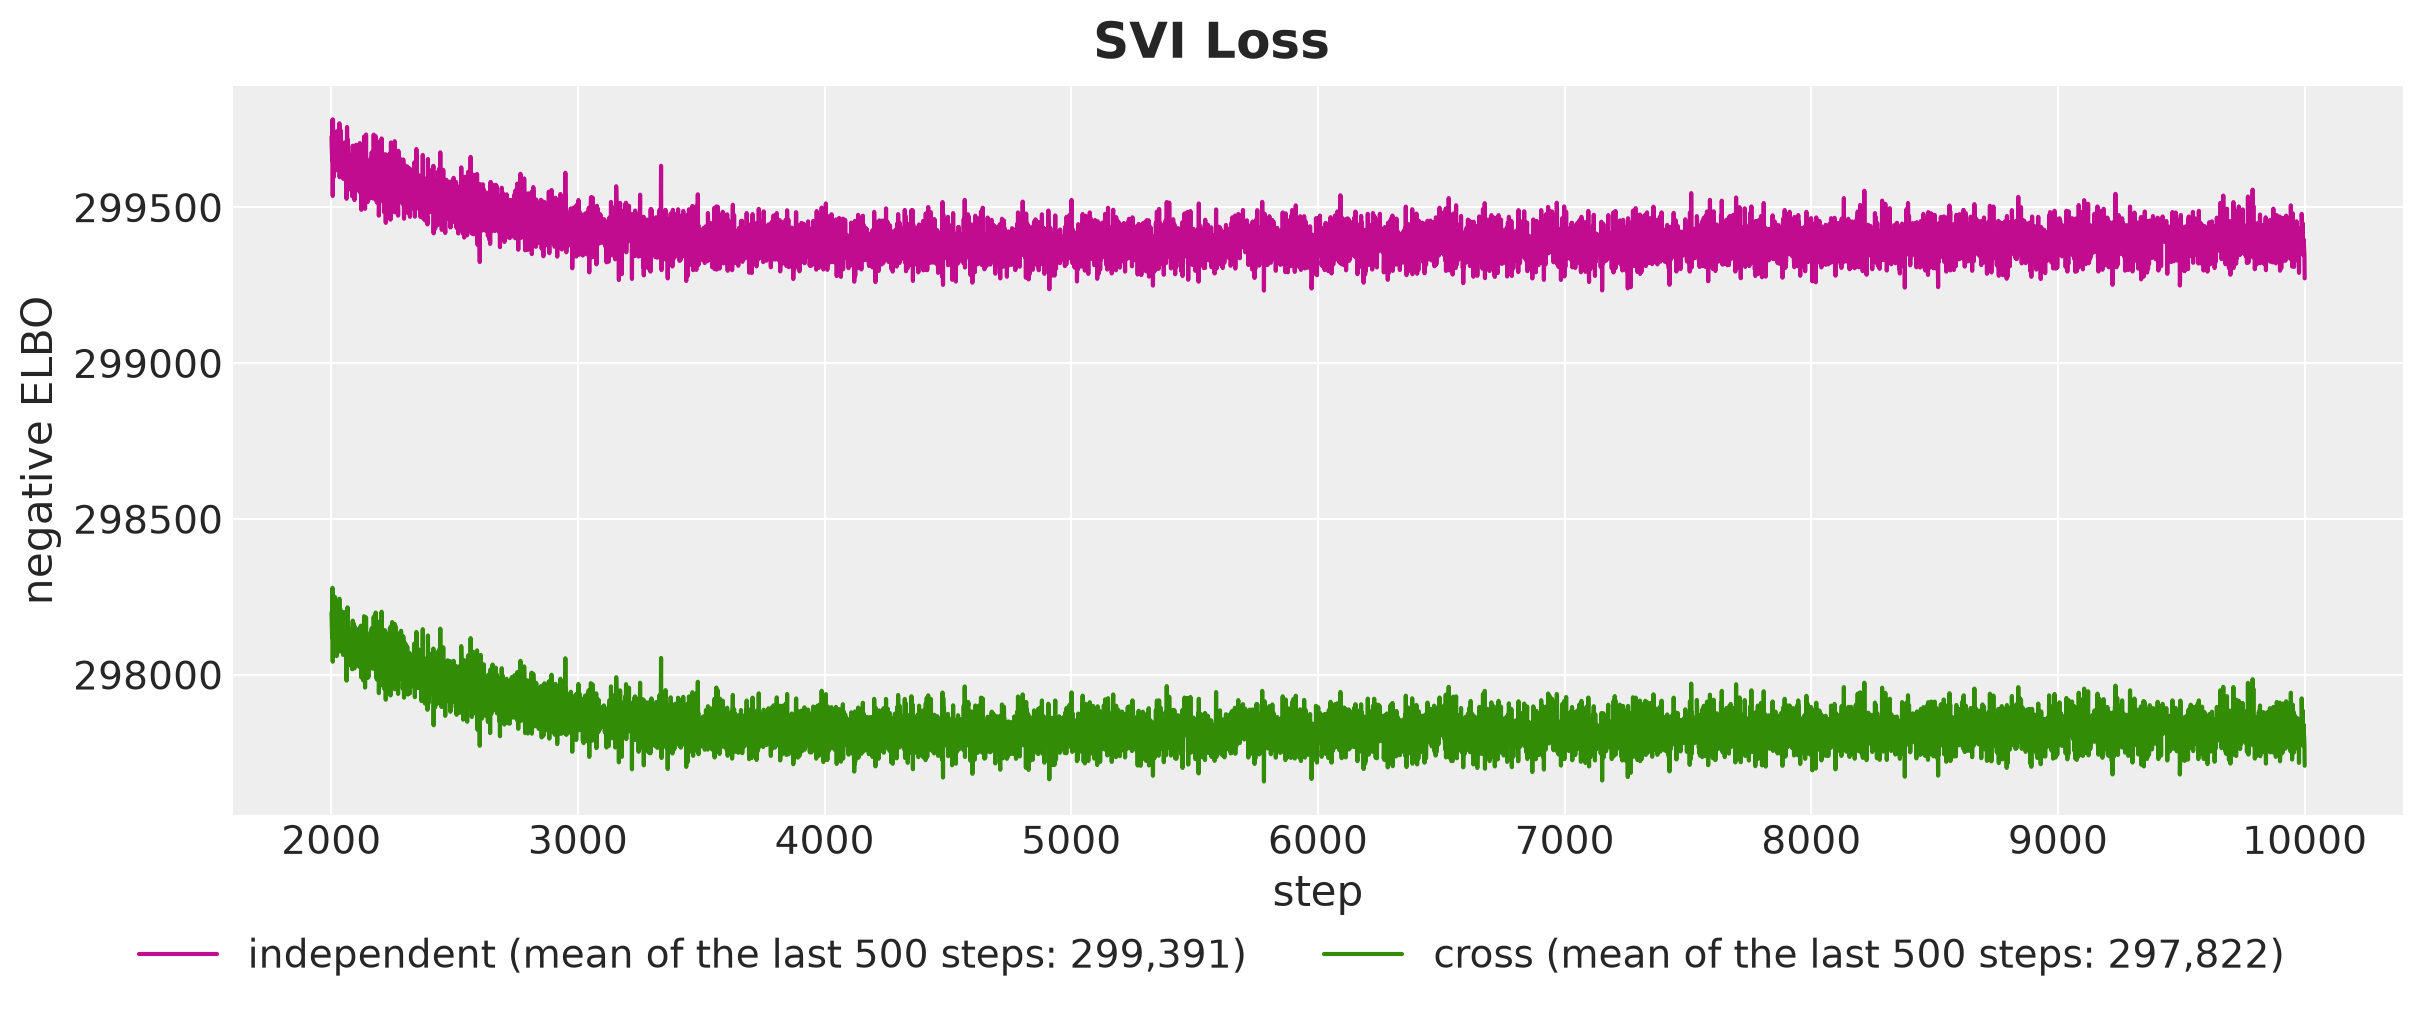

In [22]:
fig, ax = plt.subplots(figsize=(12, 5))
for name in models:
    losses = np.asarray(svi_results[name].losses)
    steps = np.arange(1, losses.size + 1)
    keep = steps > N_SVI_STEPS // 5
    ax.plot(
        steps[keep],
        losses[keep],
        color=MODEL_COLORS[name],
        label=f"{name} (mean of the last 500 steps: {losses[-500:].mean():,.0f})",
    )
ax.set(xlabel="step", ylabel="negative ELBO")
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle("SVI Loss", fontsize=18, fontweight="bold");

Both traces flatten after about $4{,}000$ steps and move within the noise of the single-sample ELBO estimate after that. The cross model ends about $1{,}600$ nats lower than the independent model, at $297{,}823$ against $299{,}391$, which is the fit it gains from the cross-price term on the same data.

Next, let's look at the posterior summary of the cross model for the product-level parameters. The draws come from one guide, so we show the point estimates and the intervals only.

In [23]:
coords = {
    "product": np.arange(setup.n_products),
    "pair": [
        f"{k}->{j}" for k, j in zip(panel.pair_rows, panel.pair_cols, strict=True)
    ],
    "series": np.arange(setup.n_series),
}
dims = {
    "elasticity": ["product"],
    "concentration": ["product"],
    "intercept": ["series"],
    "drift_scale": ["series"],
    "cross_elasticity": ["pair"],
    "cross_scale": [],
}
idata_cross = az.from_dict(
    {
        "posterior": {
            k: np.asarray(v)[None] for k, v in posteriors["cross"].items() if k in dims
        }
    },
    coords=coords,
    dims=dims,
)
az.summary(
    idata_cross,
    var_names=["cross_scale", "concentration", "elasticity"],
    kind="stats",
)

,mean,sd,eti94_lb,eti94_ub
cross_scale,0.31,0.0037,0.3,0.32
concentration[0],28,0.88,26,29
concentration[1],34,1.3,31,36
concentration[2],27,0.73,26,28
concentration[3],29,0.81,27,30
concentration[4],28,0.9,27,30
concentration[5],24,0.97,23,26
concentration[6],40,1.6,37,43
concentration[7],34,1.7,31,38
concentration[8],23,0.92,21,24


The common scale of the cross elasticities, `cross_scale`, sits at $0.31$, close to the root mean square of the $60$ true cross elasticities ($0.33$). The concentrations lie between $20$ and $40$ and the own elasticities between $-1.9$ and $-1.0$, the ranges we drew the truth from, and the intervals are narrow: a year of daily data per series and a handful of promotion weeks per product pin them down.

## Parameter Recovery

### Elasticities

First, the own elasticities. We plot the posterior of `elasticity` minus its true value for every product and both models, so that a well-recovered parameter has an interval that covers zero.

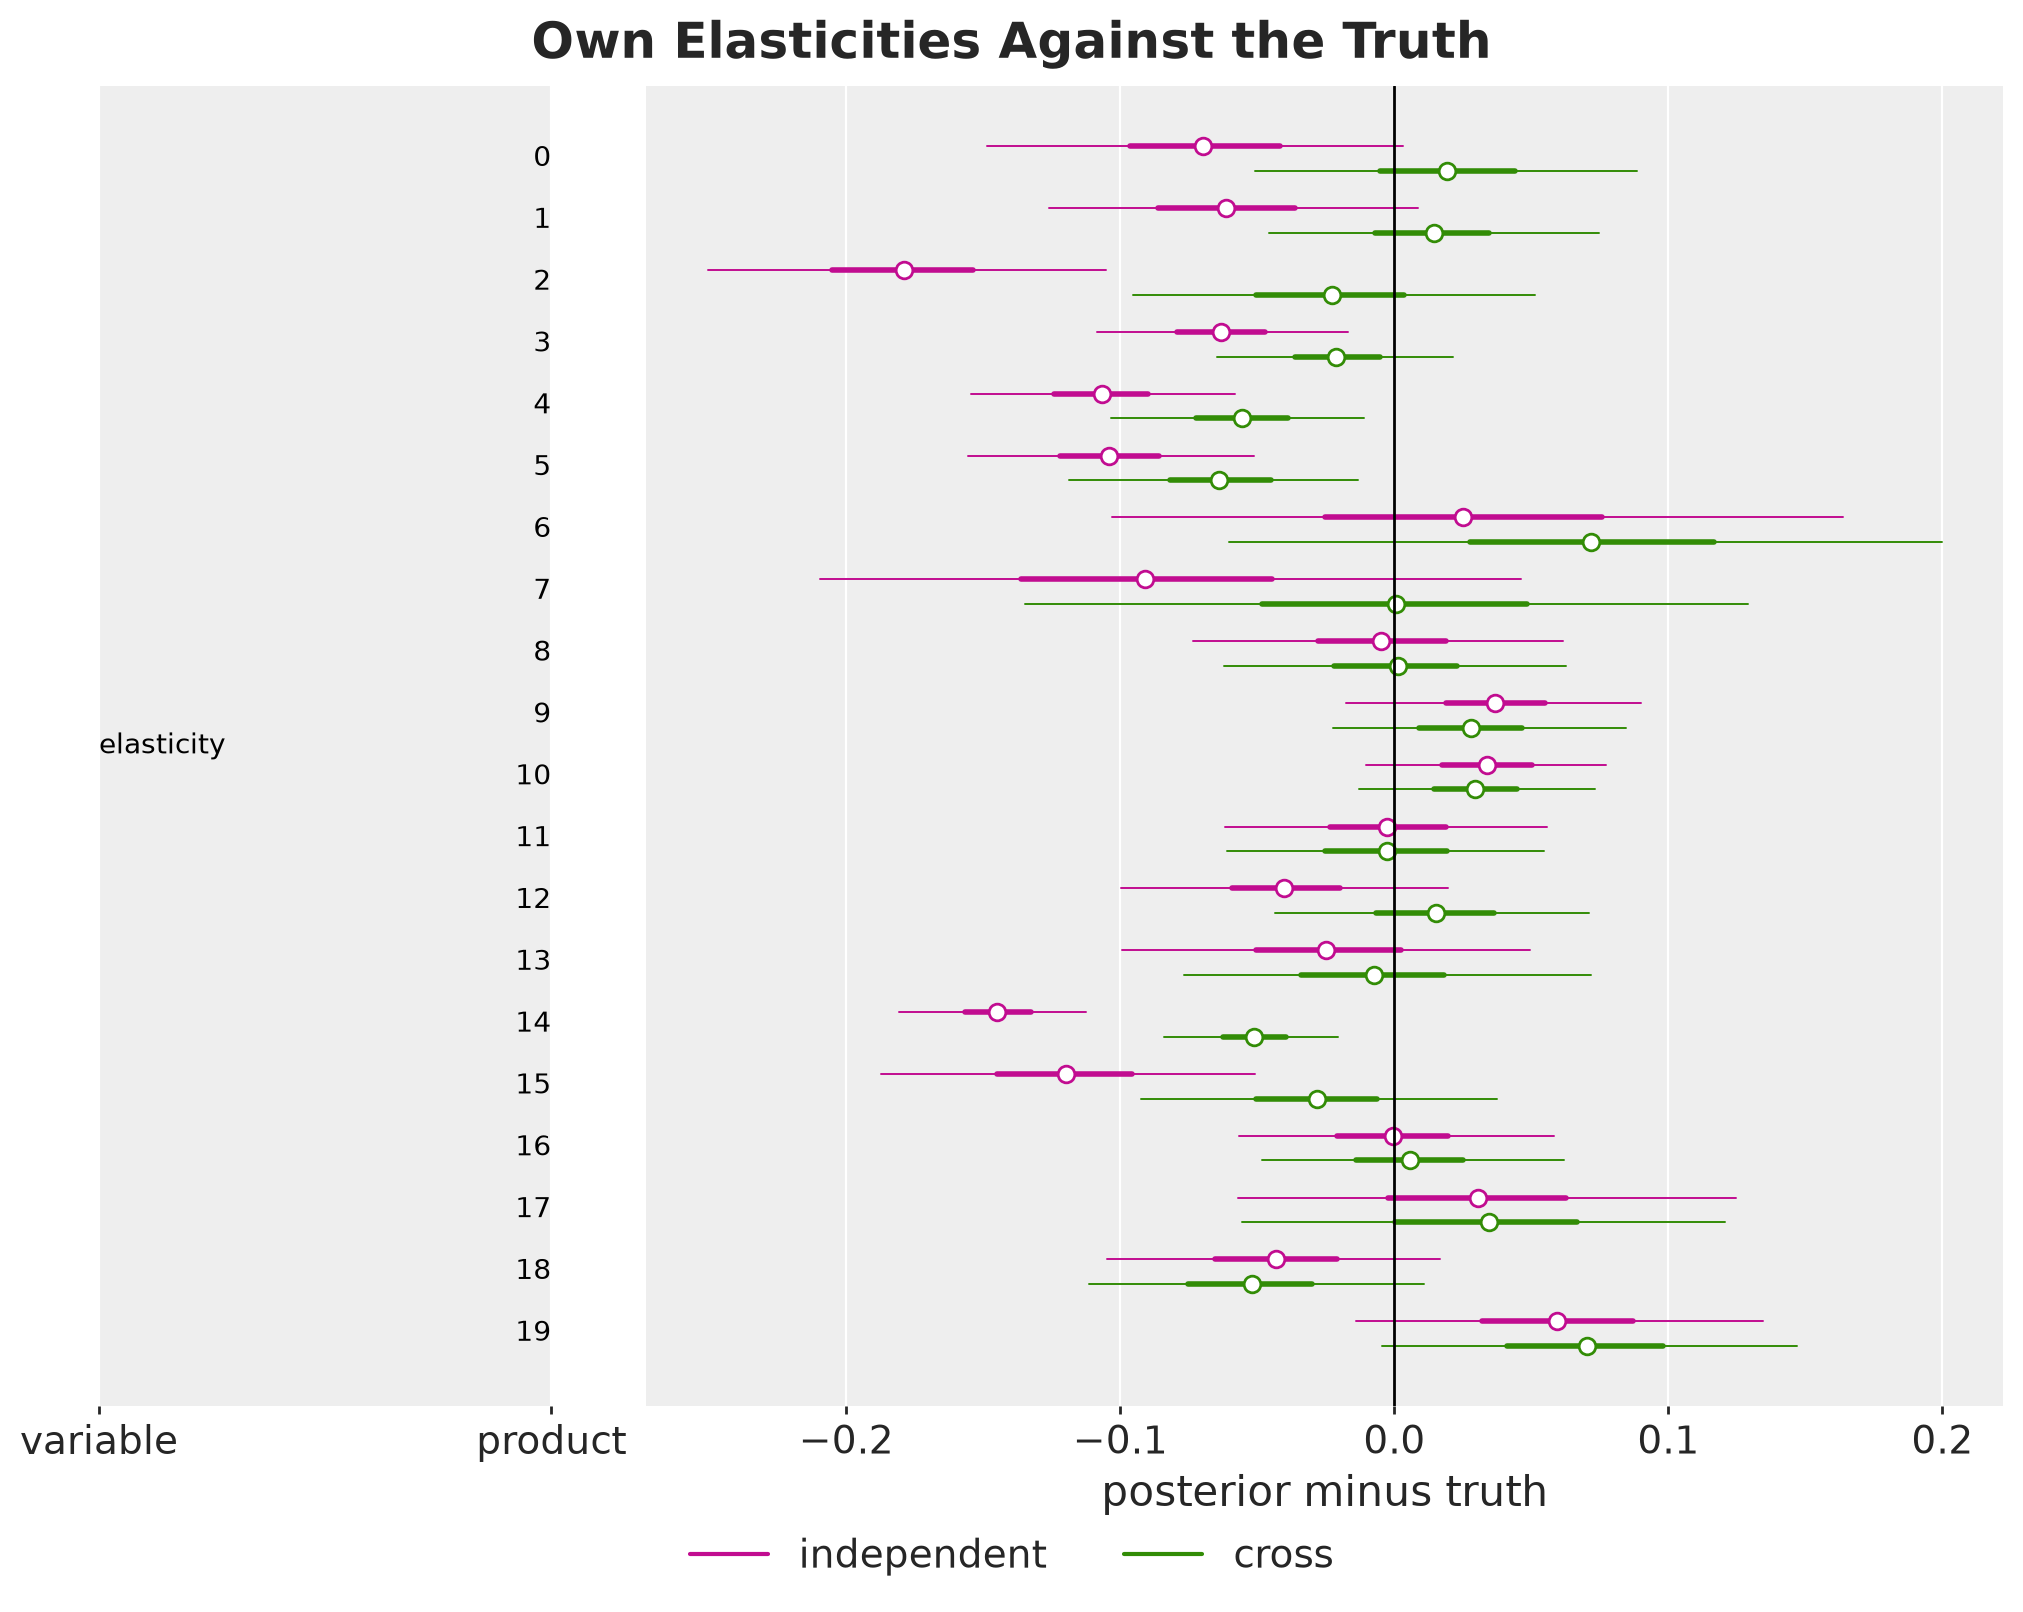

In [24]:
def minus_truth(name: str, site: str, dim: str) -> xr.Dataset:
    """Posterior draws of `site` under model `name` minus the true value."""
    return xr.Dataset(
        {
            site: (
                ("sample", dim),
                np.asarray(posteriors[name][site] - true_params[site]),
            )
        }
    )


pc = az.plot_forest(
    {name: minus_truth(name, "elasticity", "product") for name in models},
    sample_dims=["sample"],
    color=[MODEL_COLORS[name] for name in models],
    figure_kwargs={"figsize": (10, 8)},
)
ax = pc.viz["plot"].sel(column="forest").item()
ax.axvline(0.0, color="black", linewidth=1)
ax.set(xlabel="posterior minus truth")
pc.add_legend("model", title="", loc="outside lower center", ncol=2)
pc.viz["figure"].item().suptitle(
    "Own Elasticities Against the Truth", fontsize=18, fontweight="bold"
);

The dots are the posterior means and the thick and thin bars the $50\%$ and $94\%$ intervals. The following table averages the posterior mean minus the truth over the four products of each group, for both models.

In [25]:
pl.DataFrame(
    {
        "model": list(models),
        **{
            f"group {g + 1}": [
                float(
                    np.asarray(
                        posteriors[name]["elasticity"] - true_params["elasticity"]
                    )
                    .mean(axis=0)[panel.product_to_group == g]
                    .mean()
                )
                for name in models
            ]
            for g in range(setup.n_groups)
        },
    }
)

model,group 1,group 2,group 3,group 4,group 5
str,f64,f64,f64,f64,f64
"""independent""",-0.093296,-0.069191,0.015781,-0.08255,0.01158
"""cross""",-0.002603,-0.011829,0.014048,-0.01793,0.014669


Here is what we see.

- **Cross model.** The intervals cover zero for $17$ of the $20$ products, and the posterior means sit within $0.02$ of the truth on average in every group.
- **Independent model.** The intervals cover zero for $14$ products, and the misses are not random. The own elasticities of groups $1$, $2$ and $4$ are $0.07$ to $0.09$ too negative on average, and those of groups $3$ and $5$, the groups without cannibalization, are within $0.02$ of the truth. This is the first trace of the sibling promotions: the level of the independent model sits below the no-promotion level, because it averages over the dips, so a promotion week of the product looks like a larger lift than it is.

Next, the cross elasticities of the cross model, in the same form: the posterior of every within-group pair minus its true value, with the pairs of each group under its own heading. The true values are $0.6$, $0.3$, $0$, $0.3$ and $0$ for groups $1$ to $5$.

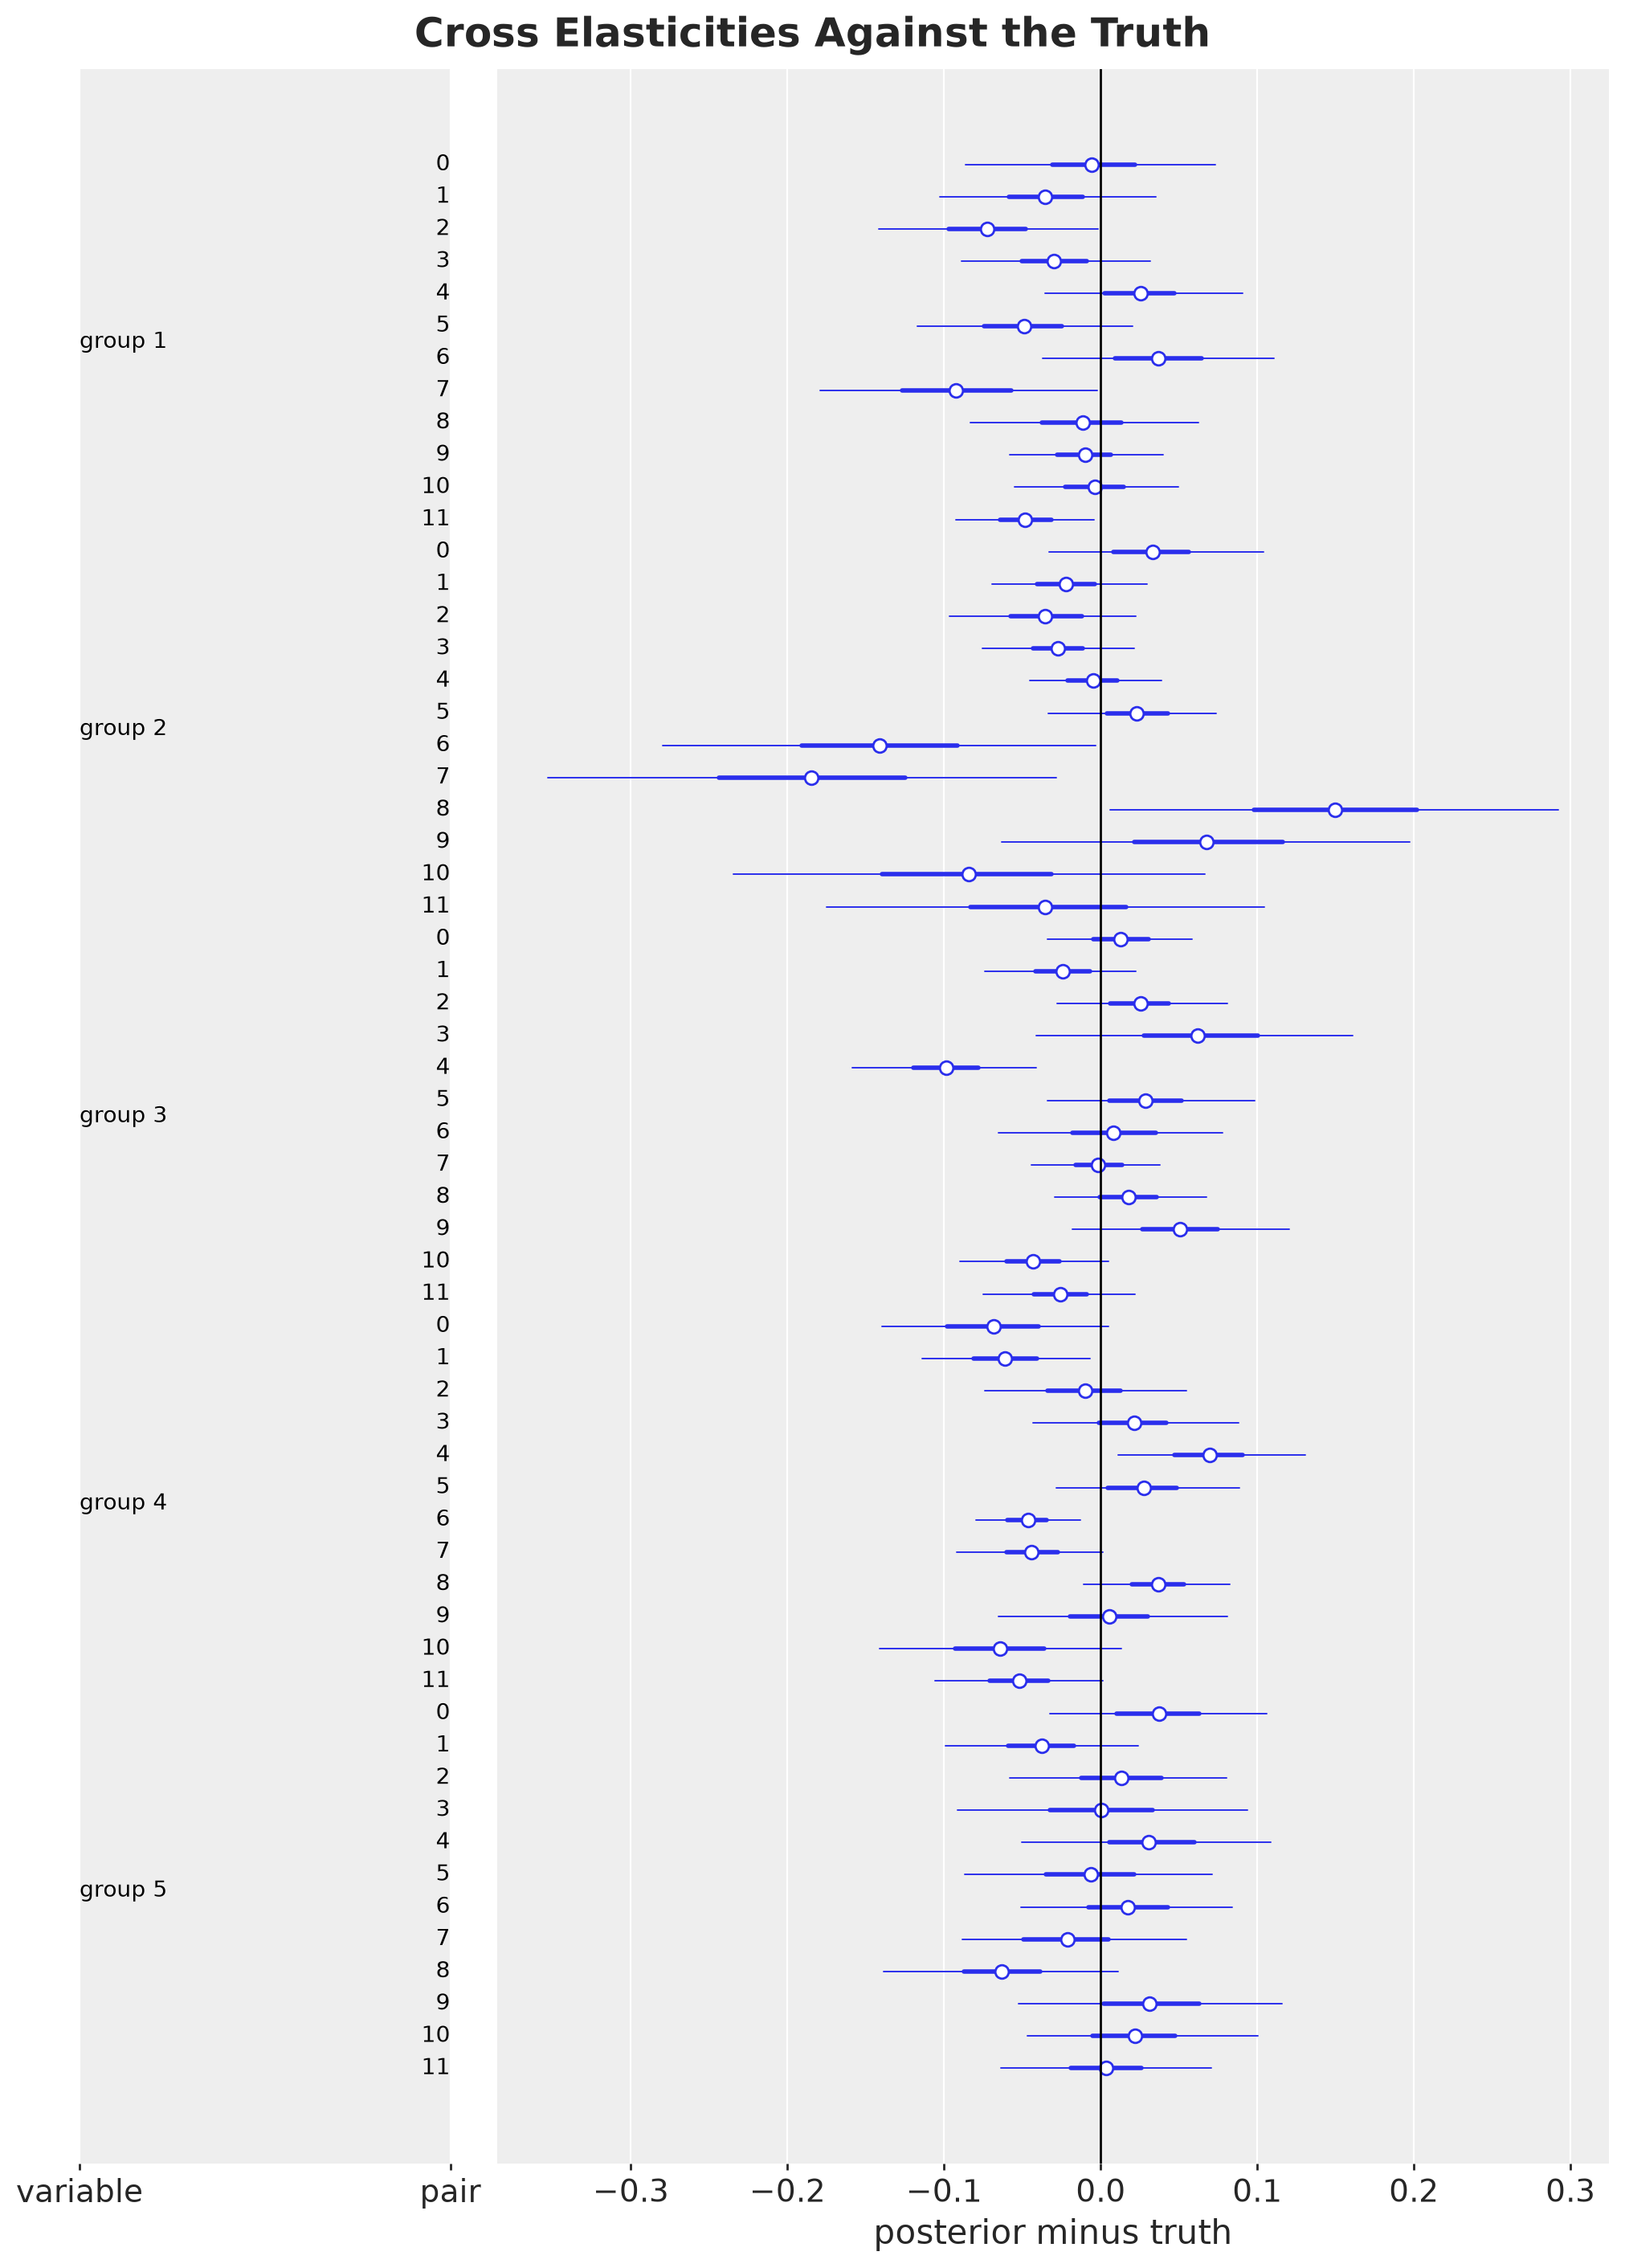

In [26]:
pair_group = panel.product_to_group[panel.pair_rows]
cross_minus_truth = np.asarray(
    posteriors["cross"]["cross_elasticity"] - true_params["cross_elasticity"]
)

pc = az.plot_forest(
    xr.Dataset(
        {
            f"group {g + 1}": (
                ("sample", "pair"),
                cross_minus_truth[:, pair_group == g],
            )
            for g in range(setup.n_groups)
        }
    ),
    sample_dims=["sample"],
    figure_kwargs={"figsize": (10, 14)},
)
ax = pc.viz["plot"].sel(column="forest").item()
ax.axvline(0.0, color="black", linewidth=1)
ax.set(xlabel="posterior minus truth")
pc.viz["figure"].item().suptitle(
    "Cross Elasticities Against the Truth", fontsize=18, fontweight="bold"
);

The intervals cover the truth for $50$ of the $60$ pairs, $9$ to $12$ per group, a little below the $94\%$ we asked for. The next table averages the posterior mean of the cross elasticity over the $12$ pairs of each group, next to the true value.

In [27]:
pl.DataFrame(
    {
        "group": [f"group {g + 1}" for g in range(setup.n_groups)],
        "true cross elasticity": group_cross,
        "posterior mean": [
            float(
                np.asarray(posteriors["cross"]["cross_elasticity"])
                .mean(axis=0)[pair_group == g]
                .mean()
            )
            for g in range(setup.n_groups)
        ],
    }
)

group,true cross elasticity,posterior mean
str,f64,f64
"""group 1""",0.6,0.575405
"""group 2""",0.3,0.278154
"""group 3""",0.0,0.000957
"""group 4""",0.3,0.284497
"""group 5""",0.0,0.002321


The posterior means of the groups land at $0.58$, $0.28$, $0.00$, $0.28$ and $0.00$, so the model finds the cannibalization of groups $1$, $2$ and $4$, with the shrinkage pulling the two largest groups a few hundredths toward zero, and does not invent any in groups $3$ and $5$. The cross model has what it needs to move demand between siblings in the promotion week, and to leave group $3$ alone.

### Level and Dispersion

The following table reports, for each family of parameters and each model, the share of true values inside the $94\%$ interval and the median ratio of the posterior mean to the truth, over the entries whose true value is not zero. The last row is the level of every series at the end of the history, the quantity the forecast starts from, with two more columns: the standard deviation of the error of the posterior mean across the series, on the log scale, and that error divided by the median posterior standard deviation, which is one for a guide of the right width. We also report the ratio of the posterior mean of the concentration to the truth by group, since the groups differ in how much cannibalization their history holds.

In [28]:
def coverage_of_truth(
    draws: Float[Array | np.ndarray, " sample *shape"],
    truth: Float[Array | np.ndarray, " *shape"],
) -> float:
    """Share of the entries whose true value lies inside the central interval."""
    lower, upper = np.quantile(
        np.asarray(draws), [(1 - CI_PROB) / 2, 1 - (1 - CI_PROB) / 2], axis=0
    )
    return float(((truth >= lower) & (truth <= upper)).mean())


def recovery_rows(name: str) -> list[dict[str, str | float]]:
    """Coverage and ratio per parameter family, and the level at the end of history."""
    rows = [
        {
            "model": name,
            "parameter": site,
            "coverage of truth": coverage_of_truth(
                posteriors[name][site], np.asarray(true_params[site])
            ),
            "posterior mean / truth": recovery_ratio(
                posteriors[name][site], true_params[site]
            ),
            "error sd": None,
            "error sd / posterior sd": None,
        }
        for site in ["elasticity", "concentration", "drift_scale", "cross_elasticity"]
        if site in posteriors[name]
    ]
    level = np.asarray(level_end[name])
    rows.append(
        {
            "model": name,
            "parameter": "level at end of history",
            "coverage of truth": coverage_of_truth(level, level_end_true),
            "posterior mean / truth": float(
                np.median(level.mean(axis=0) / level_end_true)
            ),
            "error sd": float((level.mean(axis=0) - level_end_true).std()),
            "error sd / posterior sd": float(
                (level.mean(axis=0) - level_end_true).std()
                / np.median(level.std(axis=0))
            ),
        }
    )
    return rows


recovery = pl.DataFrame([row for name in models for row in recovery_rows(name)])
recovery

model,parameter,coverage of truth,posterior mean / truth,error sd,error sd / posterior sd
str,str,f64,f64,f64,f64
"""independent""","""elasticity""",0.7,1.035247,null,null
"""independent""","""concentration""",0.5,0.933309,null,null
"""independent""","""drift_scale""",0.37,0.997784,null,null
"""independent""","""level at end of history""",0.565,0.995912,0.069355,2.472456
"""cross""","""elasticity""",0.85,0.999247,null,null
"""cross""","""concentration""",0.8,0.978378,null,null
"""cross""","""drift_scale""",0.435,0.904532,null,null
"""cross""","""cross_elasticity""",0.833333,0.94579,null,null
"""cross""","""level at end of history""",0.665,1.002362,0.056332,2.018107


In [29]:
pl.DataFrame(
    {
        "model": list(models),
        **{
            f"group {g + 1}": [
                float(
                    np.asarray(
                        posteriors[name]["concentration"].mean(axis=0)
                        / true_params["concentration"]
                    )[panel.product_to_group == g].mean()
                )
                for name in models
            ]
            for g in range(setup.n_groups)
        },
    }
)

model,group 1,group 2,group 3,group 4,group 5
str,f64,f64,f64,f64,f64
"""independent""",0.852266,0.929446,1.005518,0.931985,0.954705
"""cross""",0.975226,0.97935,1.012941,1.00872,0.950892


Here is what the two tables say, model by model.

- **Cross model.** The own and the cross elasticities are covered at $85\%$ and $83\%$ and their posterior means sit on or close to the truth. The concentration is $2\%$ low, the drift scale $10\%$ low, and the intervals of both are narrow: the drift scale of a series is covered only $44\%$ of the time, with the mean-field guide as the likely cause.
- **Independent model.** The concentration is $7\%$ low, and by group it is $15\%$ low in group $1$, where the sibling dips are the largest, and on target in group $3$, which has none. The model treats the unexplained dips as noise. Its own elasticities are covered at $70\%$, for the reason we saw in the figure.

The last row is the one the plans depend on. The posterior mean of the level at the end of the history has an error with a standard deviation of $0.056$ for the cross model and $0.069$ for the independent model on the log scale, about $6\%$ to $7\%$ of the level, while the ratios of $2.0$ and $2.5$ put the median posterior standard deviation at $0.028$ under both models. The ratios say that the guide is overconfident about where every series stands today, by a factor of about two, and the coverage of $67\%$ and $57\%$ for a $94\%$ interval says the same thing. This is the mean-field limitation we expected. We come back to it in the *Out of Sample Evaluation* section, where it shows up as the price of the plans.

### Forecast Calibration

The third check compares the width of the forecast of each model with the width of the true future. For every series and day we divide the standard deviation of the model's scenarios by the standard deviation of the evaluation scenarios, and we look at the distribution of this ratio over the $3{,}000$ series-days. A ratio of one is a forecast as wide as the truth on a single day. We compute the same ratio for the total demand of a series over the $15$ days, which also depends on how the days of a path move together. We also score the one realized future with the coverage of the $94\%$ interval and the CRPS, as in the first post.

In [30]:
sd_true = demand_eval.std(axis=0)
width_ratio = {
    name: np.asarray(scenarios[name].std(axis=0) / sd_true) for name in models
}
sd_total_true = demand_eval.sum(axis=1).std(axis=0)
total_ratio = {
    name: np.asarray(scenarios[name].sum(axis=1).std(axis=0) / sd_total_true)
    for name in models
}
sibling_promo = (slice(7, 14), series_role == "sibling")

calibration = pl.DataFrame(
    [
        {
            "model": name,
            "median sd ratio": float(np.median(width_ratio[name])),
            "sd ratio on siblings in the promotion week": float(
                np.median(width_ratio[name][sibling_promo])
            ),
            "median sd ratio of the horizon total": float(np.median(total_ratio[name])),
            f"coverage {CI_PROB:.0%}": float(
                eval_coverage(scenarios[name], demand_future_true, alpha=CI_PROB)
            ),
            "CRPS": float(crps_empirical(scenarios[name], demand_future_true).mean()),
            "share of series-days with sd ratio above 1.2": float(
                (width_ratio[name] > 1.2).mean()
            ),
        }
        for name in models
    ]
)
calibration

model,median sd ratio,sd ratio on siblings in the promotion week,median sd ratio of the horizon total,coverage 94%,CRPS,share of series-days with sd ratio above 1.2
str,f64,f64,f64,f64,f64,f64
"""independent""",1.032315,1.108903,1.117235,0.938,10.040323,0.059667
"""cross""",1.021067,1.018882,1.093241,0.945,9.656346,0.001333


The next figure shows the distribution of the single-day ratio over the $3{,}000$ series-days of each model.

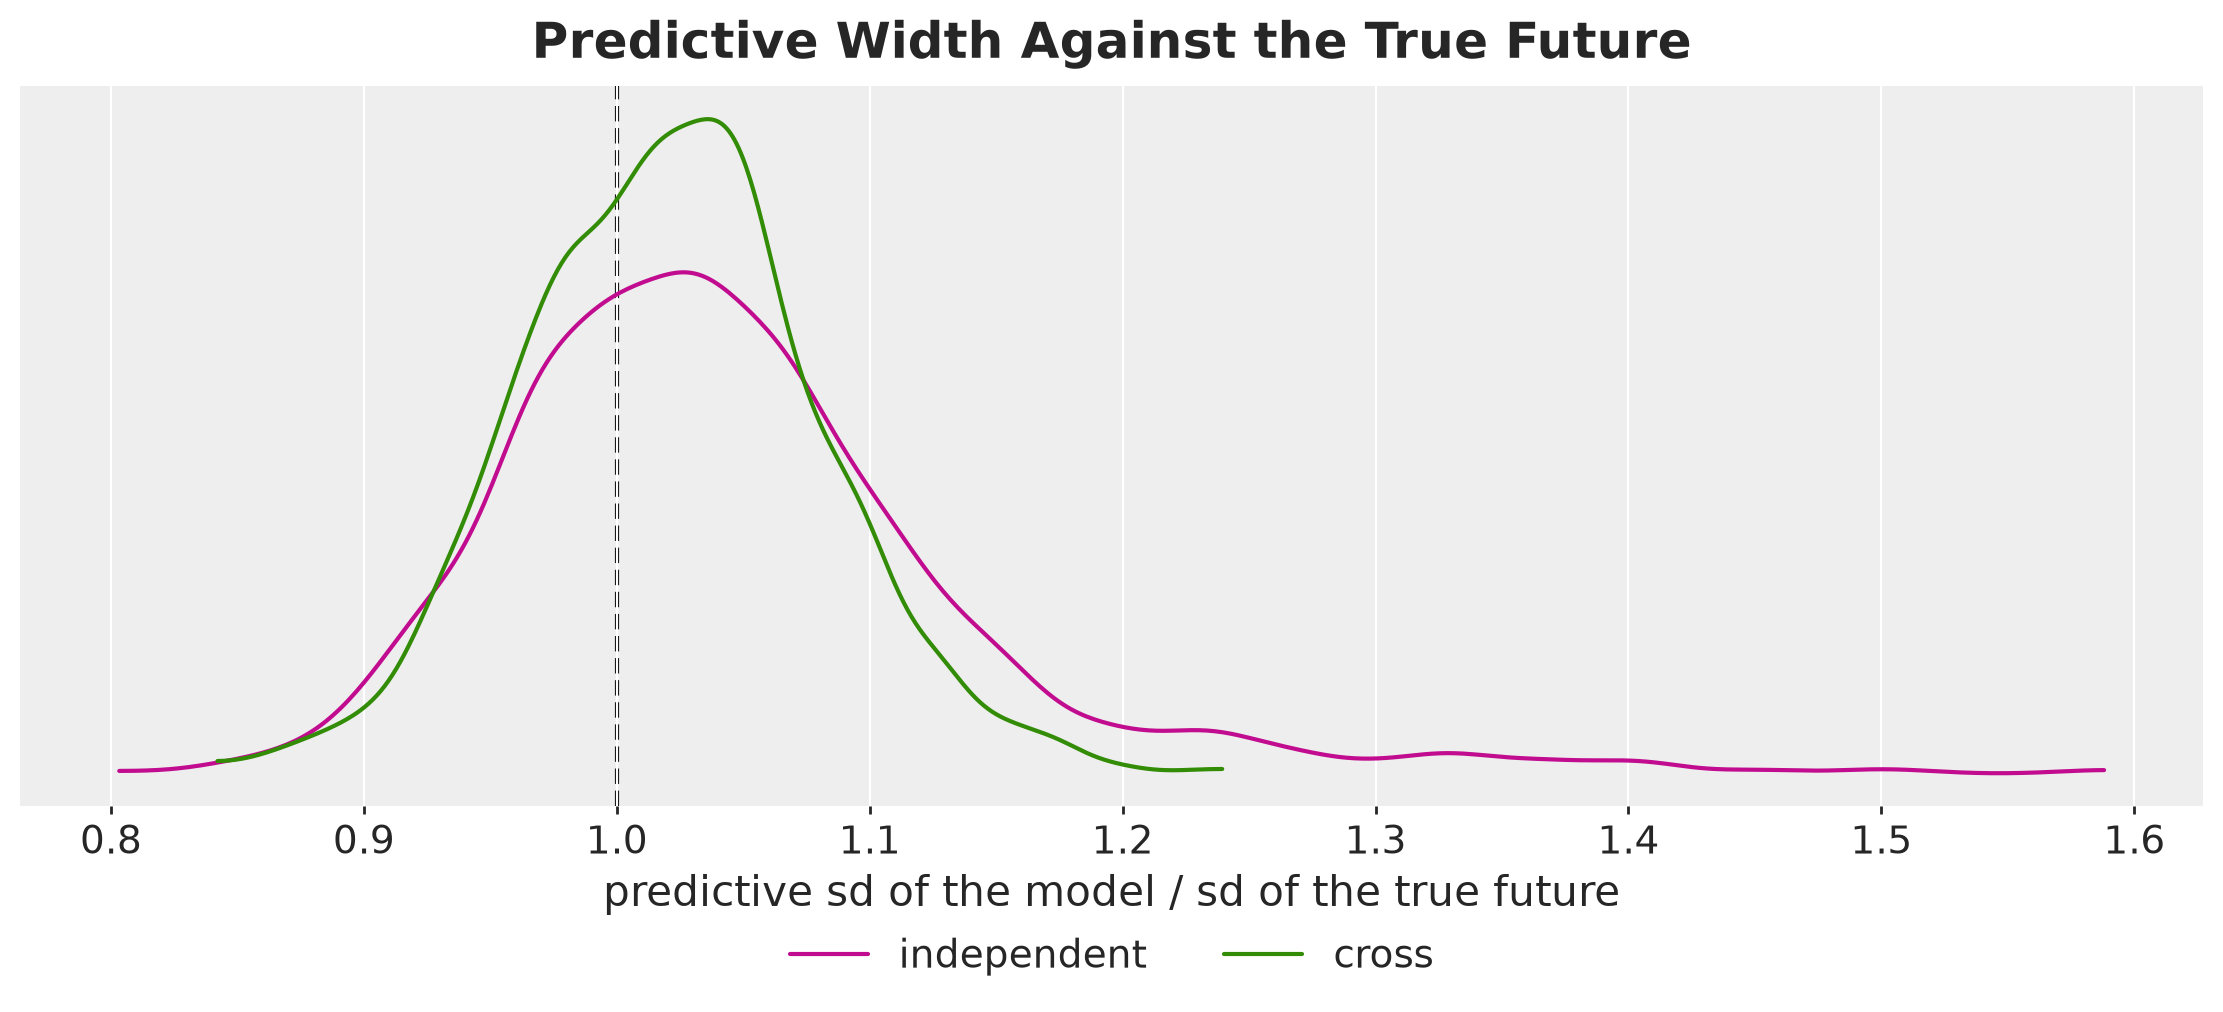

In [31]:
pc = az.plot_dist(
    {
        name: xr.Dataset({"sd ratio": (("sample",), width_ratio[name].ravel())})
        for name in models
    },
    sample_dims=["sample"],
    kind="kde",
    color=[MODEL_COLORS[name] for name in models],
    visuals={
        "point_estimate": False,
        "point_estimate_text": False,
        "credible_interval": False,
    },
    figure_kwargs={"figsize": (11, 5)},
)
az.add_lines(
    pc,
    values={"sd ratio": 1.0},
    visuals={"ref_line": {"color": "black", "linestyle": "--"}},
)
ax = pc.viz["plot"]["sd ratio"].item()
ax.set(xlabel="predictive sd of the model / sd of the true future", title="")
pc.add_legend("model", title="", loc="outside lower center", ncol=2)
pc.viz["figure"].item().suptitle(
    "Predictive Width Against the True Future", fontsize=18, fontweight="bold"
);

The calibration metrics do not separate the two models. Both forecasts are about as wide as the true future on a single day, with a median ratio of $1.02$ for the cross model and $1.03$ for the independent model, both cover the realized future at about $94\%$, and their CRPS differ by $4\%$ ($9.7$ against $10.0$ units). On the total demand of a series over the horizon both forecasts are wider than the true future, $1.09$ and $1.12$, which is right: the model does not know the level of the series and the true future does.

The one place where the independent model stands out is the siblings in the promotion week, where its forecast is $11\%$ wider than the truth against $2\%$ for the cross model, and the right tail of its distribution above $1.2$ holds $6\%$ of the series-days against $0.1\%$. The independent model treats the dips of the history as noise, so it is wide where the cross model is precise. A calibration check on the realized future would not have told us that the independent model is the wrong one. The difference shows up in the plans, which we build next.

## Demand Scenarios

We now have three sets of demand paths, each of shape (scenarios, days, series).

- The $1{,}000$ forecast draws of the independent model, the **optimization scenarios** of the plans built on it.
- The $1{,}000$ forecast draws of the cross model, the optimization scenarios of the plans built on it.
- The $3{,}000$ evaluation scenarios of the true process, on which every plan is scored.

The capacity of each store is a multiple $\kappa$ of its **regular throughput**, which we take as the median of its total daily demand over the last eight weeks of the history, a number the planner has and that one promotion week does not move much. We start with $\kappa = 1.05$, so that the capacity is slack on a regular day and binds in the promotion week, and we sweep it in the *Capacity Sensitivity* section. The initial stock of every series is its mean daily demand over the last four weeks of the history.

In [32]:
KAPPA = 1.05

data_by_store = np.asarray(data, dtype=np.float32).reshape(
    setup.t_obs, setup.n_stores, setup.n_products
)
regular_store = np.median(data_by_store[-56:].sum(axis=-1), axis=0)
capacity = jnp.asarray(KAPPA * regular_store)
initial_inventory = jnp.asarray(np.asarray(data[-28:], dtype=np.float32).mean(axis=0))

demand_opt = {name: scenarios[name] for name in models}
mean_demand = {name: demand_opt[name].mean(axis=0) for name in models}


def flat(
    orders: Float[Array, "horizon n_stores n_products"],
) -> Float[Array, "horizon n_series"]:
    """Reshape a plan from (day, store, product) to (day, series)."""
    return orders.reshape(setup.horizon, setup.n_series)


def unflat(
    orders: Float[Array, "horizon n_series"],
) -> Float[Array, "horizon n_stores n_products"]:
    """Reshape a plan from (day, series) to (day, store, product)."""
    return orders.reshape(setup.horizon, setup.n_stores, setup.n_products)

The next figure shows the forecasts of both models for the four products of group $1$ in store $1$, with the $50\%$ and $94\%$ bands and the mean of each model, next to the last four weeks of history and the true future.

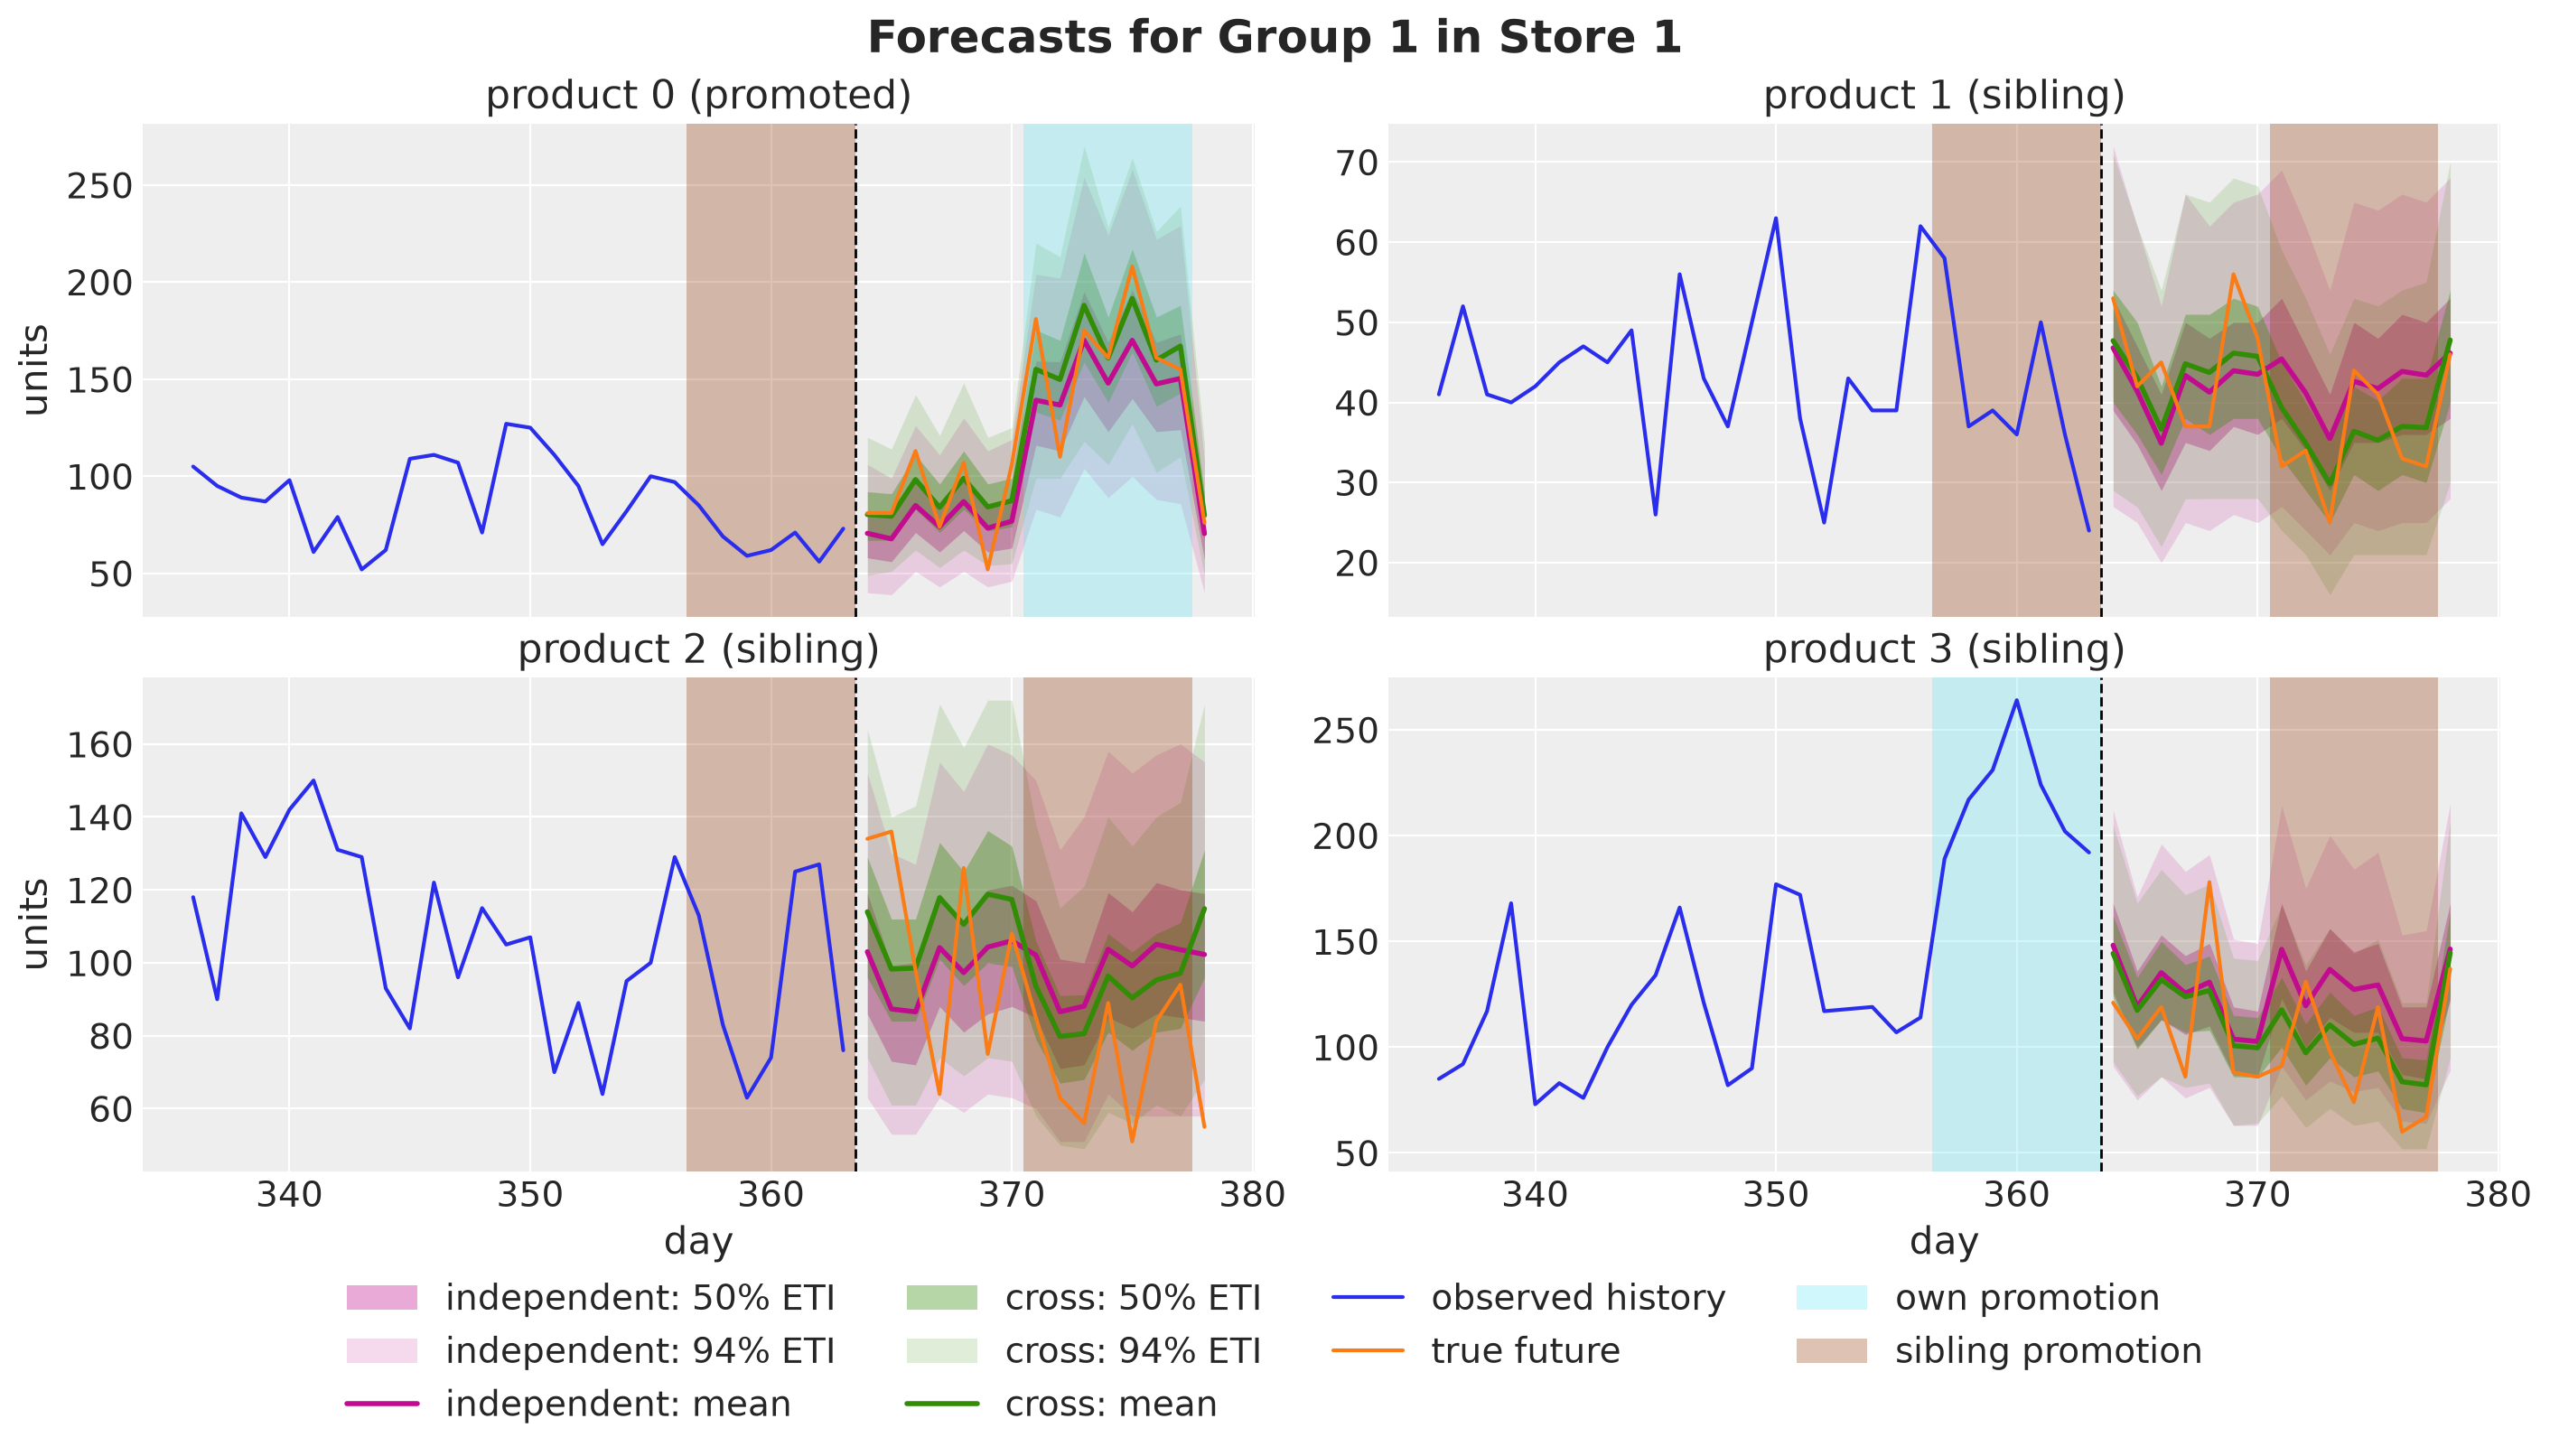

In [33]:
def forecast_tree(series: np.ndarray, labels: list[str], name: str) -> xr.DataTree:
    """The forecast draws of model `name` for some series, in the ArviZ schema."""
    return az.from_dict(
        {
            "posterior_predictive": {
                "obs": np.asarray(scenarios[name][None][..., series]).transpose(
                    0, 1, 3, 2
                )
            },
            "observed_data": {"obs": np.asarray(demand_future_true[:, series]).T},
            "constant_data": {
                "day": np.tile(days_future.astype(float), (len(series), 1))
            },
        },
        coords={"series": labels, "time": days_future},
        dims={"obs": ["series", "time"], "day": ["series", "time"]},
    )


def plot_group_forecast(store: int, group: int, start: int = setup.t_obs - 28) -> None:
    """Forecasts of both models for the four products of a group in a store."""
    group_products = np.flatnonzero(panel.product_to_group == group)
    series = store * setup.n_products + group_products
    labels = [f"product {j} ({product_role[j]})" for j in group_products]
    pc = None
    for name in models:
        pc = az.plot_lm(
            forecast_tree(series, labels, name),
            x="day",
            y="obs",
            y_obs="obs",
            plot_dim="time",
            smooth=False,
            ci_prob=(0.5, CI_PROB),
            point_estimate="mean",
            visuals={
                "ci_band": {"color": MODEL_COLORS[name]},
                "pe_line": {"color": MODEL_COLORS[name], "alpha": 1.0, "linewidth": 2},
                "observed_scatter": False,
                "xlabel": False,
                "ylabel": False,
            },
            col_wrap=2,
            figure_kwargs={"figsize": (14, 8), "sharex": True},
            plot_collection=pc,
        )
        lighten_bands(pc, "day", prob_alpha=((0.5, 0.35), (CI_PROB, 0.15)))
        for label in labels:
            bands = pc.viz["ci_band"]["day"].sel(series=label)
            bands.sel(prob=0.5).item().set_label(f"{name}: 50% ETI")
            bands.sel(prob=CI_PROB).item().set_label(f"{name}: {CI_PROB:.0%} ETI")
            pc.viz["pe_line"]["day"].sel(series=label).item().set_label(f"{name}: mean")
    for k, (label, i, j) in enumerate(zip(labels, series, group_products, strict=True)):
        ax = pc.get_target("day", {"series": label})
        ax.plot(
            days[start : setup.t_obs],
            demand_full[start : setup.t_obs, i],
            color="C0",
            label="observed history",
        )
        ax.plot(days_future, demand_future_true[:, i], color="C1", label="true future")
        ax.axvline(setup.t_obs - 0.5, color="black", linestyle="--", linewidth=1)
        shade_promotions(ax, int(j), start, setup.duration)
        ax.set(
            title=label,
            xlabel="day" if k >= 2 else "",
            ylabel="units" if k % 2 == 0 else "",
        )
    fig = pc.viz["figure"].item()
    dedupe_legend(fig, ax, ncol=4)
    fig.suptitle(
        f"Forecasts for Group {group + 1} in Store {store + 1}",
        fontsize=18,
        fontweight="bold",
    )


plot_group_forecast(store=0, group=0);

On the promoted product the two forecasts agree on the shape: both jump in the promotion week, and the independent model sits a little lower throughout. On the three siblings the two models part in the promotion week. The cross model dips, from about $45$ to about $33$ units on product $1$ and from about $130$ to about $100$ units on product $3$, and the independent model stays close to flat. The true future, one noisy path, dips with the cross model.

The models also part in the first week, where no promotion happens. On product $2$ the cross model starts about $10$ units above the independent model, and on product $1$ about $3$ units above it. The last week of the history was a sibling promotion week for these two products, so their demand dipped there. The cross model attributes the dip to the sibling's price and expects the recovery. The independent model has no such term, so its level followed the dip down and its forecast starts low.

Next, we draw the same figure for group $3$, which is promoted but has no cannibalization.

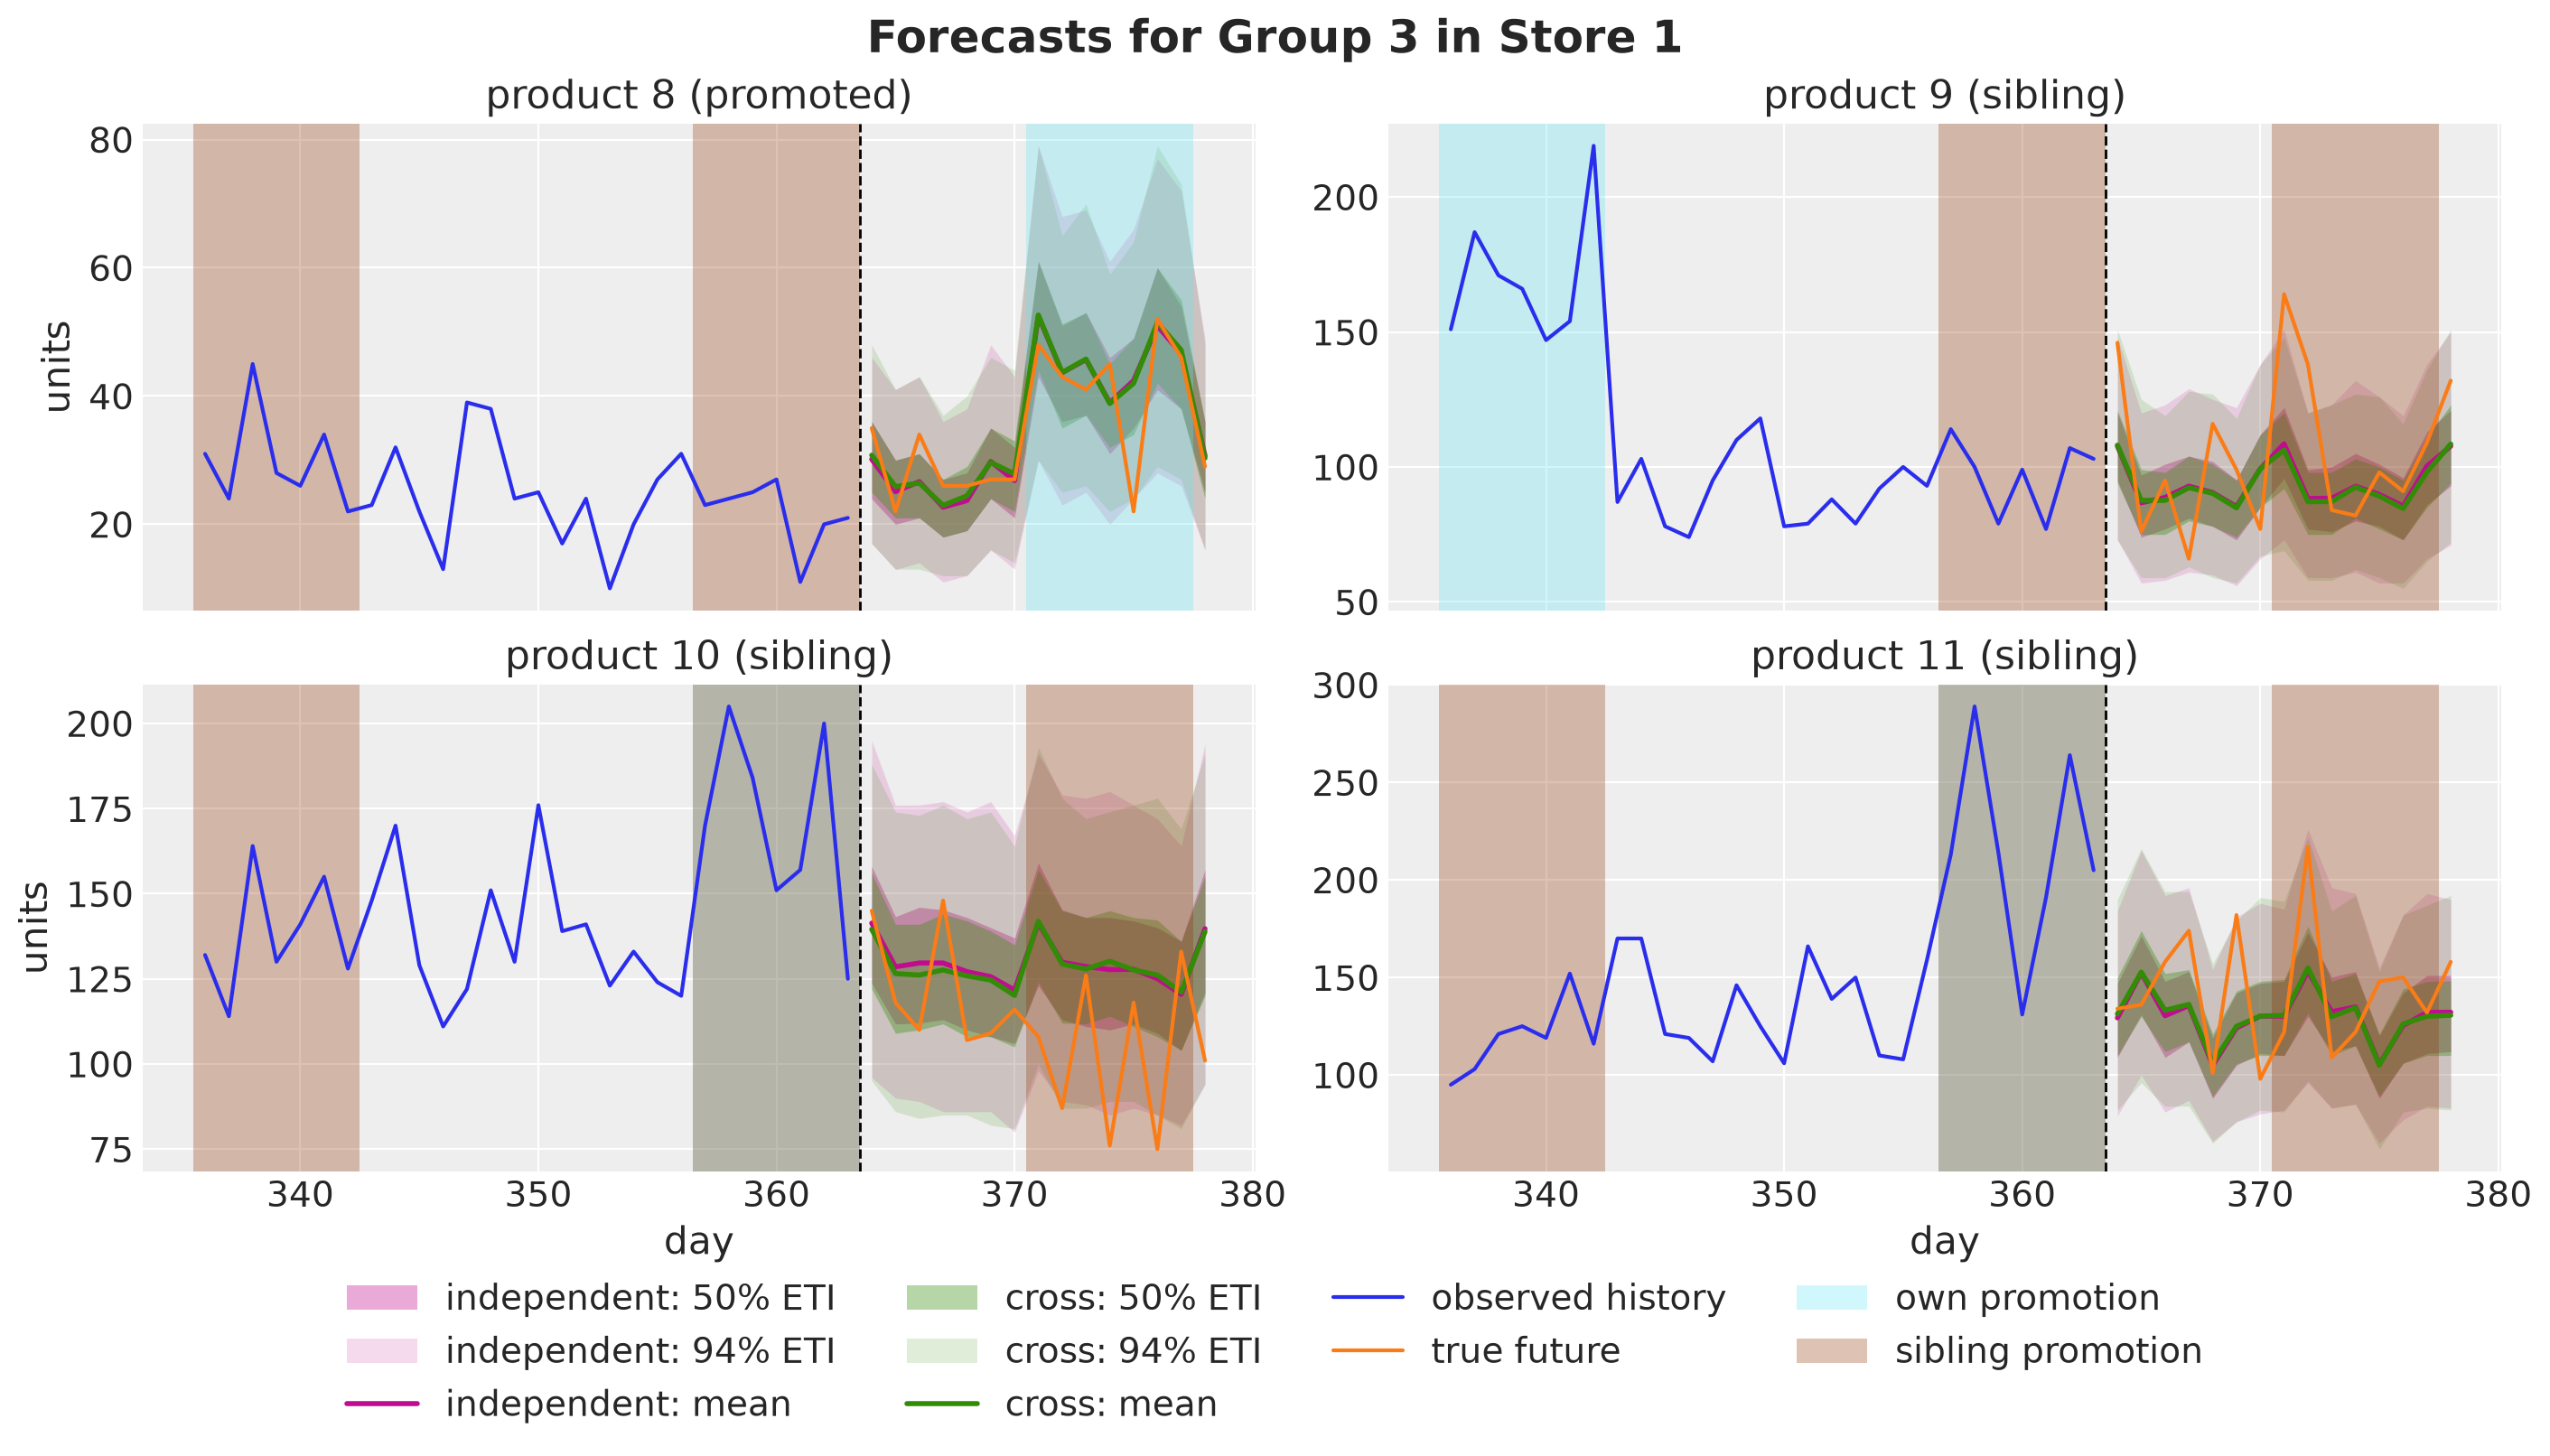

In [34]:
plot_group_forecast(store=0, group=2)

Group $3$ has no cannibalization, and the cross model finds none: the two forecasts lie on top of each other on every product, including the three siblings in the promotion week. The cross model does not invent a dip where the data show none, which is good!

Observe that the first week of the horizon has no promotion, so any difference between the two models in that week comes from the history. To see it, we divide the mean forecast of every series over the first week by the mean of the evaluation scenarios over the same week, and look at the distribution of this ratio over the series of each role. A ratio of one is a forecast that starts where the true future starts.

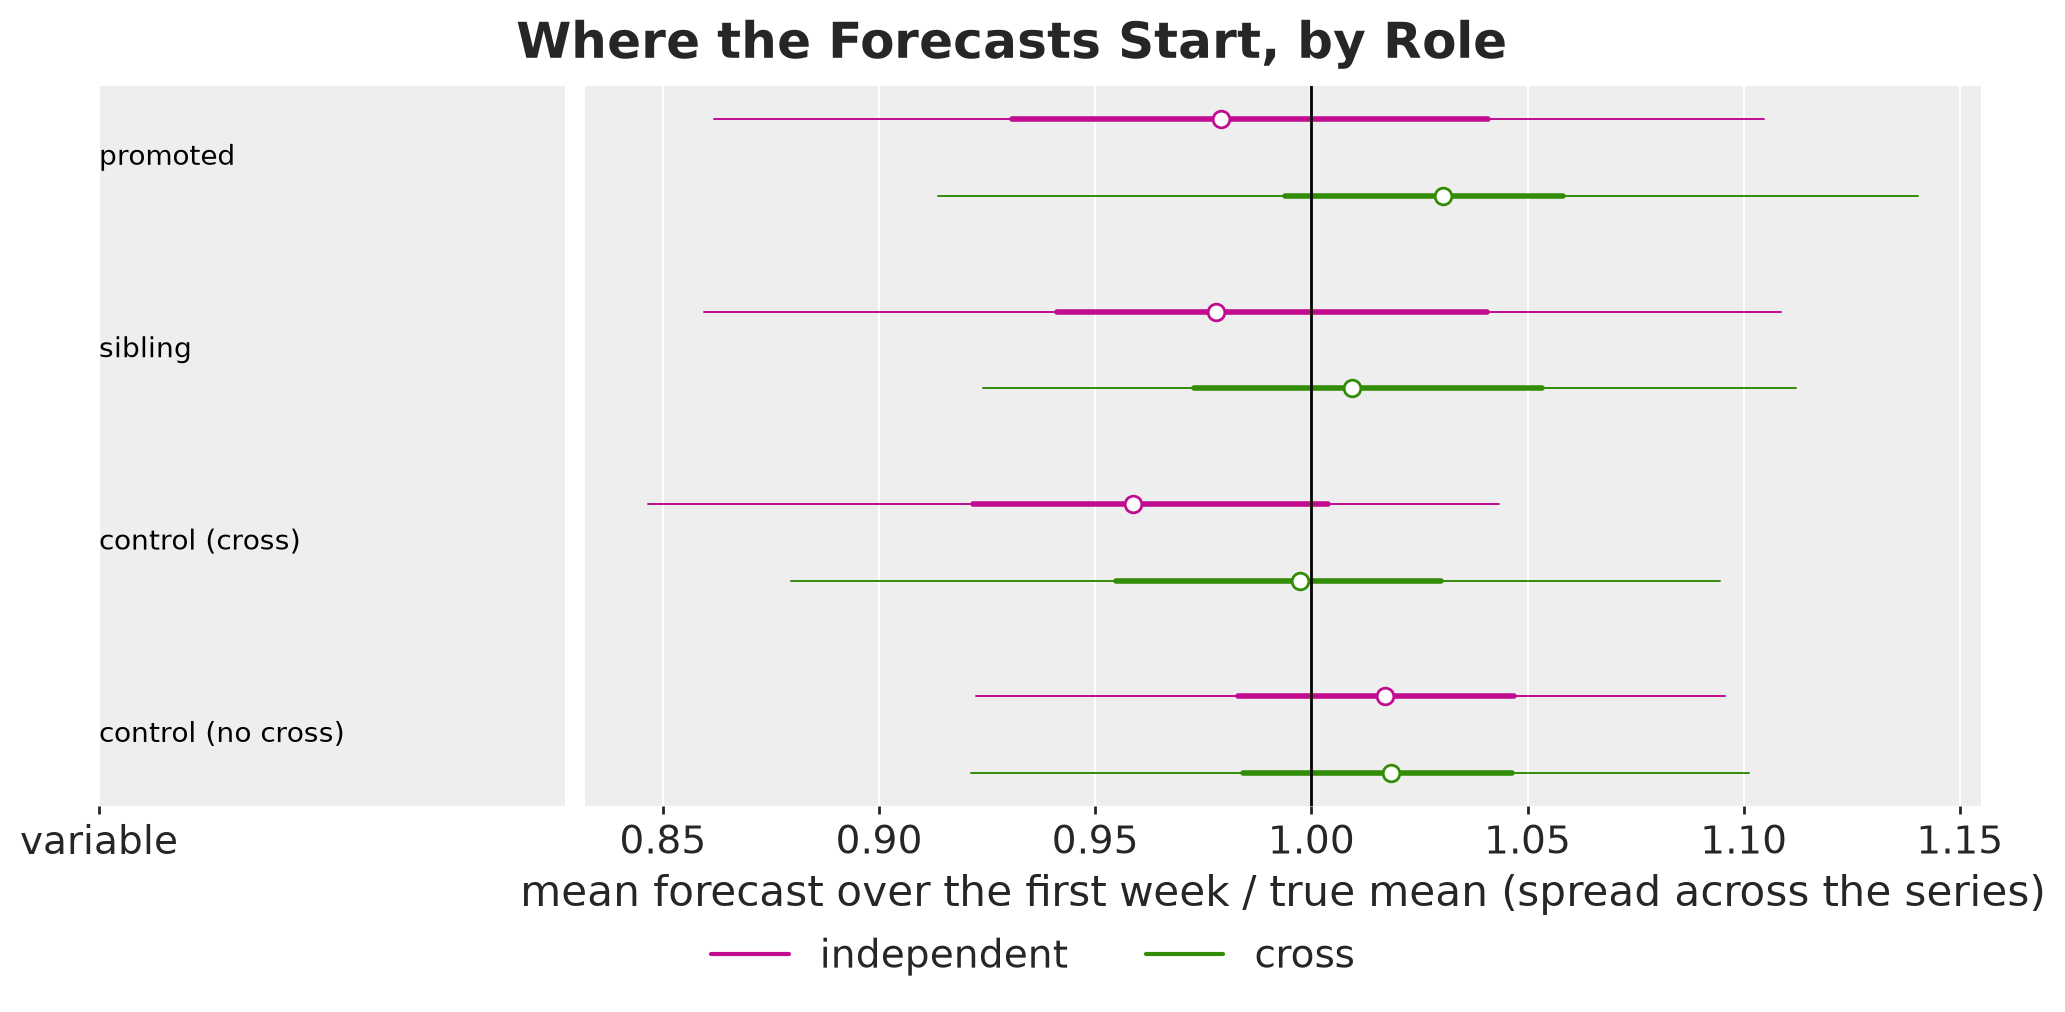

In [35]:
WEEKS = {
    "first week": slice(0, 7),
    "promotion week": slice(7, 14),
    "last day": slice(14, 15),
}
first_week = WEEKS["first week"]
truth_first_week = np.asarray(demand_eval[:, first_week].mean(axis=0)).mean(axis=0)

# the roles have different numbers of series, so each one gets its own series dim
origin_ratio = {
    name: xr.Dataset(
        {
            role: (
                (f"series of {role}",),
                np.asarray(scenarios[name][:, first_week].mean(axis=0)).mean(axis=0)[
                    series_role == role
                ]
                / truth_first_week[series_role == role],
            )
            for role in ROLES
        }
    )
    for name in models
}

pc = az.plot_forest(
    origin_ratio,
    sample_dims=[f"series of {role}" for role in ROLES],
    point_estimate="median",
    color=[MODEL_COLORS[name] for name in models],
    figure_kwargs={"figsize": (10, 5)},
)
ax = pc.viz["plot"].sel(column="forest").item()
ax.axvline(1.0, color="black", linewidth=1)
ax.set(
    xlabel="mean forecast over the first week / true mean (spread across the series)"
)
pc.add_legend("model", title="", loc="outside lower center", ncol=2)
pc.viz["figure"].item().suptitle(
    "Where the Forecasts Start, by Role", fontsize=18, fontweight="bold"
);

The dots are the medians and the bars the central $50\%$ and $94\%$ of the ratio across the series of a role, not a posterior. Here is what the figure shows.

- **Independent model.** The median ratio is below one on every role with cannibalization in its history: $0.98$ on the promoted products, $0.98$ on the siblings and $0.96$ on the control group with cross effects. On the control group without cross effects it is $1.02$.
- **Cross model.** The median ratio is $1.00$ to $1.03$ on every role.

Here is the mechanism. In the history, a product with cannibalization loses $10\%$ to $19\%$ of its demand in every week in which a sibling is on promotion, which happens in about three weeks out of ten. The independent model has no term for these dips, so its random-walk level averages over them and sits below the level of a week without promotions. The first week of the horizon is such a week, so the independent forecast starts $2\%$ to $4\%$ too low on these products, and the central $94\%$ across series runs from $0.87$ to $1.10$ on the siblings. The cross model attributes the dips to the prices of the siblings and starts where the true future starts. In the *Out of Sample Evaluation* section we see what a few percent of bias costs under an asymmetric loss.

## Inventory Simulator

The simulator is the one of the first post, with the initial stock as an argument because it differs across series. We vectorize it twice with `jax.vmap`: over the series of one plan and one demand path, and then over the scenarios. The loss of a scenario is the sum over the series, and we keep the stock and lost sales paths per series to split the loss by product role later. The helpers `tail_size`, `cvar` and `is_stockout` are copied from the first post.

In [36]:
class Simulation(NamedTuple):
    """Loss, stock path and lost sales path of one plan against one demand path."""

    loss: ScalarLike
    inventory: Float[Array, " horizon"]
    lost_sales: Float[Array, " horizon"]


def simulate(
    orders: Float[Array, " horizon"],
    demand: Float[Array, " horizon"],
    initial_inventory: ScalarLike,
    config: InventoryConfig,
) -> Simulation:
    """Run the inventory dynamics of one plan against one demand path."""

    def step(
        inventory: ScalarLike, inputs: tuple[ScalarLike, ScalarLike]
    ) -> tuple[ScalarLike, tuple[ScalarLike, ScalarLike, ScalarLike]]:
        order_t, demand_t = inputs
        available = inventory + order_t  # y_t
        sales_t = jnp.minimum(available, demand_t)
        lost_t = demand_t - sales_t
        inventory = available - sales_t
        cost_t = config.holding_cost * inventory + config.lost_sales_cost * lost_t
        return inventory, (inventory, lost_t, cost_t)

    _, (inventory_path, lost_path, cost_path) = jax.lax.scan(
        step, jnp.asarray(initial_inventory, dtype=orders.dtype), (orders, demand)
    )
    return Simulation(cost_path.sum(), inventory_path, lost_path)


# one plan (horizon, n_series) against one demand path (horizon, n_series): the
# results of every series, with the paths of shape (n_series, horizon)
simulate_series = jax.vmap(simulate, in_axes=(1, 1, 0, None))
# one plan against a batch of demand paths (scenarios, horizon, n_series)
simulate_scenarios = jax.jit(
    jax.vmap(simulate_series, in_axes=(None, 0, None, None)), static_argnames="config"
)

STOCKOUT_TOL = 1e-3  # lost sales below this are rounding noise of the solver


def tail_size(num_scenarios: int) -> int:
    """The integer k = ALPHA * N, static because top_k needs a Python integer."""
    return max(1, round(ALPHA * num_scenarios))


def cvar(losses: Float[Array, " scenarios"]) -> ScalarLike:
    """Mean of the k largest losses."""
    worst, _ = jax.lax.top_k(losses, tail_size(losses.shape[0]))
    return worst.mean()


def is_stockout(sim: Simulation) -> Bool[Array, "scenarios n_series horizon"]:
    """Days with lost sales above the tolerance."""
    return sim.lost_sales > STOCKOUT_TOL

The **mean forecast plan** of a model orders the shortfall of its mean path, day by day, and the orders of every day are projected onto the capacity set of the store before the stock is carried forward. This is the forward pass of the first post with the projection in place of the clip. We build one such plan per model.

In [37]:
def forward_pass_capacity(
    demand_path: Float[Array, "horizon n_stores n_products"],
    capacity: Float[Array, " n_stores"],
    initial_inventory: Float[Array, "n_stores n_products"],
) -> Float[Array, "horizon n_stores n_products"]:
    """Orders that follow one demand path: the projected shortfall of every day."""

    def step(
        inventory: Float[Array, "n_stores n_products"],
        demand_t: Float[Array, "n_stores n_products"],
    ) -> tuple[
        Float[Array, "n_stores n_products"], Float[Array, "n_stores n_products"]
    ]:
        shortfall = demand_t - inventory
        order_t = project_day(shortfall, capacity)
        inventory = jnp.maximum(inventory + order_t - demand_t, 0.0)
        return inventory, order_t

    _, orders = jax.lax.scan(step, initial_inventory, demand_path)
    return orders


orders_mean = {
    name: forward_pass_capacity(
        unflat(mean_demand[name]),
        capacity,
        initial_inventory.reshape(setup.n_stores, setup.n_products),
    )
    for name in models
}

## Decision Plans

The objective is the one of the first post, the expected loss plus $\lambda$ times its conditional value at risk, with the loss summed over the series before the mean and the tail. Recall that with $N$ scenarios the expected loss is approximated by the sample average $\frac{1}{N} \sum_{n=1}^{N} L(a, D^{(n)})$, where $D^{(n)}$ is the $n$-th scenario, the sample average approximation of [Shapiro, Dentcheva and Ruszczyński (2021)](https://doi.org/10.1137/1.9781611976595). The solver is the projected Adam of the first post, written with [Optax](https://optax.readthedocs.io/), with `project_orders` in place of the clip at zero after every step, so the iterates stay in the capacity set of every store and day. We solve the **expected cost plan** ($\lambda = 0$) on the scenarios of each model, starting from the mean forecast plan of that model.

The comparison of decision rules was the subject of the first post, so the chance-constrained plan does not return here, and we do not repeat the cross check against a linear program: the simulator and the solver are the ones checked there, with one projection swapped, and the program would have $200 \times 15 \times 1{,}000$ stock variables.

In [38]:
def objective(
    orders: Float[Array, "horizon n_stores n_products"],
    demand: Float[Array, "scenarios horizon n_series"],
    lam: ScalarLike,
    initial_inventory: Float[Array, " n_series"],
    config: InventoryConfig,
) -> ScalarLike:
    """Expected loss plus lam times the CVaR of the total loss over the scenarios."""
    losses = simulate_scenarios(flat(orders), demand, initial_inventory, config).loss
    losses = losses.sum(axis=-1)
    return losses.mean() + lam * cvar(losses)


def solve(
    demand: Float[Array, "scenarios horizon n_series"],
    lam: ScalarLike,
    orders_init: Float[Array, "horizon n_stores n_products"],
    capacity: Float[Array, " n_stores"],
    initial_inventory: Float[Array, " n_series"],
    config: InventoryConfig,
    n_steps: int = 1_500,
    learning_rate: float = 1.0,
) -> tuple[Float[Array, "horizon n_stores n_products"], Float[Array, " n_steps"]]:
    """Projected Adam on the expected cost plus lam times CVaR, as a lax.scan."""
    schedule = optax.cosine_decay_schedule(
        init_value=learning_rate, decay_steps=n_steps
    )
    optimizer = optax.adam(learning_rate=schedule)
    value_and_grad = jax.value_and_grad(objective)

    def step(
        carry: tuple[Float[Array, "horizon n_stores n_products"], optax.OptState],
        _: None,
    ) -> tuple[
        tuple[Float[Array, "horizon n_stores n_products"], optax.OptState], ScalarLike
    ]:
        orders, opt_state = carry
        value, grads = value_and_grad(orders, demand, lam, initial_inventory, config)
        updates, opt_state = optimizer.update(grads, opt_state, orders)
        orders = project_orders(orders + updates, capacity)  # projection onto A_C
        return (orders, opt_state), value

    (orders, _), values = jax.lax.scan(
        step, (orders_init, optimizer.init(orders_init)), None, length=n_steps
    )
    return orders, values


solve_jit = jax.jit(solve, static_argnames=("config", "n_steps"))

In [39]:
%%time

solves = {
    name: solve_jit(
        demand_opt[name], 0.0, orders_mean[name], capacity, initial_inventory, config
    )
    for name in models
}
orders_expected = {name: orders for name, (orders, _) in solves.items()}

CPU times: user 413 ms, sys: 17.9 ms, total: 431 ms
Wall time: 124 ms


We now have the four plans, two per model, so let's collect them in a list of `Plan` tuples in a fixed order and give each one a color that every figure below uses.

In [40]:
class Plan(NamedTuple):
    """One order plan with its name and the model whose scenarios built it."""

    name: str
    model: str
    orders: Float[Array, "horizon n_stores n_products"]


plans = [
    Plan("Mean forecast (independent)", "independent", orders_mean["independent"]),
    Plan("Mean forecast (cross)", "cross", orders_mean["cross"]),
    Plan("Expected cost (independent)", "independent", orders_expected["independent"]),
    Plan("Expected cost (cross)", "cross", orders_expected["cross"]),
]
plan_names = [plan.name for plan in plans]
PLAN_COLORS = dict(zip(plan_names, ["C0", "C1", "C3", "C2"], strict=True))
plans_by_name = {plan.name: plan for plan in plans}
orders_of = {plan.name: plan.orders for plan in plans}
expected_cost_plans = [name for name in plan_names if name.startswith("Expected cost")]

Here are the traces of the two solves.

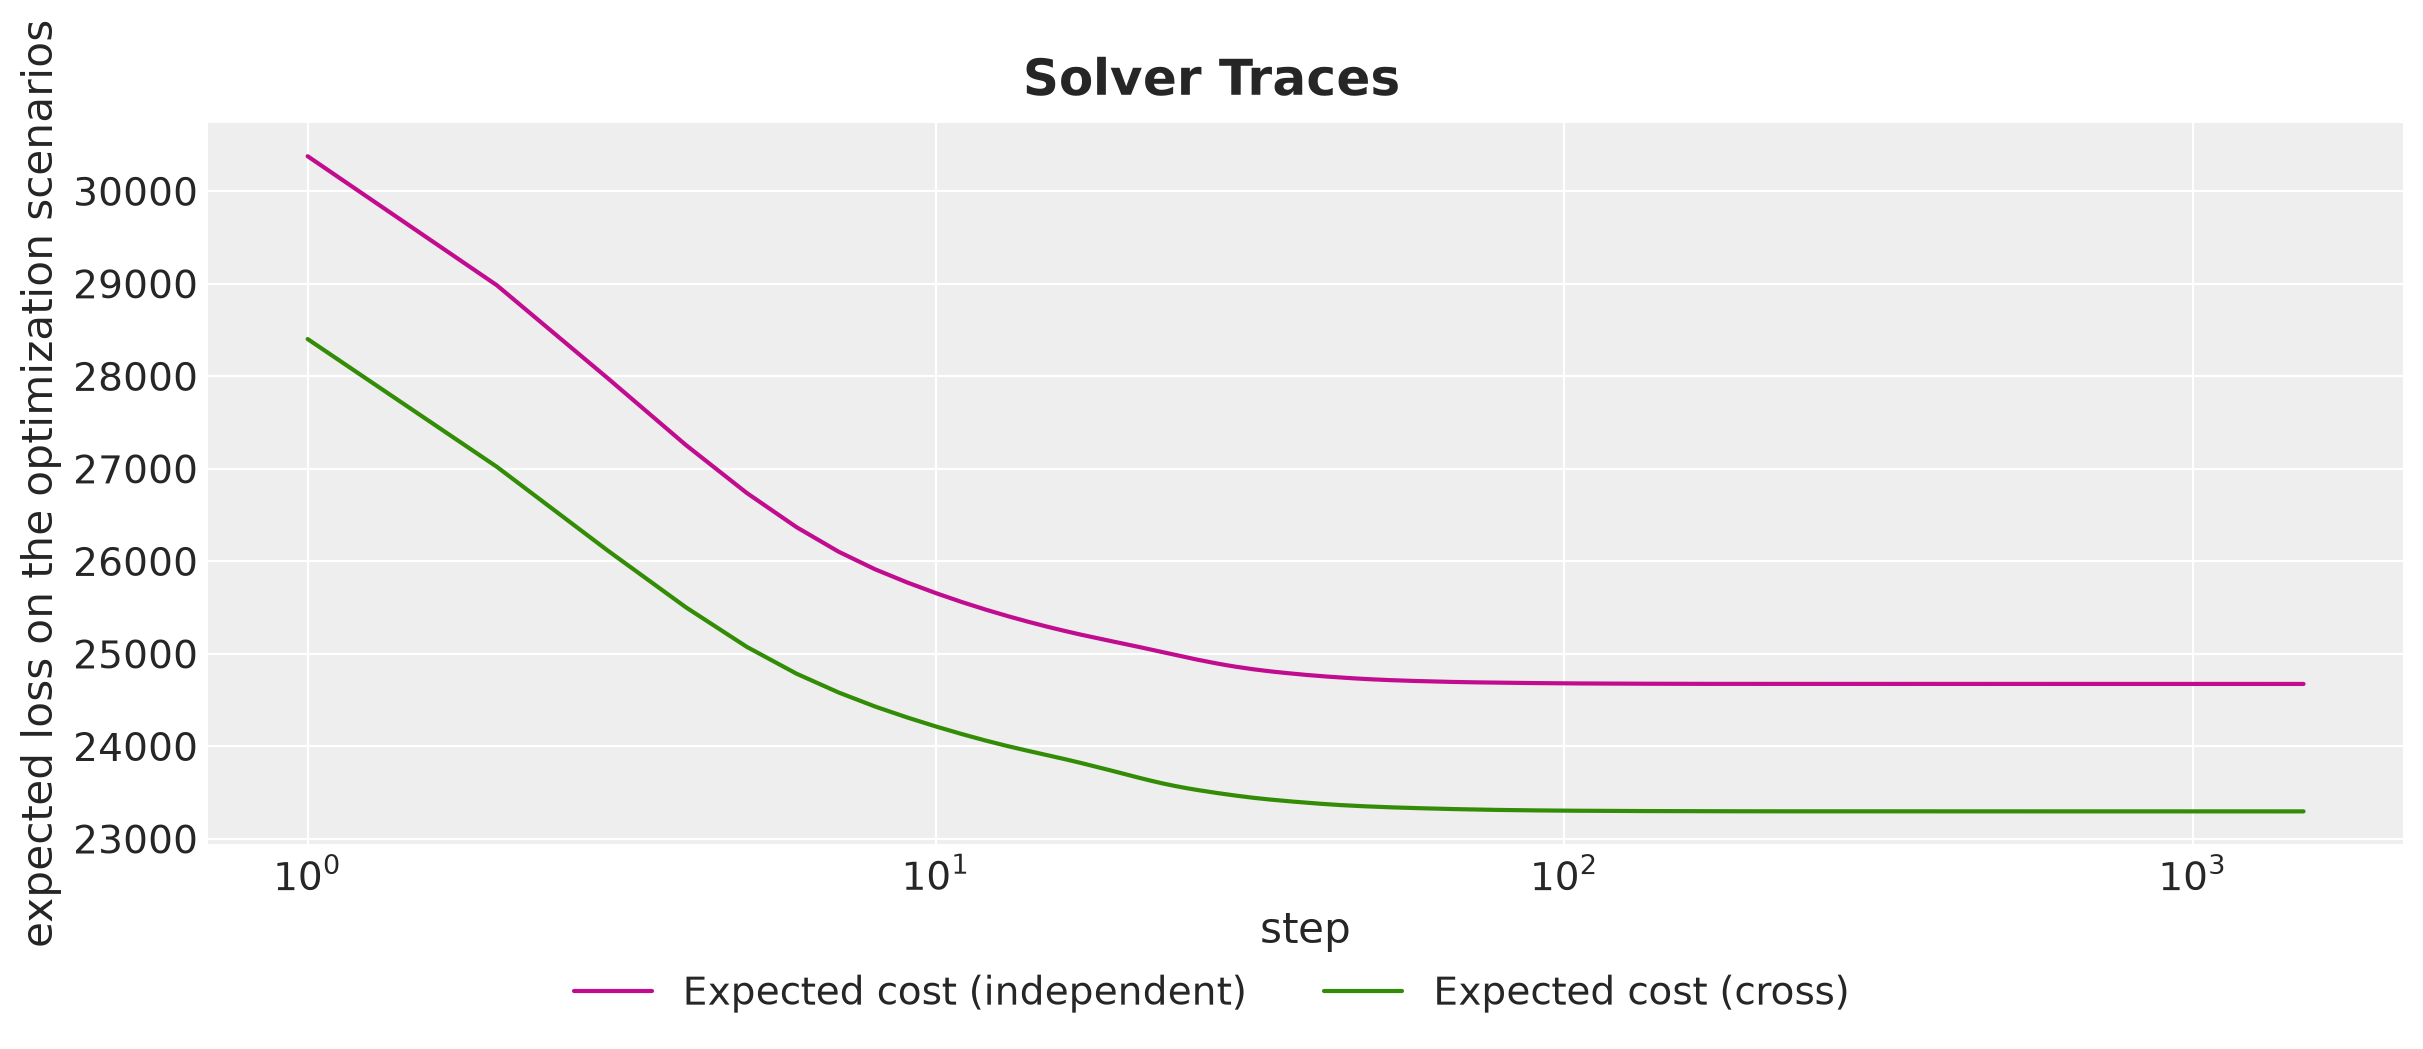

In [41]:
fig, ax = plt.subplots(figsize=(12, 5))
for name, (_, trace) in solves.items():
    ax.plot(
        np.arange(1, trace.size + 1),
        trace,
        color=PLAN_COLORS[f"Expected cost ({name})"],
        label=f"Expected cost ({name})",
    )
ax.set(
    xlabel="step", ylabel="expected loss on the optimization scenarios", xscale="log"
)
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle("Solver Traces", fontsize=18, fontweight="bold");

Both objectives drop within the first $50$ steps and are flat after about $300$. Both solves end at the lowest value of their trace, so the cosine schedule of the first post settles the iterates here too. The values on the optimization scenarios are $24{,}673$ for the independent plan and $23{,}296$ for the cross plan, and we compare them with the losses on the true future below.

Next, let's look at how much of the capacity the plans use. The following figure shows, for every day of the horizon, the share of the ten stores whose orders of that day are at capacity under each plan.

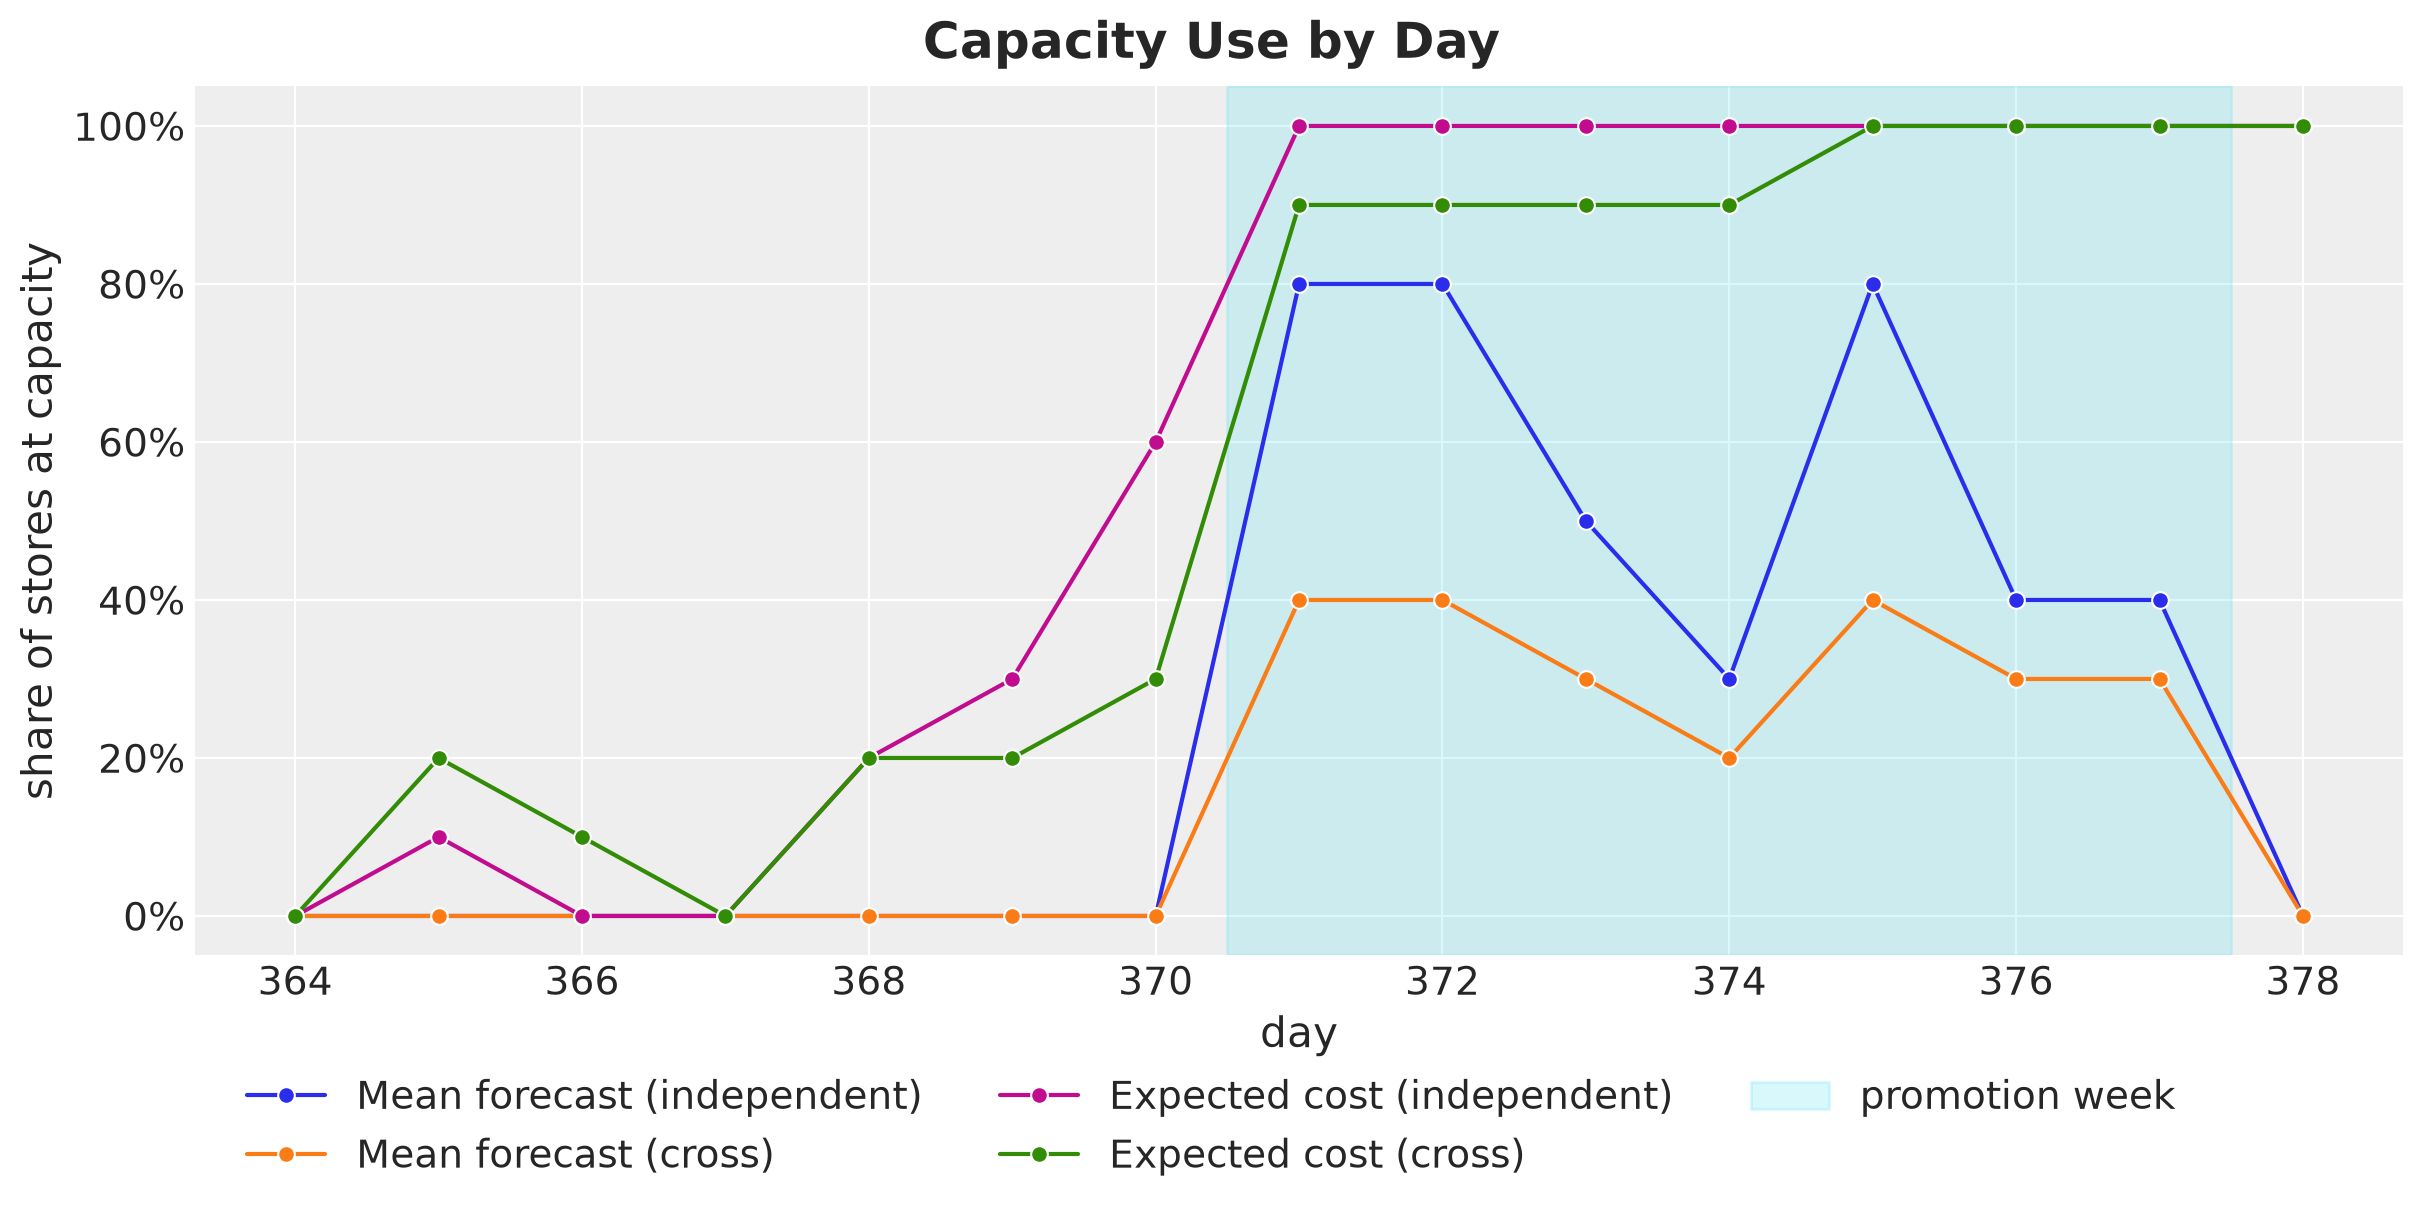

In [42]:
def at_capacity(
    orders: Float[Array, "horizon n_stores n_products"],
    capacity: Float[Array, " n_stores"],
) -> Float[Array, " horizon"]:
    """Share of the stores at capacity on every day of the horizon."""
    return (orders.sum(axis=-1) >= capacity * (1 - 1e-3)).mean(axis=-1)


def shade_promotion_week(ax: plt.Axes) -> None:
    """Shade the promotion week of the horizon."""
    ax.axvspan(
        promo_days_future[0] - 0.5,
        promo_days_future[-1] + 0.5,
        color="C5",
        alpha=0.25,
        label="promotion week",
    )


at_capacity_long = pl.DataFrame(
    {
        "plan": np.repeat(plan_names, setup.horizon),
        "day": np.tile(days_future, len(plans)),
        "share of stores at capacity": np.concatenate(
            [np.asarray(at_capacity(plan.orders, capacity)) for plan in plans]
        ),
    }
)

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(
    data=at_capacity_long,
    x="day",
    y="share of stores at capacity",
    hue="plan",
    hue_order=plan_names,
    palette=PLAN_COLORS,
    marker="o",
    ax=ax,
)
shade_promotion_week(ax)
ax.get_legend().remove()
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(xlabel="day", ylabel="share of stores at capacity")
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Capacity Use by Day", fontsize=18, fontweight="bold");

Here is what the figure shows.

- **First week.** The capacity is slack: no store is at capacity under the mean forecast plans, and the expected cost plans touch it in one to three stores on a few days, until the day before the promotion week, where the independent plan fills $6$ of the $10$ stores and the cross plan $3$.
- **Promotion week.** The capacity binds: the expected cost (independent) plan is at capacity in every store on every day, the expected cost (cross) plan in $9$ or $10$ stores, and the mean forecast plans in $2$ to $8$ stores depending on the day.
- **Last day.** Every solved plan is at capacity in every store, while the mean forecast plans are not. On the last day there is no later day to carry stock into, so a leftover costs $h$ once and a lost sale costs $p$, and the plan orders up to the $p / (p + h) = 0.95$ quantile of the demand of every product. The sum of those quantiles exceeds $1.05$ times the regular throughput of every store. This is an end-of-horizon effect of a plan without a terminal value, and in a rolling horizon the last order is never placed, so we do not read anything into day $15$.

The next figure shows the orders of store $1$ under the two expected cost plans, stacked by product role, against the capacity of the store.

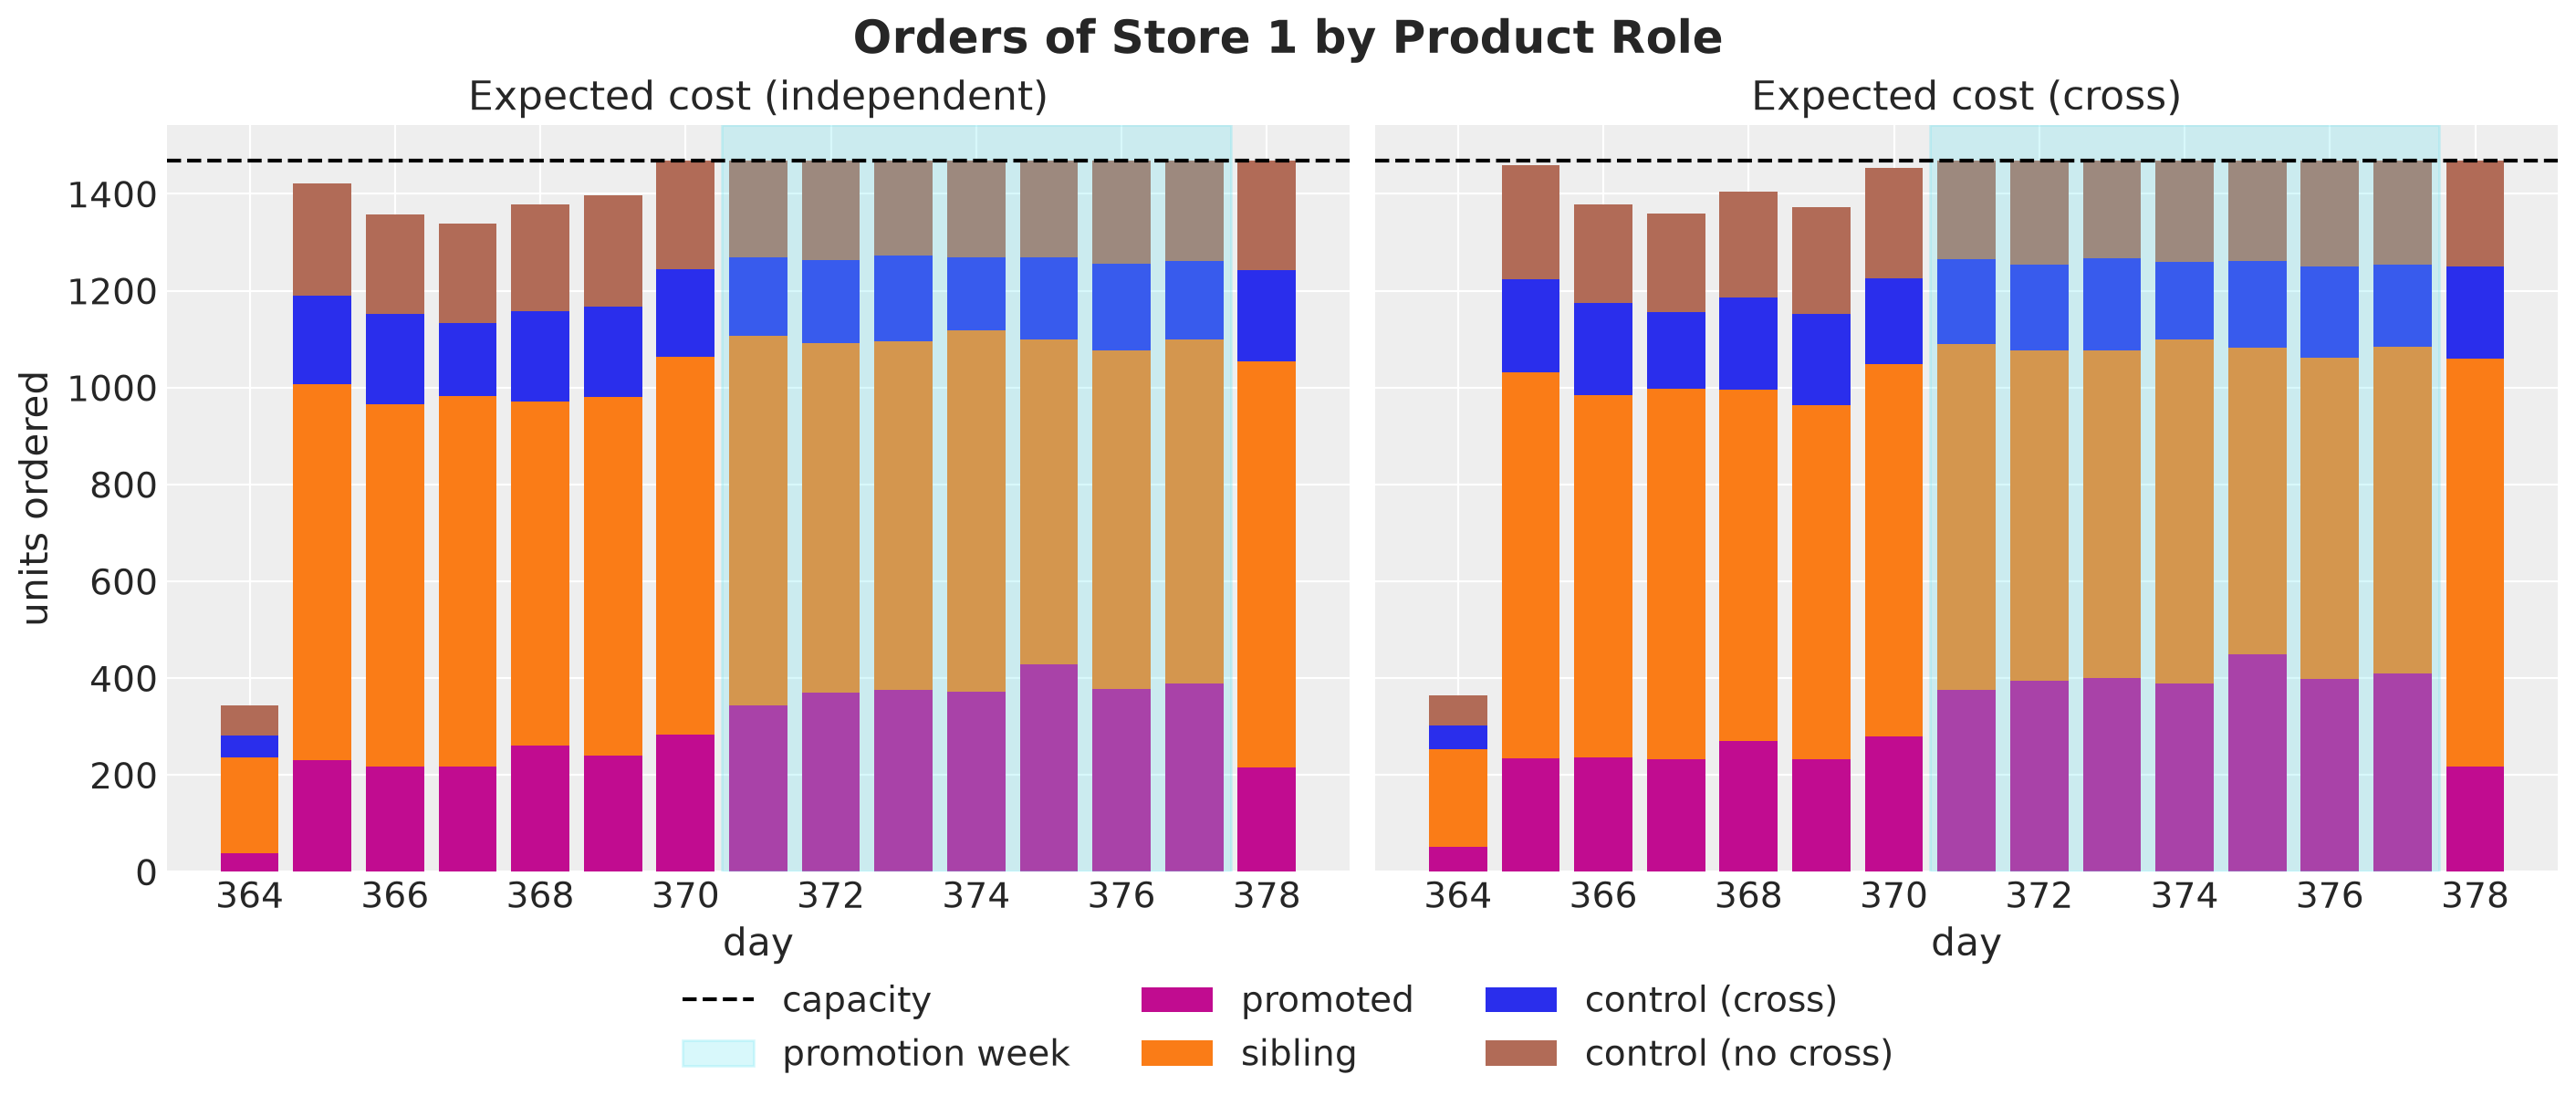

In [43]:
def orders_by_role(
    orders: Float[Array, "horizon n_stores n_products"], store: int
) -> dict[str, np.ndarray]:
    """Total orders of a store per day for every product role."""
    orders_store = np.asarray(orders[:, store])
    return {role: orders_store[:, product_role == role].sum(axis=1) for role in ROLES}


fig, axes = plt.subplots(ncols=2, figsize=(14, 6), sharey=True, layout="constrained")
for ax, name in zip(axes, expected_cost_plans, strict=True):
    stacks = orders_by_role(orders_of[name], store=0)
    bottom = np.zeros(setup.horizon)
    for role in ROLES:
        ax.bar(
            days_future,
            stacks[role],
            bottom=bottom,
            color=ROLE_COLORS[role],
            label=role,
        )
        bottom += stacks[role]
    ax.axhline(float(capacity[0]), color="black", linestyle="--", label="capacity")
    shade_promotion_week(ax)
    ax.set(title=name, xlabel="day")
axes[0].set(ylabel="units ordered")
dedupe_legend(fig, axes[0], ncol=3)
fig.suptitle("Orders of Store 1 by Product Role", fontsize=18, fontweight="bold");

The first order is small under both plans, because the initial stock covers most of day one. From day two on both plans order about $1{,}400$ units per day, below the capacity of about $1{,}470$, and both build stock on the day before the promotion week, when the independent plan reaches the capacity and the cross plan stays just below it. In the promotion week both plans are at capacity on every day, and they split it differently. The independent plan gives the siblings about $760$ units on the first promotion day against about $720$ under the cross plan, and the promoted products about $340$ against $380$. The siblings of groups $1$ and $2$ lose $19\%$ and $10\%$ of their demand in that week, so the independent plan stocks siblings for a demand that does not come, and the promoted products pay for it.

Store $1$ is one of ten. To see the difference between the two expected cost plans across the whole chain, we take the orders of the independent plan minus the orders of the cross plan, per product and day, and average them over the products and stores of each role.

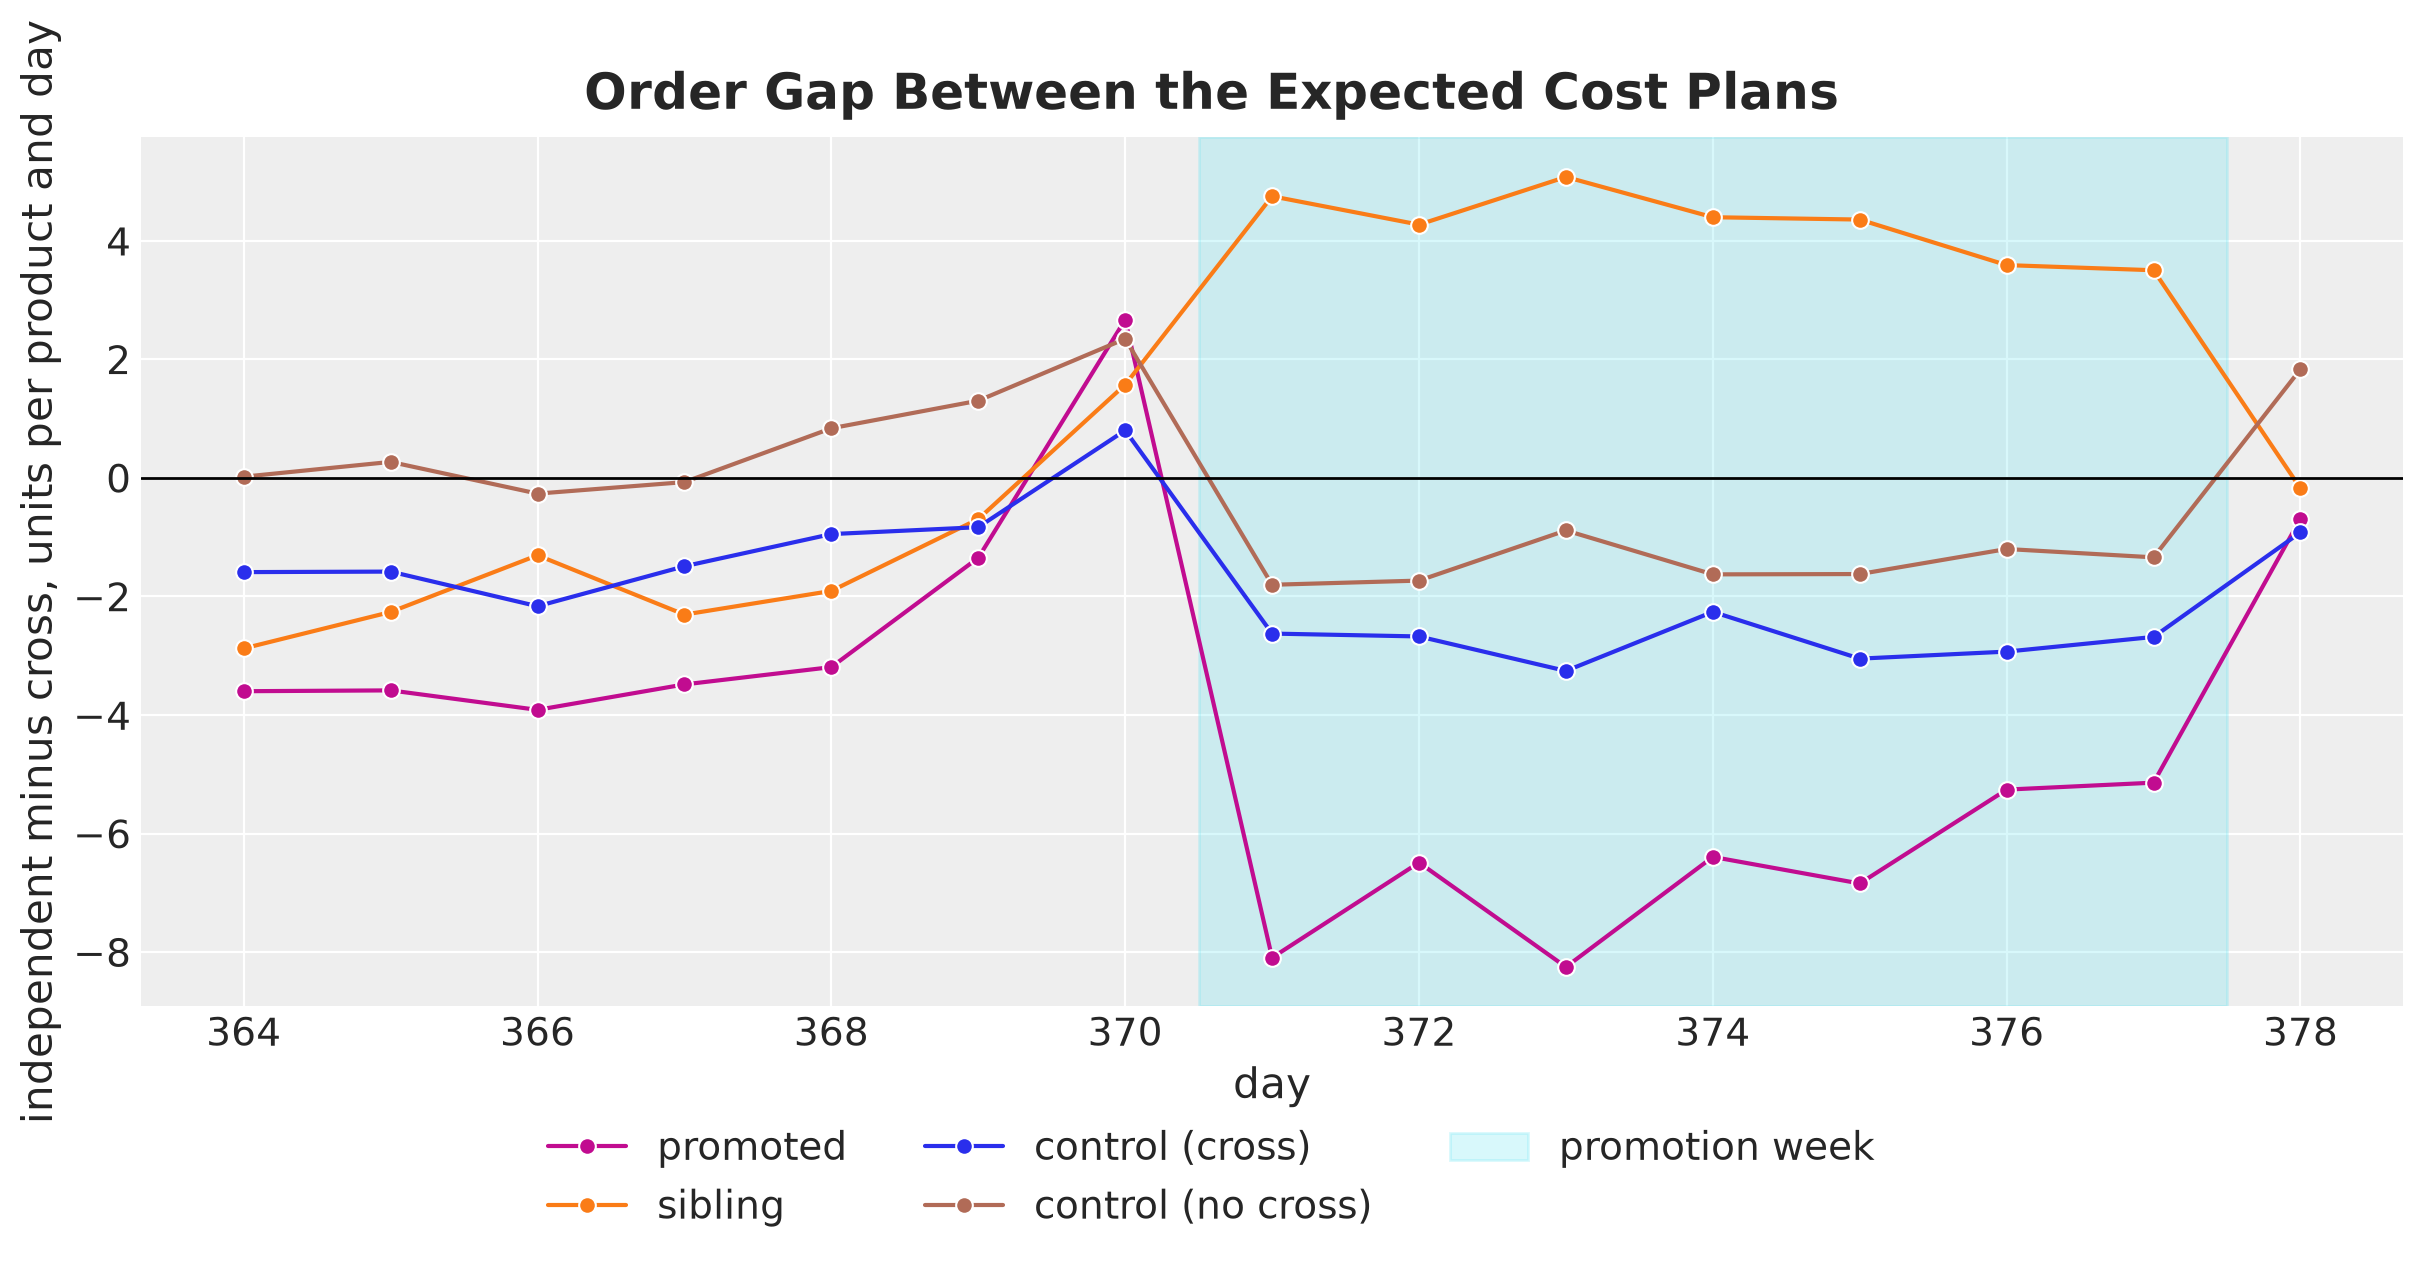

In [44]:
order_gap = pl.DataFrame(
    {
        "role": np.repeat(ROLES, setup.horizon),
        "day": np.tile(days_future, len(ROLES)),
        "order difference": np.concatenate(
            [
                np.asarray(
                    orders_expected["independent"][:, :, product_role == role]
                    - orders_expected["cross"][:, :, product_role == role]
                ).mean(axis=(1, 2))
                for role in ROLES
            ]
        ),
    }
)

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(
    data=order_gap,
    x="day",
    y="order difference",
    hue="role",
    hue_order=ROLES,
    palette=ROLE_COLORS,
    marker="o",
    ax=ax,
)
ax.axhline(0.0, color="black", linewidth=1)
shade_promotion_week(ax)
ax.get_legend().remove()
ax.set(xlabel="day", ylabel="independent minus cross, units per product and day")
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle(
    "Order Gap Between the Expected Cost Plans", fontsize=18, fontweight="bold"
);

The figure has three parts, and each one matches a feature of the forecasts.

- **Days $1$ to $6$.** The independent plan orders less than the cross plan on every role with cannibalization in its history, by $1$ to $4$ units per product and day on the promoted products, $1$ to $3$ units on the siblings and $1$ to $2$ units on the control group with cross effects, and within about one unit of the cross plan on the control group without. This is the low level of the independent model.
- **Day $7$.** The gap turns positive on every role, by $1$ to $3$ units per product and day, including the control group without cross effects. The independent model expects a larger total demand in the promotion week, since it does not expect the siblings to dip, so its plan sees a tighter capacity in that week and moves orders of every product to the day before it.
- **Promotion week.** The independent plan orders $3.5$ to $5$ units more per sibling and day, and $5$ to $8$ units less per promoted product and day. The capacity is full under both plans, so the units the independent plan gives to the siblings come out of the promoted products and the two control groups, which lose $1$ to $3.5$ units per product and day.

On the last day the two plans are within about two units per product on every role, because both are at capacity in every store.

## Out of Sample Evaluation

We score every plan on the $3{,}000$ evaluation scenarios of the true process with four metrics, and on the one realized future.

- **Expected loss.** The mean over the evaluation scenarios of the loss summed over the series.
- **CVaR of the loss.** The mean of the worst $5\%$ of the scenario losses, the tail average.
- **Stockout probability per series-day.** The fraction of scenario, series and day triples with a lost sale.
- **Probability of a stockout in the horizon per series.** The fraction of scenario and series pairs with at least one lost sale in the $15$ days.
- **Loss on the realized future.** The loss of the plan against the one true future path we held out when we generated the data.

For every plan we also record the expected loss on the optimization scenarios of its own model, the value the solver sees, next to the expected loss on the true process.

In [45]:
class Metric(StrEnum):
    """Names of the scores."""

    EXPECTED_LOSS = "expected loss"
    CVAR = f"CVaR of loss (worst {ALPHA:.0%})"
    STOCKOUT = "stockout probability per series-day"
    HORIZON = "probability of a stockout in the horizon per series"
    REALIZED = "loss on the realized future"
    OWN_SCENARIOS = "expected loss on own scenarios"


def summarize(plan: Plan, sim: Simulation) -> dict[Metric, float]:
    """Scores of one plan on the evaluation scenarios, the realized future, its own."""
    losses = sim.loss.sum(axis=-1)
    stockout = is_stockout(sim)
    realized = simulate_series(
        flat(plan.orders), demand_future_true, initial_inventory, config
    ).loss.sum()
    own = objective(plan.orders, demand_opt[plan.model], 0.0, initial_inventory, config)
    return {
        Metric.EXPECTED_LOSS: float(losses.mean()),
        Metric.CVAR: float(cvar(losses)),
        Metric.STOCKOUT: float(stockout.mean()),
        Metric.HORIZON: float(stockout.any(axis=-1).mean()),
        Metric.REALIZED: float(realized),
        Metric.OWN_SCENARIOS: float(own),
    }


scores = {
    plan.name: simulate_scenarios(
        flat(plan.orders), demand_eval, initial_inventory, config
    )
    for plan in plans
}
results = pl.DataFrame(
    [{"plan": plan.name, **summarize(plan, scores[plan.name])} for plan in plans]
)
results

plan,expected loss,CVaR of loss (worst 5%),stockout probability per series-day,probability of a stockout in the horizon per series,loss on the realized future,expected loss on own scenarios
str,f64,f64,f64,f64,f64,f64
"""Mean forecast (independent)""",34222.308594,37218.613281,0.273705,0.82659,34407.28125,30376.638672
"""Mean forecast (cross)""",29334.341797,32068.130859,0.232611,0.781027,30070.480469,28400.783203
"""Expected cost (independent)""",28394.855469,30868.964844,0.135505,0.514848,29030.404297,24673.025391
"""Expected cost (cross)""",25913.472656,28170.300781,0.109497,0.449128,27444.375,23295.634766


Let's look at the four scores of each plan in one figure. The black markers on the first panel are the losses on the realized future.

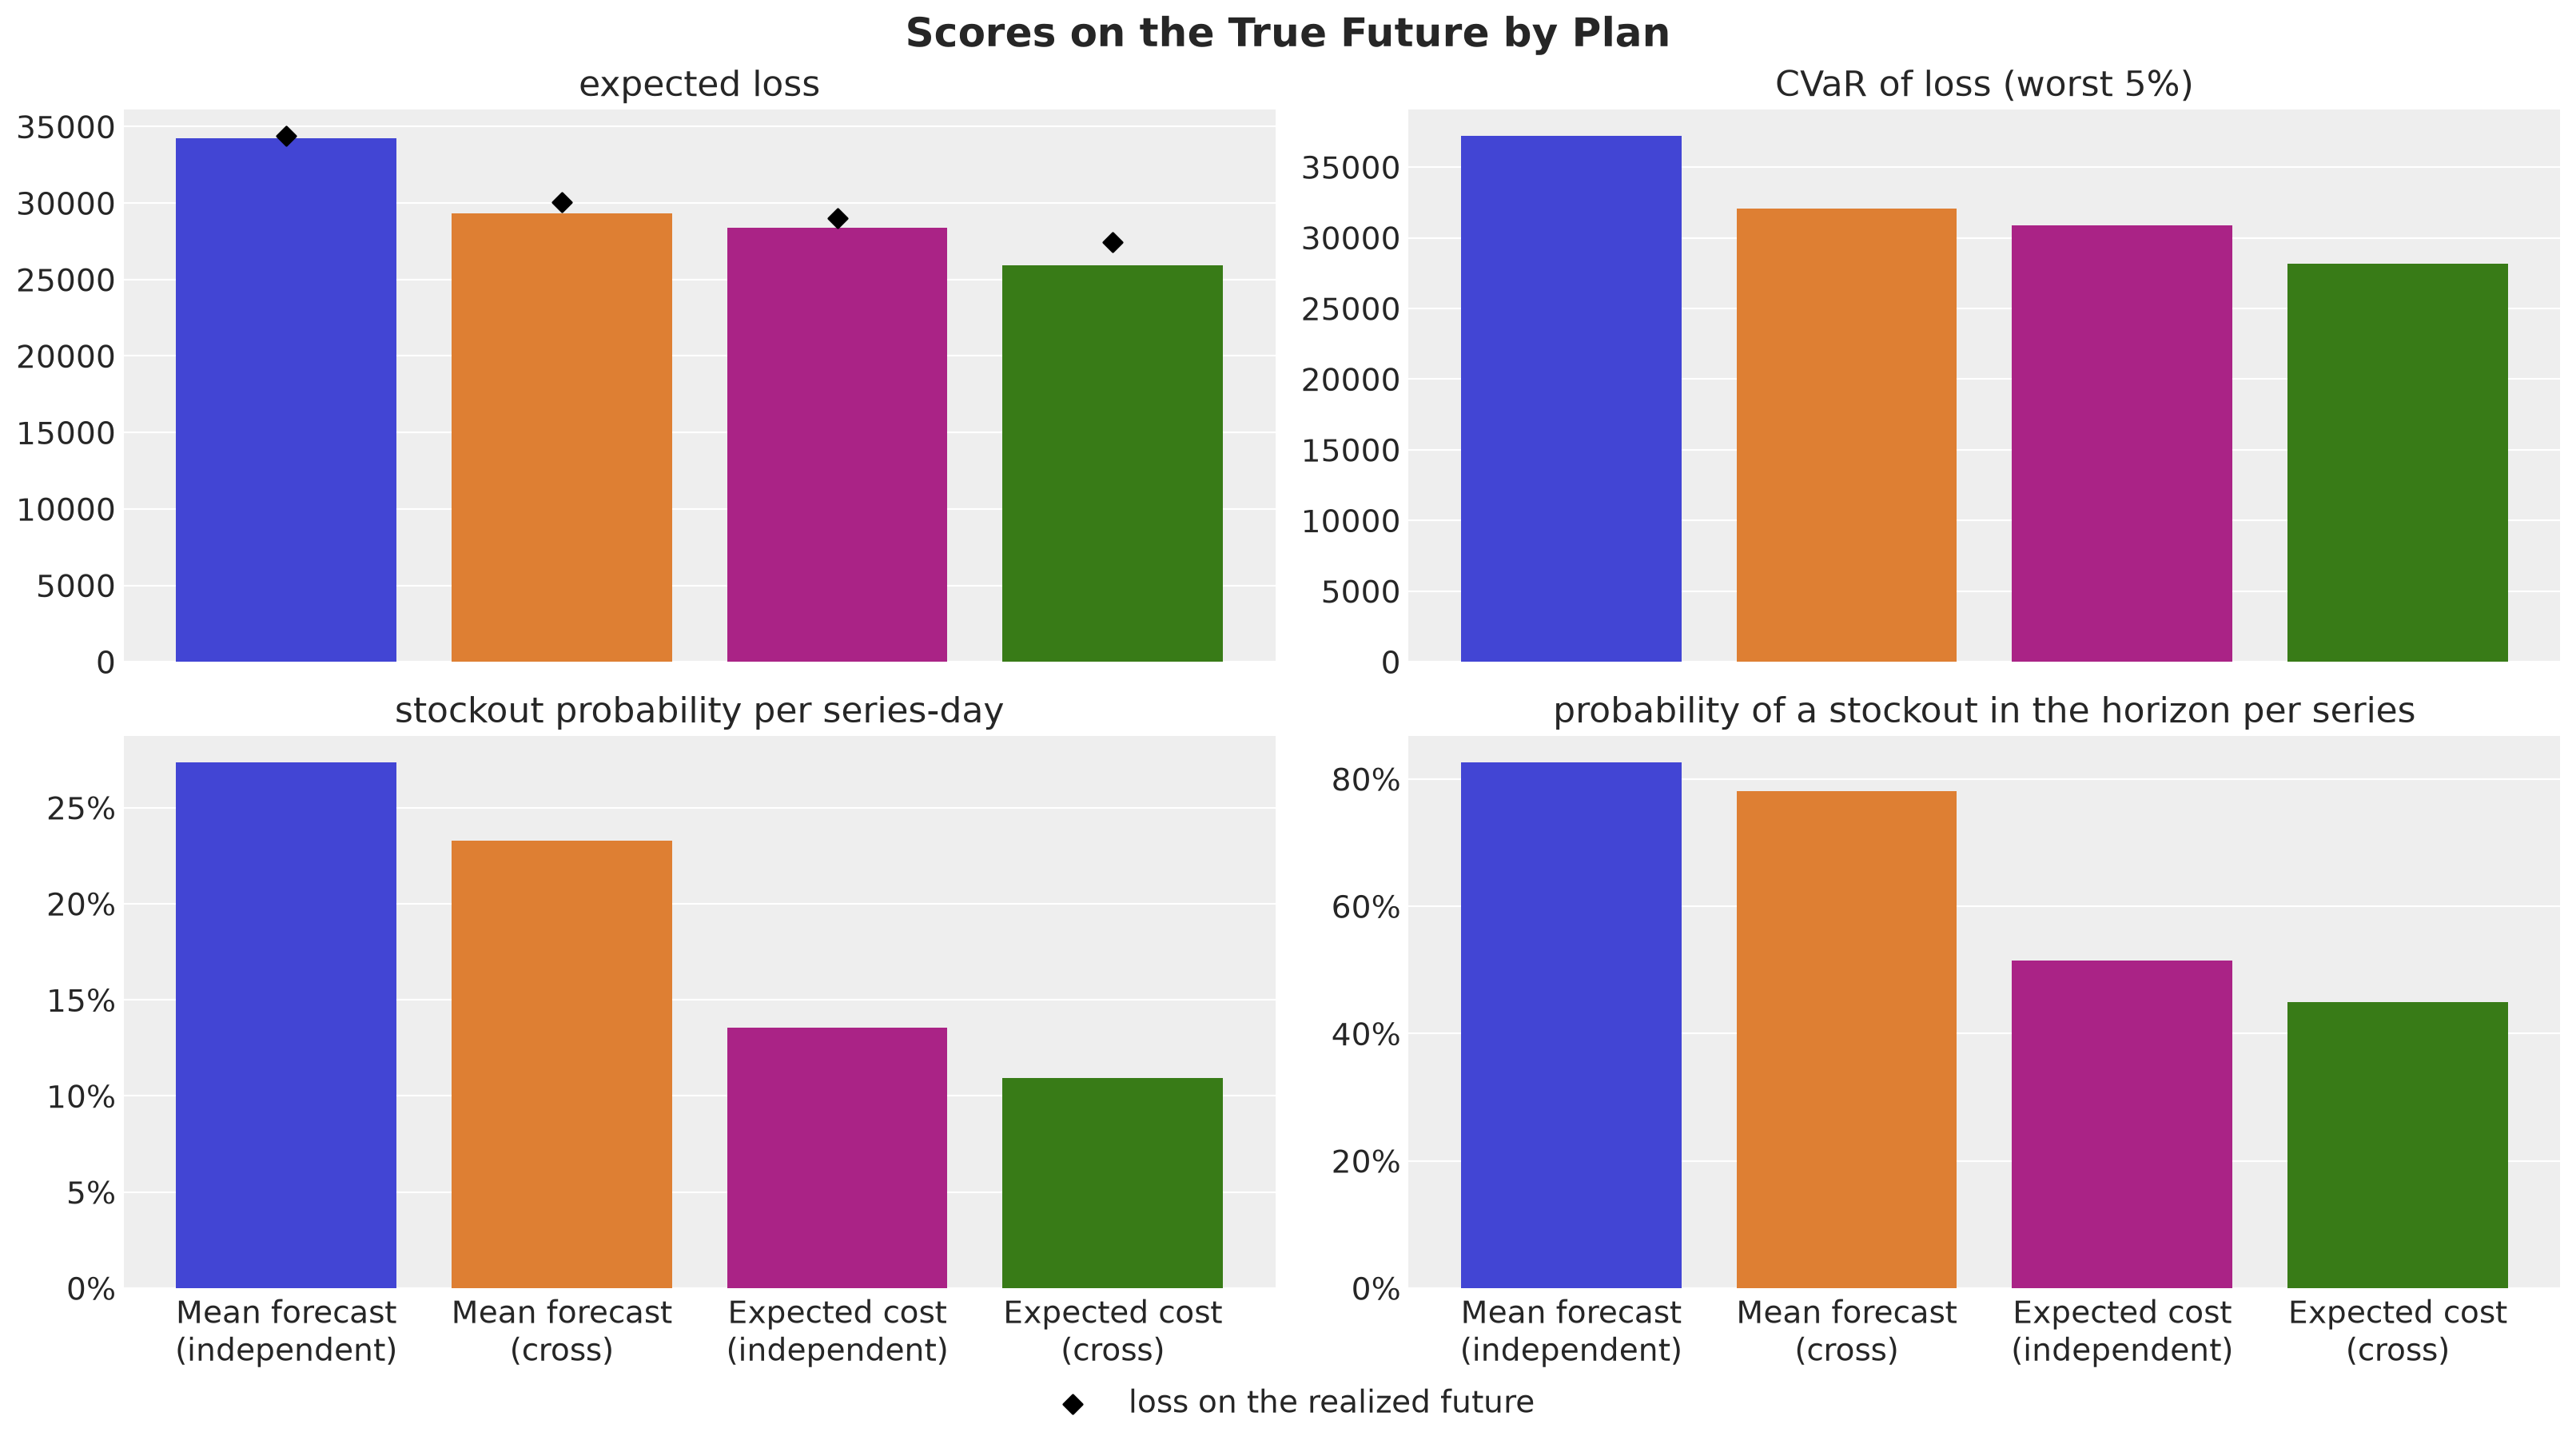

In [46]:
metrics = [Metric.EXPECTED_LOSS, Metric.CVAR, Metric.STOCKOUT, Metric.HORIZON]
PROBABILITY_METRICS = {Metric.STOCKOUT, Metric.HORIZON}
plan_labels = [name.replace(" (", "\n(") for name in plan_names]

fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(16, 9), sharex=True, layout="constrained"
)
for ax, metric in zip(axes.flat, metrics, strict=True):
    sns.barplot(
        data=results,
        x="plan",
        y=metric,
        hue="plan",
        hue_order=plan_names,
        palette=PLAN_COLORS,
        legend=False,
        ax=ax,
    )
    if metric in PROBABILITY_METRICS:
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set(title=metric, xlabel="", ylabel="")
realized_marker = axes[0, 0].scatter(
    range(len(plans)),
    results[Metric.REALIZED],
    color="black",
    marker="D",
    zorder=3,
    label=Metric.REALIZED,
)
for ax in axes[-1]:
    ax.set_xticks(range(len(plans)), plan_labels)
fig.legend(handles=[realized_marker], loc="outside lower center")
fig.suptitle("Scores on the True Future by Plan", fontsize=18, fontweight="bold");

The four plans are ordered the same way on every metric, and the two gaps of the two-by-two design read off the first panel.

- **Point forecast against distribution.** Within a model, the mean forecast plan costs $21\%$ more than the expected cost plan under the independent model ($34{,}222$ against $28{,}395$) and $13\%$ more under the cross model ($29{,}334$ against $25{,}913$). This is the finding of the first post, repeated on $200$ series.
- **Independent against cross.** Within a rule, the independent model costs $17\%$ more than the cross model under the mean forecast rule and $10\%$ more under the expected cost rule ($28{,}395$ against $25{,}913$). This is the cost of ignoring cannibalization.
- **The rule matters as much as the model here.** The mean forecast plan of the right model costs $3\%$ more than the expected cost plan of the wrong model. Getting the decision rule of the first post right comes first, and the forecast comes right after.
- **Service.** The stockout probability per series-day falls from $27\%$ and $23\%$ under the mean forecast plans to $14\%$ and $11\%$ under the expected cost plans, and the probability of at least one stockout per series in the horizon from $83\%$ and $78\%$ to $51\%$ and $45\%$.
- **Realized future.** The losses on the one realized path, the black markers, sit within $6\%$ of the expected losses and keep the same order.

Here is one more observation, from the last column of the table. The two solved plans cost more on the true future than on the scenarios of their own model: $11\%$ more for the expected cost (cross) plan ($25{,}913$ against $23{,}296$) and $15\%$ more for the expected cost (independent) plan. In the first post the two numbers agreed to within $1\%$, because the held-out scenarios came from the same posterior. Here the evaluation scenarios come from the true process, and the gap is consistent with a forecast that is wrong about the level of each series. We saw in the *Parameter Recovery* section that the posterior mean of the level at the end of the history is off by about $0.06$ on the log scale for a typical series, about $6\%$ of the level and twice what the guide believes, and that the first-week forecast of a series starts up to $13\%$ away from the truth. A plan built on scenarios that are centered $10\%$ too low pays the margin on the lost sales, and one built $10\%$ too high pays holding on the buffer, so the plans pay on the true future for an error that their own scenarios do not contain.

Each of these scores is an average over the evaluation scenarios. The next figure shows the distribution behind the averages: for each plan, the mean and the central $50\%$ and $94\%$ of the loss over the evaluation scenarios.

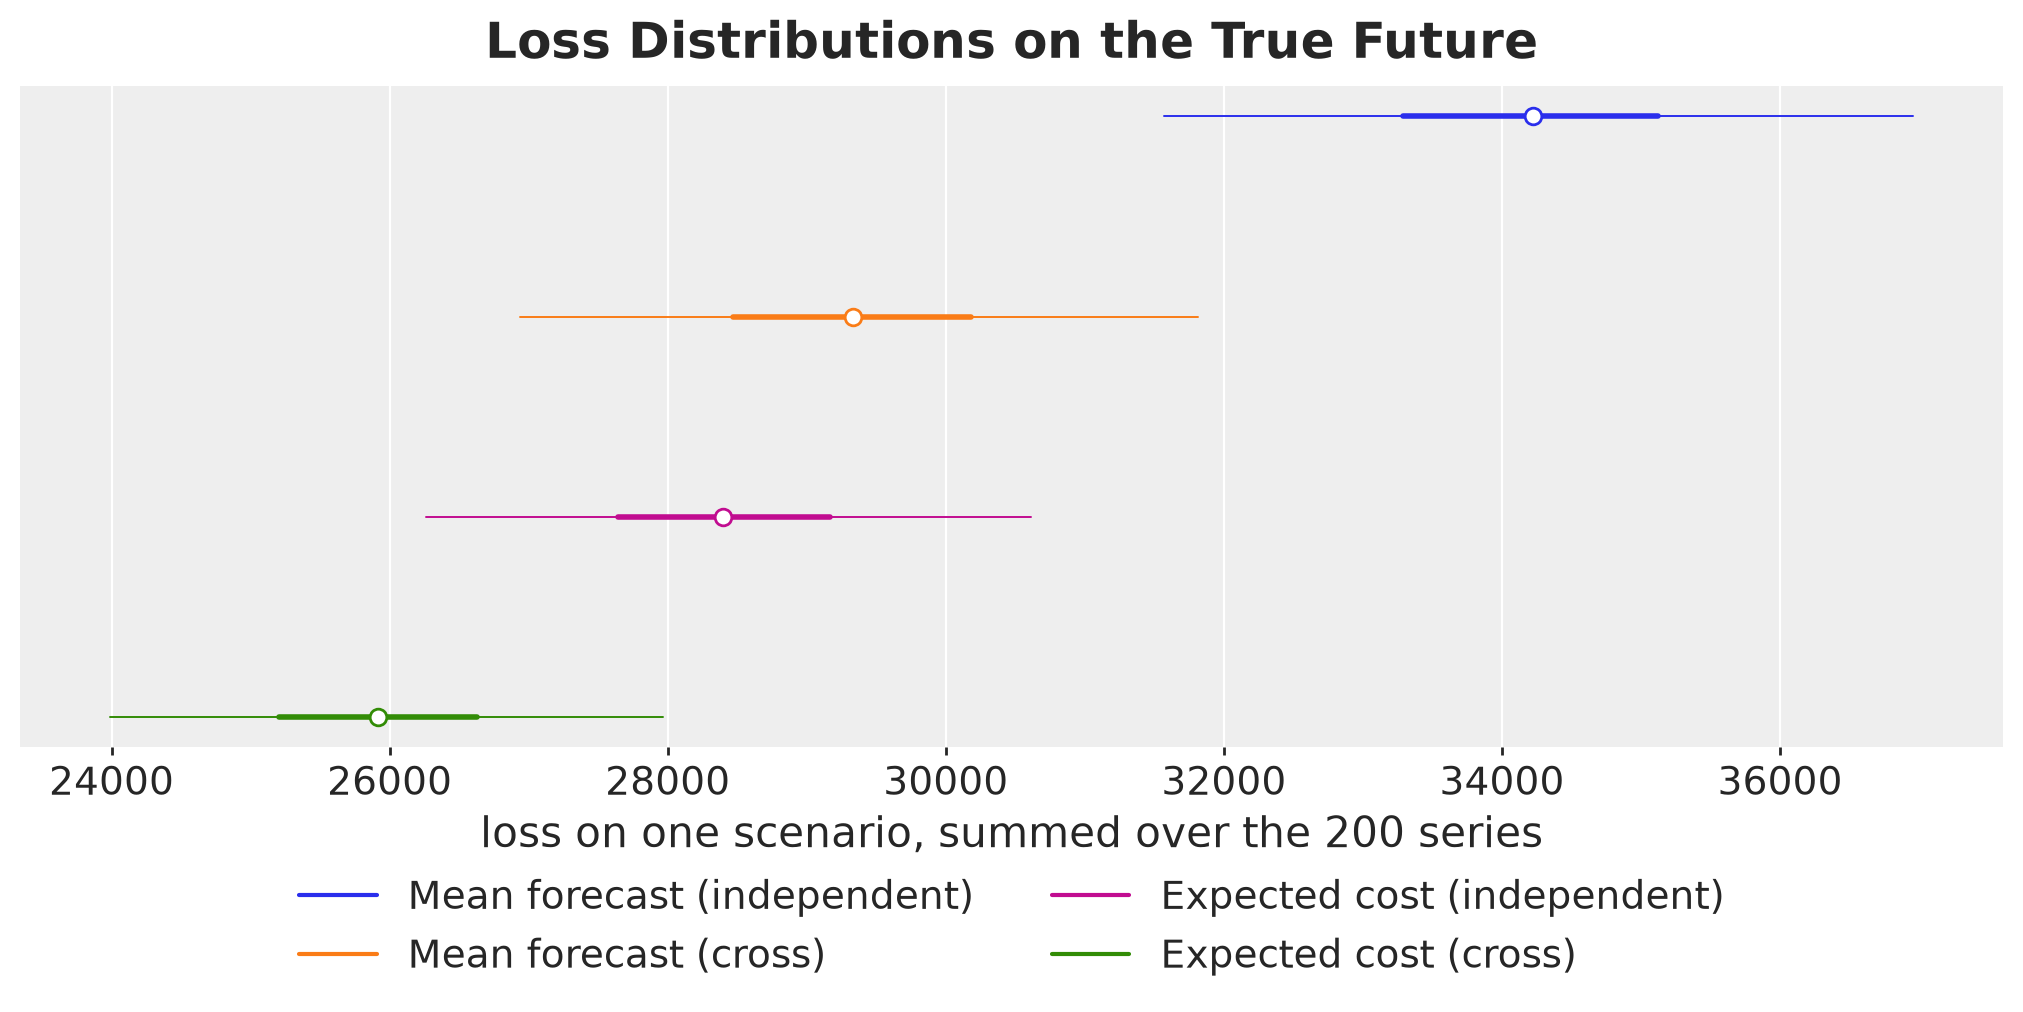

In [47]:
losses_by_plan = {
    name: xr.Dataset({"loss": (("sample",), np.asarray(sim.loss.sum(axis=-1)))})
    for name, sim in scores.items()
}

pc = az.plot_forest(
    losses_by_plan,
    sample_dims=["sample"],
    color=[PLAN_COLORS[name] for name in plan_names],
    labels=[],
    figure_kwargs={"figsize": (10, 5)},
)
pc.viz["plot"].sel(column="labels").item().remove()  # the empty label column
ax = pc.viz["plot"].sel(column="forest").item()
ax.set_subplotspec(ax.get_gridspec()[0, :])  # let the forest span the full width
ax.set(xlabel="loss on one scenario, summed over the 200 series", yticks=[])
pc.add_legend("model", title="", loc="outside lower center", ncol=2)
pc.viz["figure"].item().suptitle(
    "Loss Distributions on the True Future", fontsize=18, fontweight="bold"
);

The dots are the means and the thick and thin bars the $50\%$ and $94\%$ intervals. The four distributions keep the order of the means, and the $50\%$ intervals of the two expected cost plans do not overlap: about $25{,}200$ to $26{,}600$ for the cross plan against about $27{,}600$ to $29{,}200$ for the independent plan. The intervals are narrow against the means, and the tails are short. The loss sums $200$ series whose scenarios are only weakly linked, so the tail average is $1.09$ times the expected loss for every plan, against about $3$ for the mean forecast plan of the first post. There is not much of a tail to protect against.

**Remark:** In the first post the CVaR plan, the expected cost plan with a tail weight $\lambda = 1$, had a visibly lower tail loss than the expected cost plan. Here we solve it on the cross scenarios and score it the same way, to see whether the tail weight changes anything when the loss sums $200$ series.

In [48]:
orders_cvar_cross, _ = solve_jit(
    demand_opt["cross"], 1.0, orders_mean["cross"], capacity, initial_inventory, config
)
cvar_plan = Plan("CVaR (cross)", "cross", orders_cvar_cross)
cvar_check = pl.DataFrame(
    [
        {"plan": name, **summarize(plan, sim)}
        for name, plan, sim in [
            (
                "Expected cost (cross)",
                plans_by_name["Expected cost (cross)"],
                scores["Expected cost (cross)"],
            ),
            (
                cvar_plan.name,
                cvar_plan,
                simulate_scenarios(
                    flat(cvar_plan.orders), demand_eval, initial_inventory, config
                ),
            ),
        ]
    ]
).select("plan", Metric.EXPECTED_LOSS, Metric.CVAR, Metric.STOCKOUT)
cvar_check

plan,expected loss,CVaR of loss (worst 5%),stockout probability per series-day
str,f64,f64,f64
"""Expected cost (cross)""",25913.472656,28170.300781,0.109497
"""CVaR (cross)""",26113.855469,28355.75,0.110408


The CVaR plan lands within $1\%$ of the expected cost plan on the three scores, and on the wrong side of it on all three: $26{,}114$ against $25{,}913$ in expected loss and $28{,}356$ against $28{,}170$ in tail loss. The tail weight changes nothing here because the tail is thin: the loss of a scenario is a sum over $200$ series, the high and the low series of a scenario cancel, and the worst $5\%$ of the scenarios are not far from the average one. In the first post the tail was three times the mean and the weight moved the plan. We keep the expected cost plans from here on.

### Where the Cost Comes From

To see where the cost of ignoring cannibalization comes from, we split the expected loss of the two expected cost plans on the true future by product role and by cost part, holding and lost sales. The first table and figure show the split over the whole horizon. The second ones show the difference between the two plans, independent minus cross, for each part of the horizon.

In [49]:
def loss_parts(sim: Simulation, days_slice: slice) -> tuple[np.ndarray, np.ndarray]:
    """Expected holding cost and lost sales cost per series over some days."""
    holding = config.holding_cost * np.asarray(
        sim.inventory[:, :, days_slice].sum(axis=-1)
    ).mean(axis=0)
    lost = config.lost_sales_cost * np.asarray(
        sim.lost_sales[:, :, days_slice].sum(axis=-1)
    ).mean(axis=0)
    return holding, lost


decomposition = pl.DataFrame(
    [
        {
            "plan": name,
            "period": period,
            "role": role,
            "part": part,
            "expected loss": float(values[series_role == role].sum()),
        }
        for name in expected_cost_plans
        for period, days_slice in WEEKS.items()
        for part, values in zip(
            ["holding", "lost sales"], loss_parts(scores[name], days_slice), strict=True
        )
        for role in ROLES
    ]
)
totals = (
    decomposition.group_by("plan", "role", "part")
    .agg(pl.col("expected loss").sum())
    .sort("plan", "role", "part")
)
totals.pivot(on="plan", index=["role", "part"], values="expected loss")

role,part,Expected cost (cross),Expected cost (independent)
str,str,f64,f64
"""control (cross)""","""holding""",1916.488647,1425.292458
"""control (cross)""","""lost sales""",1708.549316,2700.532104
"""control (no cross)""","""holding""",2502.163605,2471.837936
"""control (no cross)""","""lost sales""",1349.564339,1409.534729
"""promoted""","""holding""",3726.290222,2765.232574
"""promoted""","""lost sales""",1432.201202,2849.038734
"""sibling""","""holding""",8942.5755,9709.758301
"""sibling""","""lost sales""",4335.660004,5063.612946


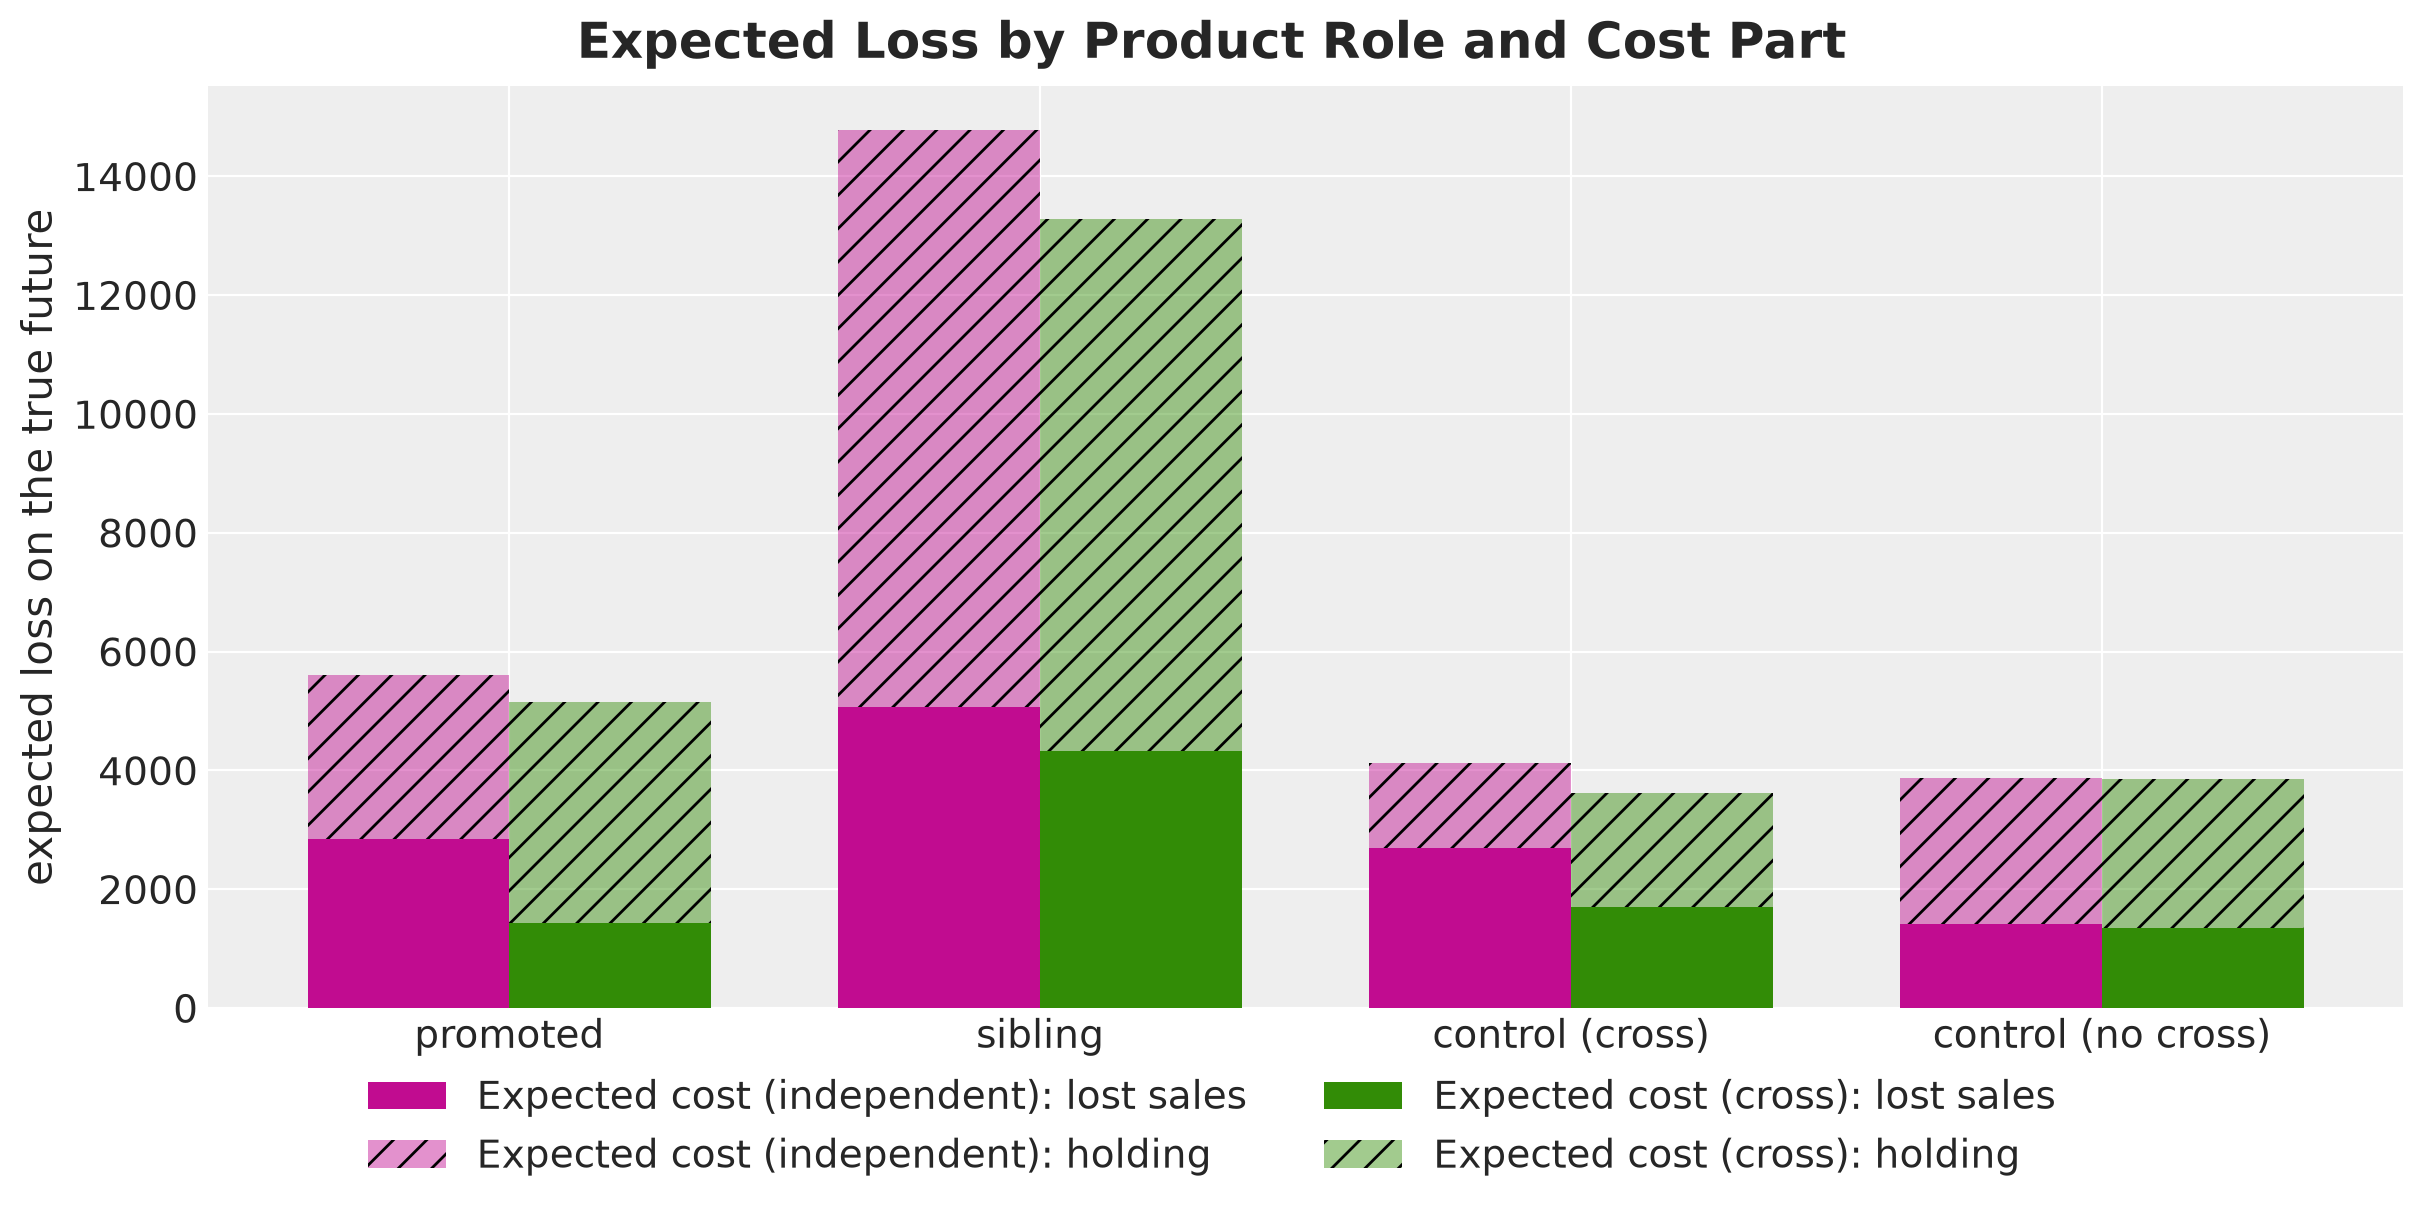

In [50]:
fig, ax = plt.subplots(figsize=(12, 6))
width = 0.38
for k, name in enumerate(expected_cost_plans):
    sub = totals.filter(pl.col("plan") == name)
    lost = np.array(
        [
            sub.filter((pl.col("role") == role) & (pl.col("part") == "lost sales"))[
                "expected loss"
            ][0]
            for role in ROLES
        ]
    )
    holding = np.array(
        [
            sub.filter((pl.col("role") == role) & (pl.col("part") == "holding"))[
                "expected loss"
            ][0]
            for role in ROLES
        ]
    )
    x = np.arange(len(ROLES)) + (k - 0.5) * width
    ax.bar(x, lost, width=width, color=PLAN_COLORS[name], label=f"{name}: lost sales")
    ax.bar(
        x,
        holding,
        width=width,
        bottom=lost,
        color=PLAN_COLORS[name],
        alpha=0.45,
        hatch="//",
        label=f"{name}: holding",
    )
ax.set(
    xticks=np.arange(len(ROLES)),
    xticklabels=ROLES,
    ylabel="expected loss on the true future",
)
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle(
    "Expected Loss by Product Role and Cost Part", fontsize=18, fontweight="bold"
);

The gap of $2{,}481$ between the two plans comes from the lost sales, and the holding is lower under the independent plan. Here is what the table and the figure show, role by role.

- **Promoted.** The independent plan pays $2{,}849$ in lost sales against $1{,}432$ for the cross plan, and $961$ less in holding. The three promoted products carry $18\%$ of the gap.
- **Sibling.** Both parts are higher under the independent plan, $9{,}710$ against $8{,}943$ in holding and $5{,}064$ against $4{,}336$ in lost sales. The nine siblings carry $60\%$ of the gap and are the largest cost under both plans, since they are the largest series.
- **Control (cross).** The independent plan pays $2{,}701$ in lost sales against $1{,}709$, and $491$ less in holding, which is $20\%$ of the gap. These four products have no promotion in the horizon, so this is the cost of the low level alone.
- **Control (no cross).** The two plans pay the same, within $5\%$ on both parts. This is the check that nothing else differs between the two pipelines.

In [51]:
gap_by_period = (
    decomposition.pivot(
        on="plan", index=["period", "role", "part"], values="expected loss"
    )
    .with_columns(
        gap=pl.col("Expected cost (independent)") - pl.col("Expected cost (cross)")
    )
    .select("period", "role", "part", "gap")
)
gap_by_period.pivot(on="period", index=["role", "part"], values="gap")

role,part,first week,promotion week,last day
str,str,f64,f64,f64
"""promoted""","""holding""",-205.89325,-635.190186,-119.974213
"""sibling""","""holding""",-289.841553,840.805176,216.219177
"""control (cross)""","""holding""",-112.731934,-315.240173,-63.224083
"""control (no cross)""","""holding""",27.790161,-45.329468,-12.786362
"""promoted""","""lost sales""",310.833527,1059.632751,46.371254
"""sibling""","""lost sales""",1102.707031,-321.040527,-53.713562
"""control (cross)""","""lost sales""",261.690002,668.73584,61.556946
"""control (no cross)""","""lost sales""",-32.731995,95.25238,-2.549995


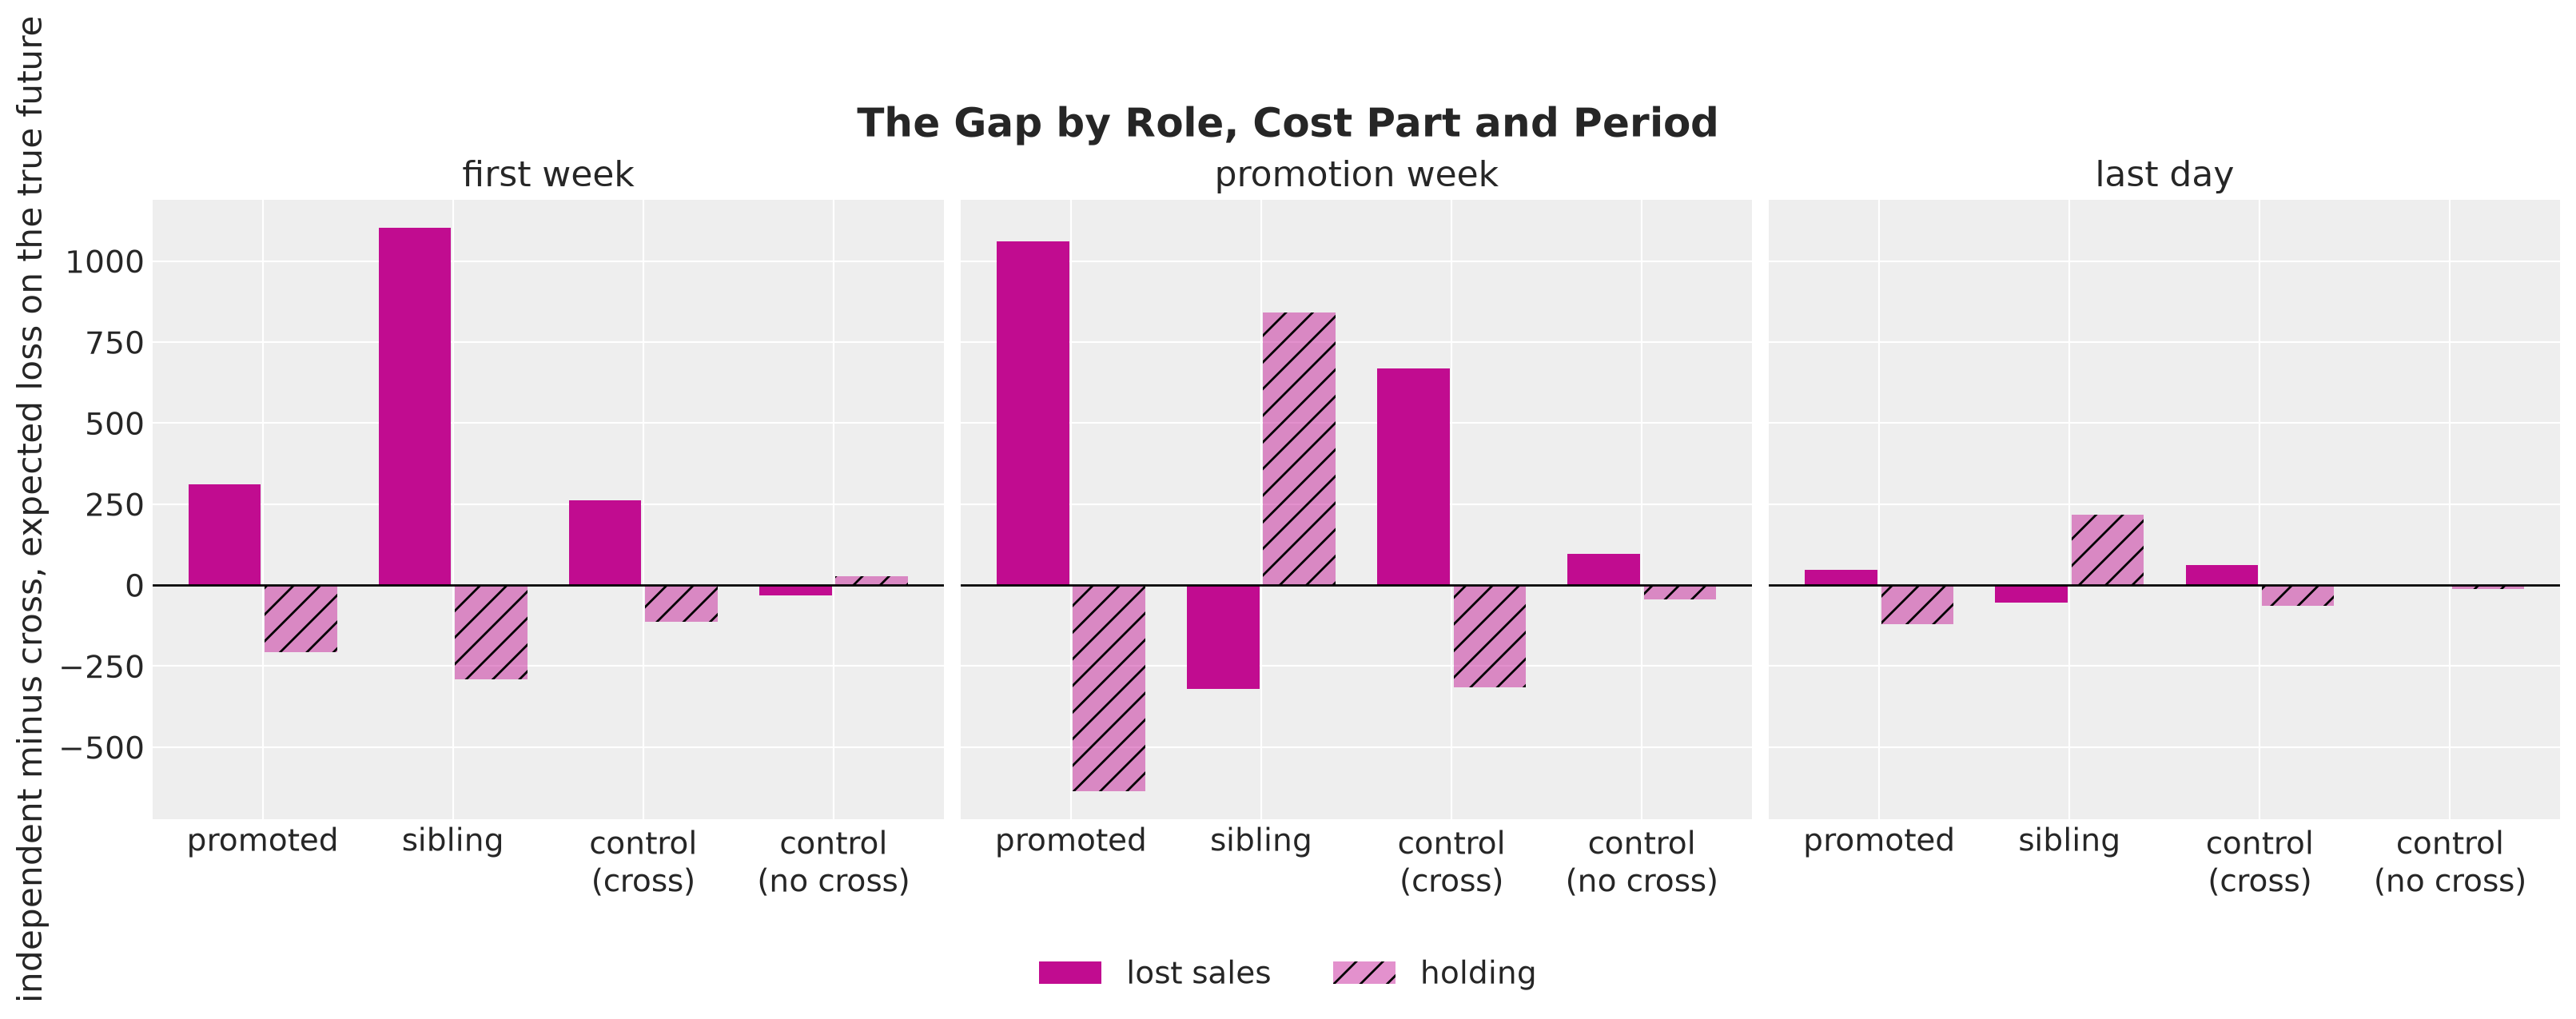

In [52]:
fig, axes = plt.subplots(ncols=3, figsize=(16, 5.5), sharey=True, layout="constrained")
for ax, period in zip(axes, WEEKS, strict=True):
    sub = gap_by_period.filter(pl.col("period") == period)
    for part, alpha, hatch in [("lost sales", 1.0, None), ("holding", 0.45, "//")]:
        values = np.array(
            [
                sub.filter((pl.col("role") == role) & (pl.col("part") == part))["gap"][
                    0
                ]
                for role in ROLES
            ]
        )
        ax.bar(
            np.arange(len(ROLES)) + (0.2 if part == "holding" else -0.2),
            values,
            width=0.38,
            color="C3",
            alpha=alpha,
            hatch=hatch,
            label=part,
        )
    ax.axhline(0.0, color="black", linewidth=1)
    ax.set(
        title=period,
        xticks=np.arange(len(ROLES)),
        xticklabels=[r.replace(" (", "\n(") for r in ROLES],
    )
axes[0].set(ylabel="independent minus cross, expected loss on the true future")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2)
fig.suptitle("The Gap by Role, Cost Part and Period", fontsize=18, fontweight="bold");

Here is what the three panels show, in order.

- **First week.** No promotion happens, and the independent plan pays $1{,}675$ more in lost sales on the promoted products, the siblings and the control group with cross effects, against $610$ less in holding. This is the low level of the independent model: it orders $1$ to $4$ units less per product and day, and with lost sales at twenty times the holding cost, the shortfalls cost more than the leftovers save.
- **Promotion week.** The siblings flip: the independent plan holds $841$ more on them and loses $321$ less, because it stocks them for a demand that drops. The promoted products pay $1{,}060$ more in lost sales under the independent plan and the control group with cross effects $669$ more. The capacity is full, and the units that went to the siblings are missing on the products whose demand is there.
- **Last day.** The parts are small and of both signs.

So the cost of ignoring cannibalization has two sources of about the same size. The first is the level: a model that cannot explain the dips of the past starts the horizon too low, on every product with cannibalization in its history, and pays lost sales from day one. The second is the promotion week: the model stocks the siblings for a demand that does not come, and under a shared capacity those units are taken from the promoted products and from the control group with cross effects.

The lost sales of the first week deserve a closer look, since no promotion happens there. The next figure shows the stockout probability per day under the two expected cost plans, averaged over the series of each role.

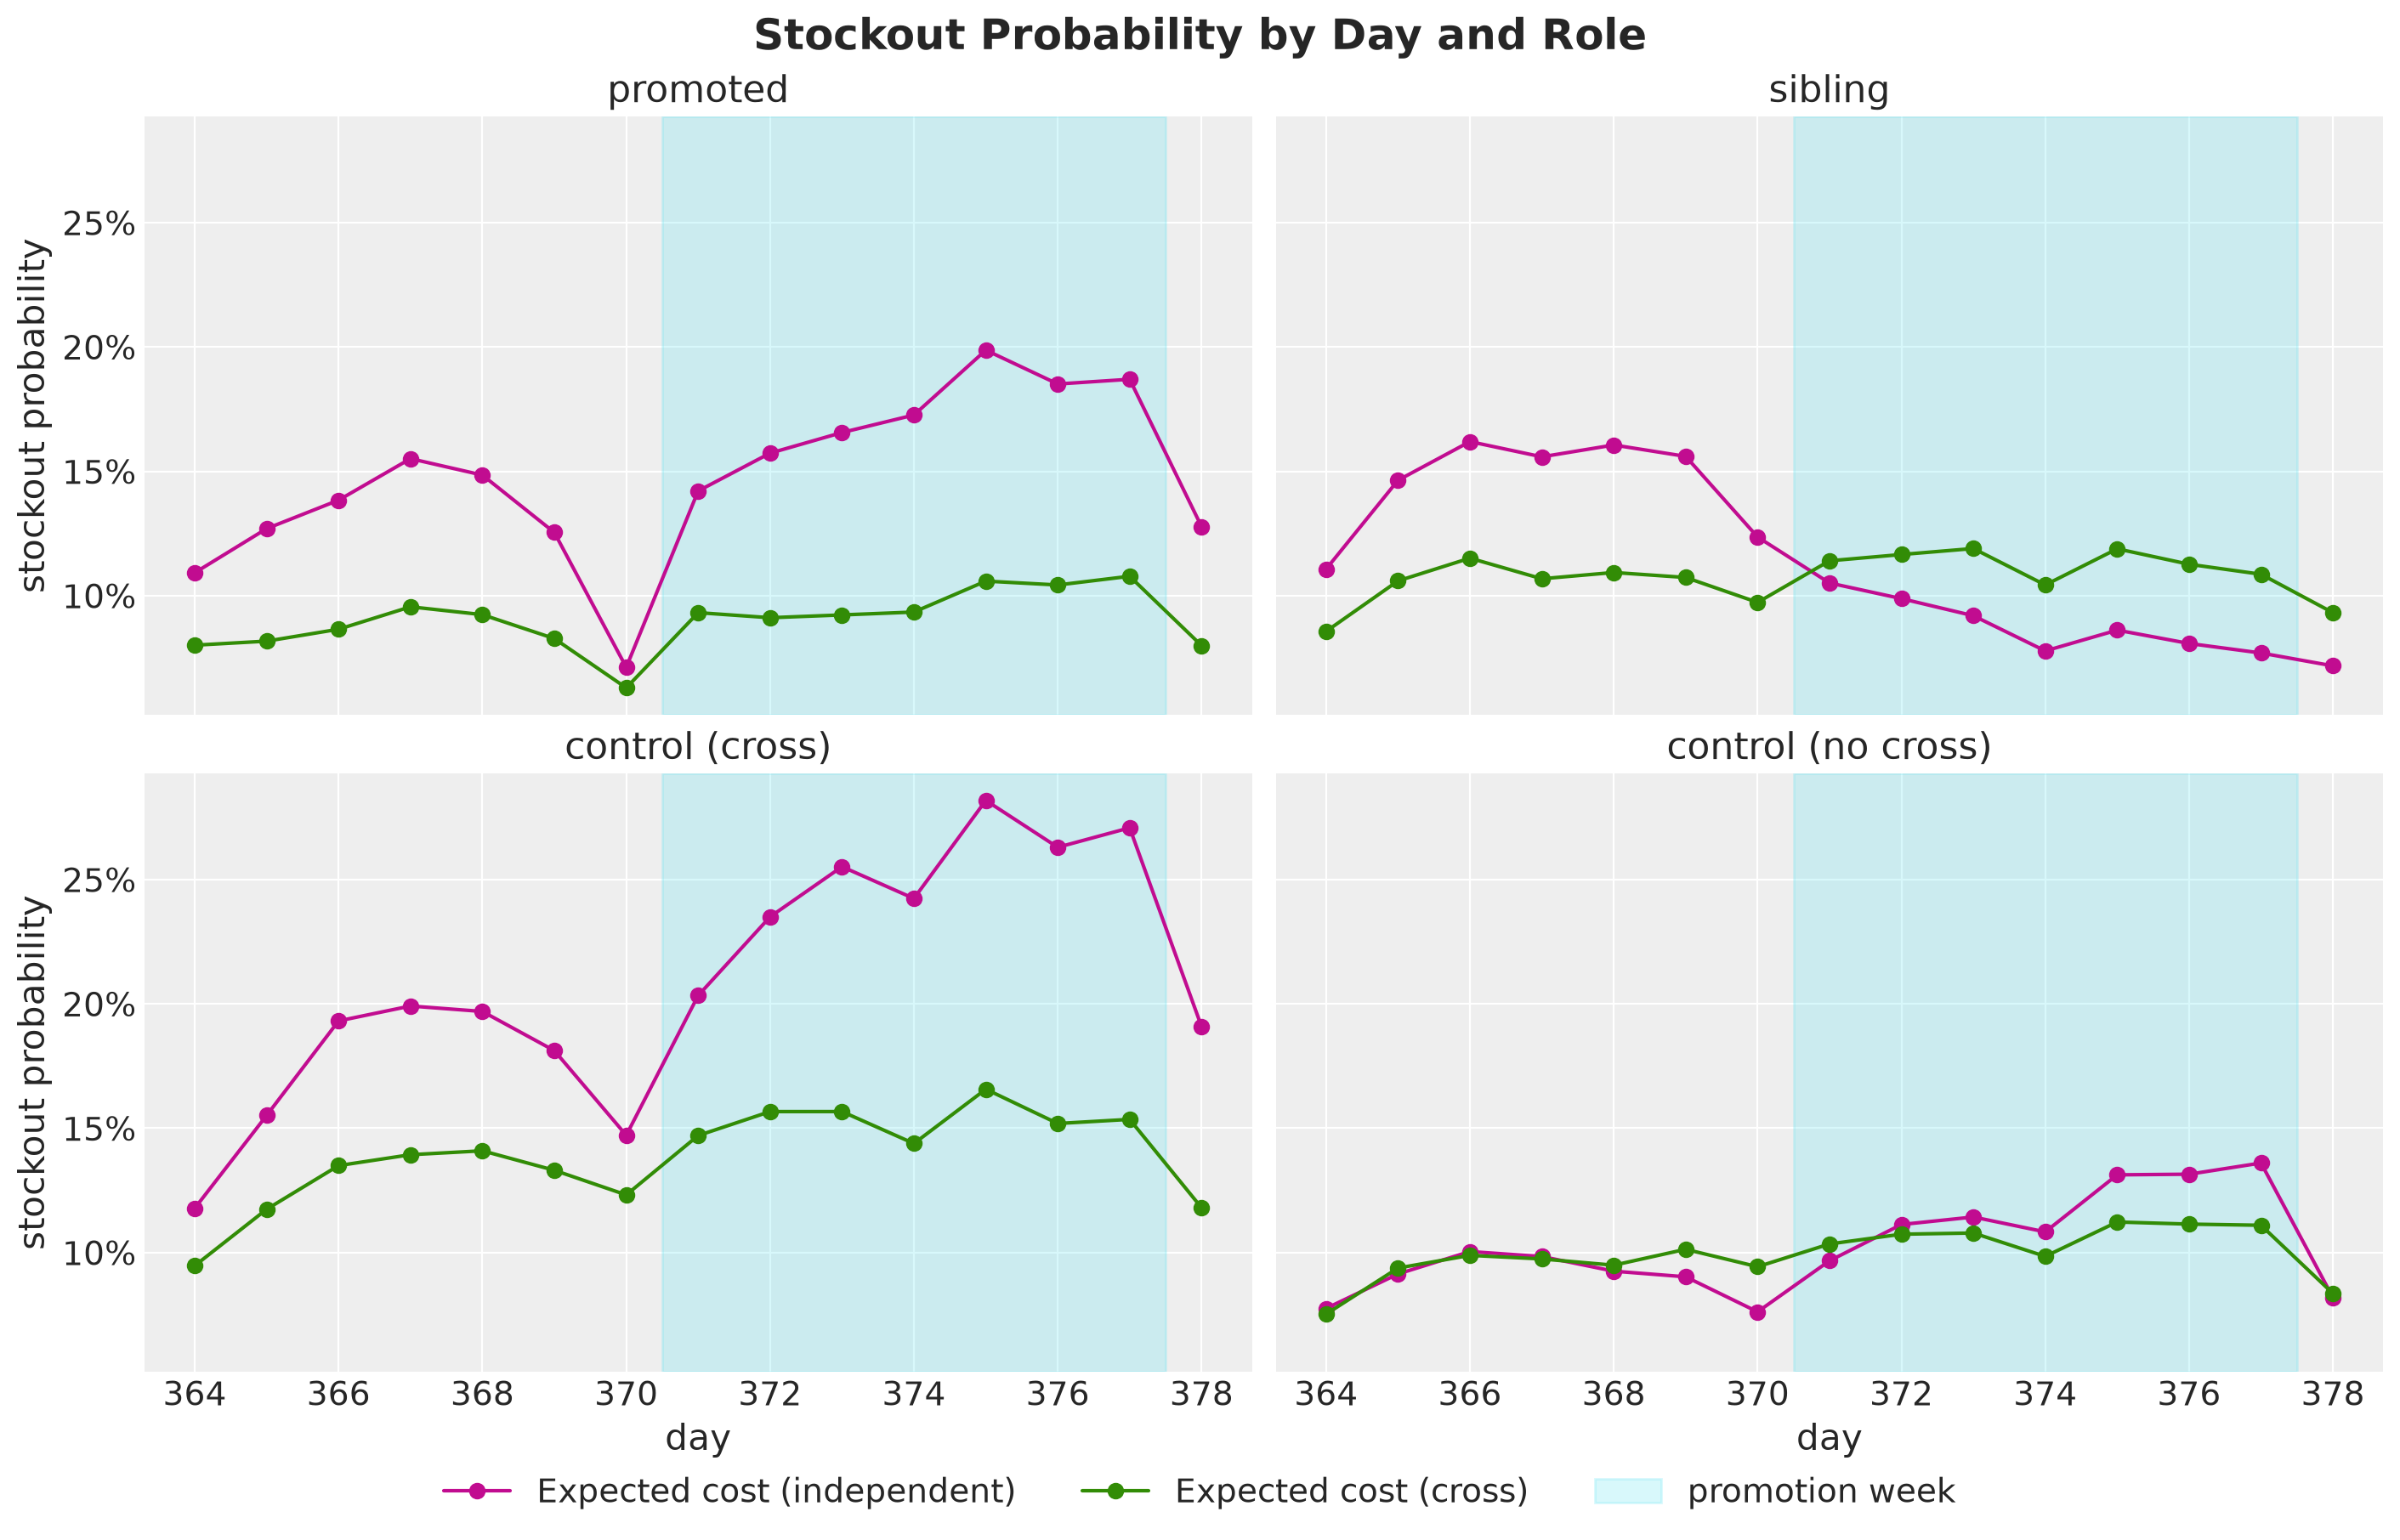

In [53]:
fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(14, 9), sharex=True, sharey=True, layout="constrained"
)
for k, (ax, role) in enumerate(zip(axes.flat, ROLES, strict=True)):
    for name in expected_cost_plans:
        prob = np.asarray(is_stockout(scores[name]).mean(axis=0))[
            series_role == role
        ].mean(axis=0)
        ax.plot(days_future, prob, "o-", color=PLAN_COLORS[name], label=name)
    shade_promotion_week(ax)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set(
        title=role,
        xlabel="day" if k >= 2 else "",
        ylabel="stockout probability" if k % 2 == 0 else "",
    )
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle("Stockout Probability by Day and Role", fontsize=18, fontweight="bold");

Here is what the four panels show, role by role, with the two plans in the colors of the model that built them.

- **Promoted.** The independent plan runs out on $13\%$ of the series-days of the first week against $8\%$ for the cross plan, and on $17\%$ against $10\%$ in the promotion week.
- **Sibling.** The independent plan runs out more in the first week, $15\%$ against $10\%$, and less in the promotion week, $9\%$ against $11\%$, where it holds the stock it built for the dip it did not expect.
- **Control (cross).** The independent plan runs out on $17\%$ against $13\%$ in the first week and on $25\%$ against $15\%$ in the promotion week, with nothing promoted in this group. The second week is worse than the first because the capacity is full and the siblings of the promoted groups take the units.
- **Control (no cross).** The two plans agree within a few points on every day.

Both plans dip on the day before the promotion week, where they build stock, and the cross plan sits between $6\%$ and $17\%$ on every role and day. The expected cost plan has no service target, and these frequencies are what the costs imply under a capacity that binds for a week.

**Remark:** In the first post we shuffled the days of the scenarios to show that the carried stock needs joint draws over time. The scenarios here are also joint across series, since the series of a scenario share the same posterior draw of the parameters. To see what that link is worth, we shuffle the scenario index of every series independently, which keeps every single-series path and removes the dependence across series, solve the expected cost plan of the cross model on the shuffled scenarios, and score it on the true future.

In [54]:
rng_key, key_shuffle = random.split(rng_key)
shuffle_each_series = jax.vmap(random.permutation, in_axes=(0, 2), out_axes=2)
demand_shuffled = shuffle_each_series(
    random.split(key_shuffle, setup.n_series), demand_opt["cross"]
)
orders_shuffled, _ = solve_jit(
    demand_shuffled, 0.0, orders_mean["cross"], capacity, initial_inventory, config
)
shuffled_plan = Plan(
    "Expected cost (cross, shuffled across series)", "cross", orders_shuffled
)
joint_check = pl.DataFrame(
    [
        {
            "plan": "Expected cost (cross)",
            **summarize(
                plans_by_name["Expected cost (cross)"], scores["Expected cost (cross)"]
            ),
        },
        {
            "plan": shuffled_plan.name,
            **summarize(
                shuffled_plan,
                simulate_scenarios(
                    flat(orders_shuffled), demand_eval, initial_inventory, config
                ),
            ),
        },
    ]
).select("plan", Metric.EXPECTED_LOSS, Metric.CVAR, Metric.STOCKOUT)
joint_check

plan,expected loss,CVaR of loss (worst 5%),stockout probability per series-day
str,f64,f64,f64
"""Expected cost (cross)""",25913.472656,28170.300781,0.109497
"""Expected cost (cross, shuffled…",25913.482422,28170.28125,0.10947


The plan built on the shuffled scenarios scores the same as the plan built on the joint ones, to four digits. Under the expected cost rule the objective is a sum over the series of per-series expected losses, and the only link between the series is the capacity, so the plan depends on the marginal distribution of each series alone. The dependence across series would matter for a rule that looks at the total loss of a scenario, such as a tail weight or a chance constraint on the total, and we saw above that the tail is thin here. The joint draws over time of the first post remain necessary, since the stock carries over within a series.

## Capacity Sensitivity

We have seen the gap between the two expected cost plans at one capacity. Here we ask whether the capacity creates the gap or hides it. We sweep the capacity multiple $\kappa$ from $0.9$, where the capacity binds on a regular day, to no capacity at all, and solve the expected cost plan of both models at every value. Because `solve` is a pure function, the sweep over the capacity grid is one `jax.vmap` per model. We score every plan on the true future and split the gap into its holding and lost sales parts.

In [55]:
%%time

kappas = np.array([0.9, 1.0, 1.05, 1.1, 1.25, 1.5, np.inf])
capacity_grid = jnp.asarray(kappas[:, None] * regular_store[None, :])
# the mean forecast plan depends on the capacity through the projection, so the
# sweep rebuilds it at every capacity and starts each solve from it
mean_plan_sweep = jax.vmap(forward_pass_capacity, in_axes=(None, 0, None))
solve_sweep = jax.jit(
    jax.vmap(solve, in_axes=(None, None, 0, 0, None, None)),
    static_argnames=("config", "n_steps"),
)

sweep_rows = []
for name in models:
    orders_mean_grid = mean_plan_sweep(
        unflat(mean_demand[name]),
        capacity_grid,
        initial_inventory.reshape(setup.n_stores, setup.n_products),
    )
    orders_grid, _ = solve_sweep(
        demand_opt[name],
        0.0,
        orders_mean_grid,
        capacity_grid,
        initial_inventory,
        config,
    )
    for kappa, orders in zip(kappas, orders_grid, strict=True):
        sim = simulate_scenarios(flat(orders), demand_eval, initial_inventory, config)
        holding, lost = loss_parts(sim, slice(0, setup.horizon))
        sweep_rows.append(
            {
                "model": name,
                "kappa": float(kappa),
                "expected loss": float(sim.loss.sum(axis=-1).mean()),
                "holding": float(holding.sum()),
                "lost sales": float(lost.sum()),
            }
        )
sweep = pl.DataFrame(sweep_rows)
sweep_gap = (
    sweep.pivot(
        on="model", index="kappa", values=["expected loss", "holding", "lost sales"]
    )
    .with_columns(
        gap=pl.col("expected loss_independent") - pl.col("expected loss_cross"),
        relative_gap=(
            pl.col("expected loss_independent") - pl.col("expected loss_cross")
        )
        / pl.col("expected loss_cross"),
        holding_gap=pl.col("holding_independent") - pl.col("holding_cross"),
        lost_sales_gap=pl.col("lost sales_independent") - pl.col("lost sales_cross"),
    )
    .sort("kappa")
)
sweep_gap.select(
    "kappa",
    "expected loss_independent",
    "expected loss_cross",
    "relative_gap",
    "holding_gap",
    "lost_sales_gap",
)

CPU times: user 2min 17s, sys: 5.95 s, total: 2min 23s
Wall time: 39.2 s


kappa,expected loss_independent,expected loss_cross,relative_gap,holding_gap,lost_sales_gap
f64,f64,f64,f64,f64,f64
0.9,41631.824219,38478.207031,0.081959,857.886719,2295.695312
1.0,30163.787109,27426.09375,0.099821,-568.095703,3305.795898
1.05,28394.794922,25913.482422,0.095754,-715.363281,3196.705078
1.1,28034.847656,25601.759766,0.095036,-572.732422,3005.824219
1.25,27997.802734,25572.658203,0.094833,-454.742188,2879.87793
1.5,27997.802734,25572.658203,0.094833,-454.742188,2879.87793
inf,27997.802734,25572.658203,0.094833,-454.742188,2879.87793


We plot the expected loss of both plans against $\kappa$ on the left and the gap, split into its two parts, on the right. The last point on each axis is the plan without a capacity.

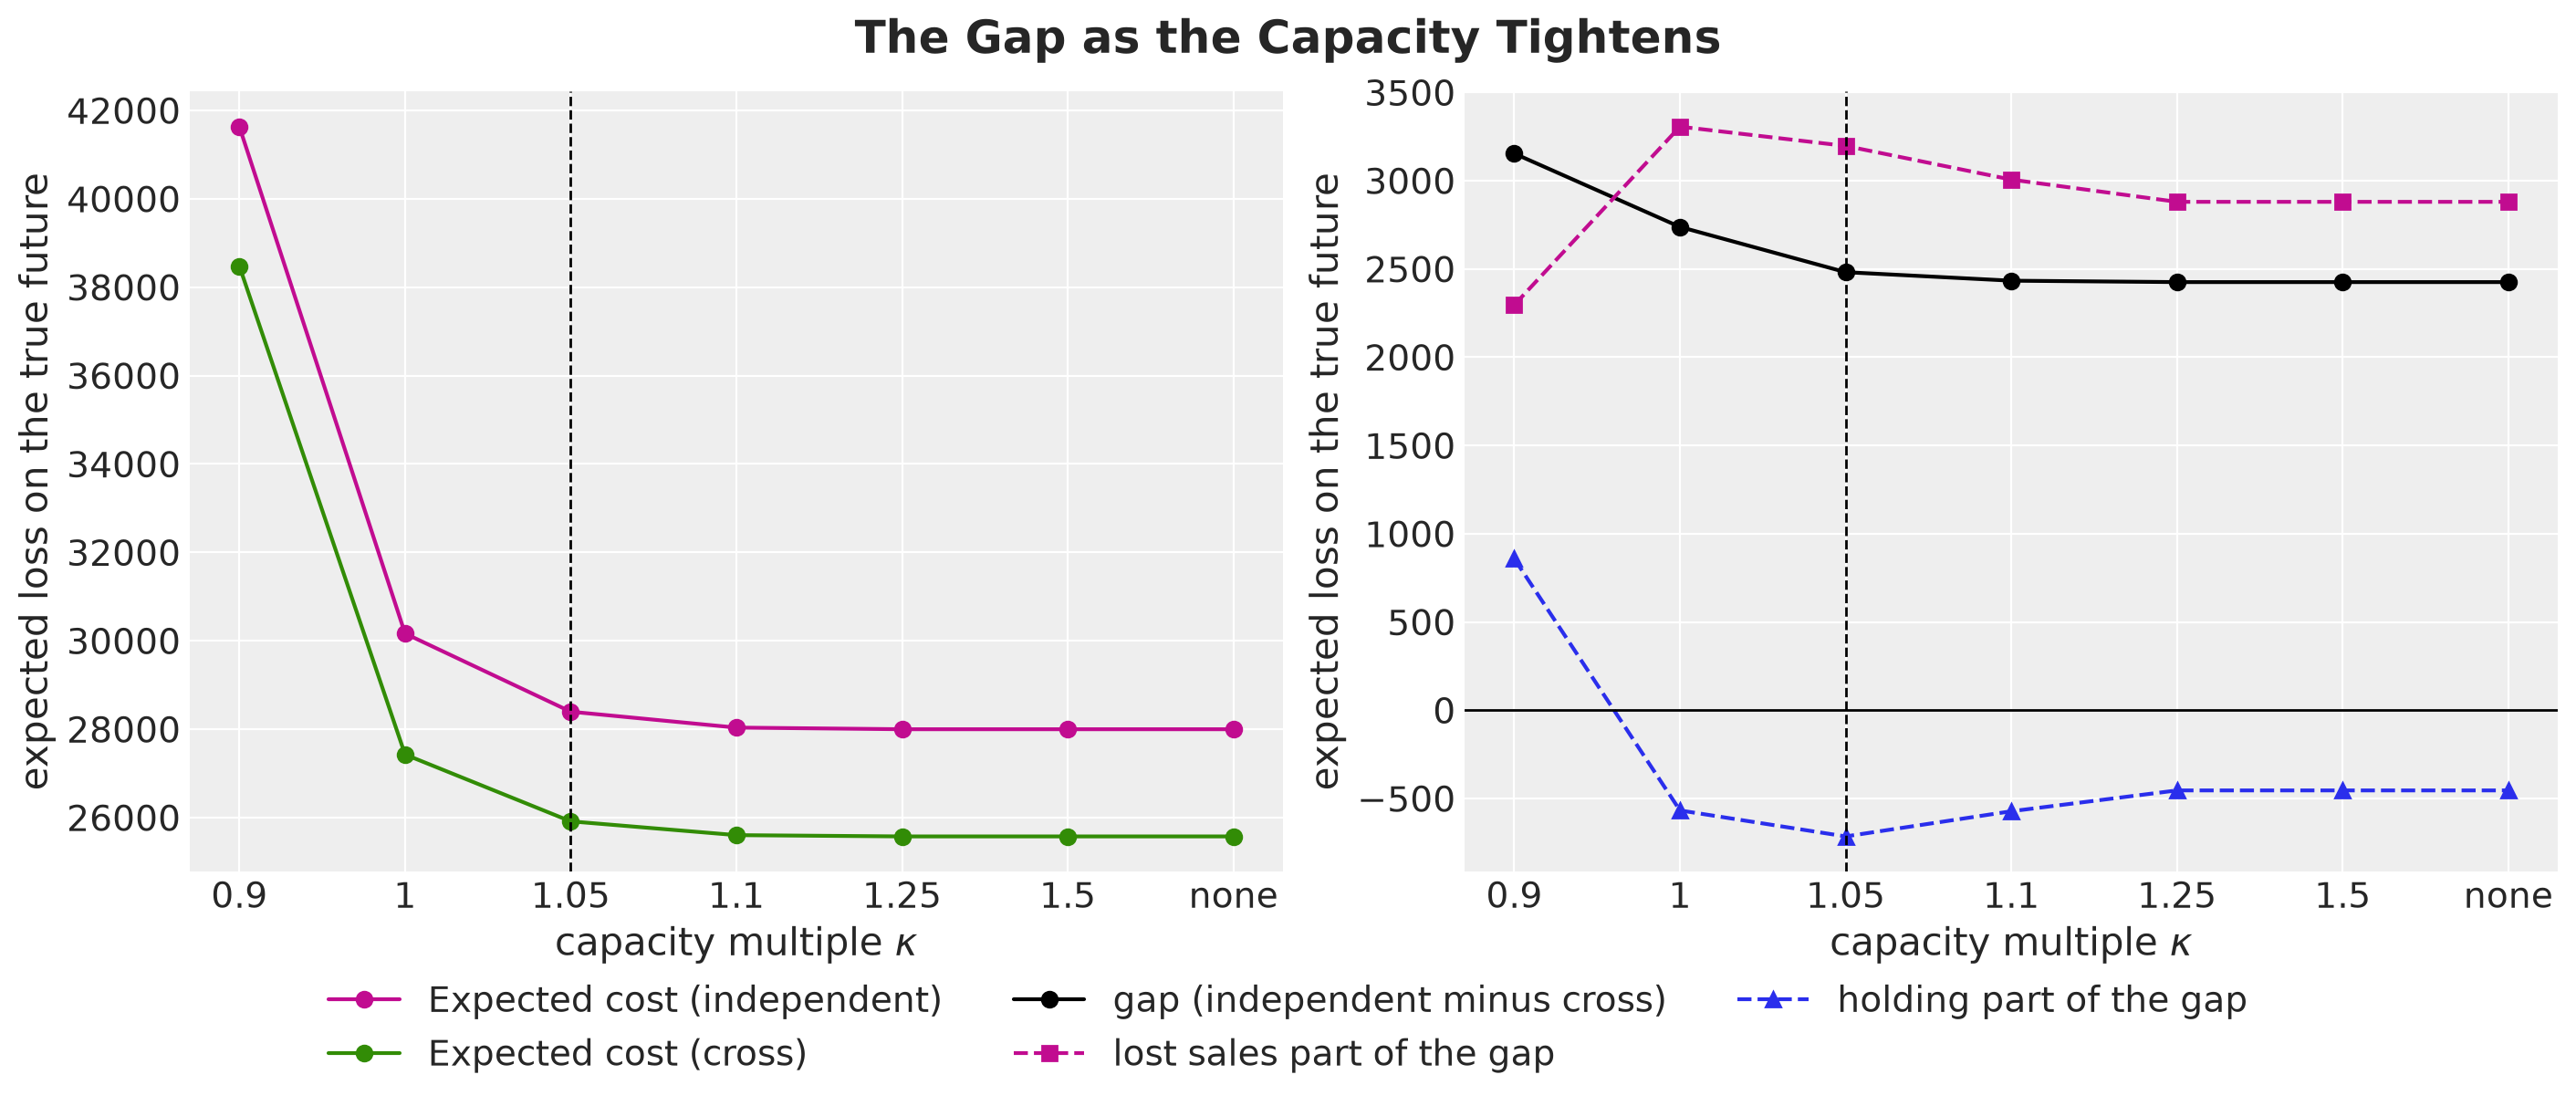

In [56]:
kappa_positions = np.arange(len(kappas))
kappa_labels = [f"{k:g}" for k in kappas[:-1]] + ["none"]

fig, axes = plt.subplots(ncols=2, figsize=(14, 6), layout="constrained")
ax = axes[0]
for name in models:
    sub = sweep.filter(pl.col("model") == name).sort("kappa")
    ax.plot(
        kappa_positions,
        sub["expected loss"],
        "o-",
        color=PLAN_COLORS[f"Expected cost ({name})"],
        label=f"Expected cost ({name})",
    )
ax.set(ylabel="expected loss on the true future")
ax = axes[1]
ax.plot(
    kappa_positions,
    sweep_gap["gap"],
    "o-",
    color="black",
    label="gap (independent minus cross)",
)
ax.plot(
    kappa_positions,
    sweep_gap["lost_sales_gap"],
    "s--",
    color="C3",
    label="lost sales part of the gap",
)
ax.plot(
    kappa_positions,
    sweep_gap["holding_gap"],
    "^--",
    color="C0",
    label="holding part of the gap",
)
ax.axhline(0.0, color="black", linewidth=1)
ax.set(ylabel="expected loss on the true future")
for ax in axes:
    ax.axvline(
        kappa_positions[list(kappas).index(KAPPA)],
        color="black",
        linestyle="--",
        linewidth=1,
    )
    ax.set(
        xticks=kappa_positions,
        xticklabels=kappa_labels,
        xlabel=r"capacity multiple $\kappa$",
    )
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("The Gap as the Capacity Tightens", fontsize=18, fontweight="bold");

Here is what the two panels show.

- **Without a capacity.** The gap is $2{,}425$, or $9.5\%$ of the cross plan's loss, and it is all lost sales: $2{,}880$ more lost sales under the independent plan against $455$ less holding. The cost of ignoring cannibalization is there without any capacity, and it comes from the low level of the independent model.
- **At the capacity of the notebook.** At $\kappa = 1.05$ the gap is $2{,}481$, or $9.6\%$, with $3{,}197$ more lost sales and $715$ less holding. The capacity adds a few hundred units of lost sales on the promoted products and the control group with cross effects, which the siblings crowd out, and takes a few hundred off the holding, because the independent plan cannot stock the siblings as much as it would like.
- **At a tight capacity.** At $\kappa = 0.9$ both plans lose sales on a regular day and both losses jump by half. The gap grows to $3{,}154$ in units, but falls to $8.2\%$ of the cross plan's loss, and its composition changes: the independent plan now pays $858$ more in holding, since it keeps stocking the siblings before the promotion week.

So the capacity changes the composition of the gap more than its size. The cost of ignoring cannibalization is a forecast cost first, and the shared capacity decides which products pay it.

## Conclusion

### Key Findings

- **Rule and forecast both matter.** On the true future the mean forecast plans cost $13\%$ to $21\%$ more than the expected cost plans of the same model, and the independent model costs $10\%$ more than the cross model under the expected cost rule. The point forecast of the right model costs $3\%$ more than the distribution of the wrong one.
- **The cost starts on day one.** A model without a cross-price term has to explain the sibling-promotion dips of the past with its level and its noise. Its level averages over the dips, so its forecast starts $2\%$ to $4\%$ too low on every product with cannibalization in its history, and under a loss where a lost sale costs twenty times a leftover, the first week of the horizon pays $1{,}675$ in extra lost sales before any promotion happens.
- **The promotion week moves the cost around.** The independent plan stocks the siblings for a demand that drops by $10\%$ to $19\%$, and under a full capacity those units are taken from the promoted products, which pay $1{,}060$ more in lost sales in that week, and from the control group with cross effects, which pays $669$ more.
- **Capacity changes the composition, not the size.** The gap is $9.5\%$ without a capacity and $9.6\%$ at the capacity of the notebook. A tight capacity starves both plans and lowers the relative gap to $8.2\%$ while raising it in units. The capacity decides which products pay for the wrong forecast.
- **Calibration does not catch it.** Both models cover the realized future at about $94\%$, their CRPS differ by $4\%$, and their predictive width matches the truth on a single day. The independent model is wide where the cross model is precise, on the siblings in the promotion week, and nothing else in a calibration check separates them.
- **The control group checks the pipeline.** On the group without cannibalization the two plans run out the same, pay the same within $5\%$, and order within about two units per product and day of each other. Every difference between the plans comes from the cross term.
- **SVI with the DCT basis is enough for the ranking, at a price.** The cosine basis recovers the drift scale and the concentration where the plain basis does not, and the plans rank the same on the true future as on their own scenarios. The price is a mean-field guide that is overconfident about the level of every series by a factor of two, which is why the solved plans cost $11\%$ to $15\%$ more on the true future than on their own scenarios.
- **Thin tails over many series.** The tail average is $1.09$ times the expected loss for every plan, so a tail weight changes the plan by less than $1\%$, and the dependence across series does not move the expected cost plan. Under this rule the joint draws matter within a series and not across them.

### Model Limitations

- **Mean-field posterior.** The guide understates the uncertainty about the level at the end of the history by a factor of about two, and the drift scales of the series are covered less than half of the time. The ranking of the plans survives it, but their absolute costs do not. On real data we would compare the guide with NUTS on a subset of the series, or use a guide with a full covariance over the global parameters.
- **Synthetic truth.** The three checks that replace the NUTS diagnostics, parameter recovery, the level at the end of the history and the width against the true future, exist only because we simulated the data. On real data the calibration of the realized future is all we have, and we have seen that it does not separate the models.
- **One promotion pattern.** The promotions are chain-wide, a product is on promotion in every store at once, and the cross elasticities are constant within a group and over time. Store-specific promotions and elasticities that change with the depth of the cut or the display support would need their own terms, see [van Heerde, Leeflang and Wittink (2004)](https://doi.org/10.1287/mksc.1040.0061).
- **No recourse, no lead time.** All orders are fixed today and arrive on the day we planned them for. A rolling horizon that re-forecasts and re-solves every day would correct the level error of the first week after a few days of sales, and a lead time would move the decision to the stock projected at the delivery date.
- **Unconstrained demand history.** The models see the demand itself. In a real lost-sales setting the history is sales, which are censored on the days the shelf was empty, and the dips of a sibling promotion would mix with the dips of an empty shelf.
- **Linear costs and one panel.** A lost sale costs the same margin on every product and day, leftovers keep their value, and the numbers come from one realized panel of $200$ series with one seed.

### Recommendations

1. **Model the siblings when you plan a promotion.** The cross-price term is one matrix of shrunk coefficients, and the data identify it from the weeks in which a sibling was on promotion. Without it the plan pays twice: before the promotion, from a level that averages over the dips of the past, and during it, from stock on the siblings that the promoted products needed.
2. **Check the forecast on the history, not only on calibration.** Look at the residuals of the series in the weeks in which a sibling was on promotion. A model that is wide there, with a low concentration and a wide band, is a model that treats the dips as noise.
3. **Keep a control group.** A group of series that nothing in the question touches is the cheapest check of a pipeline that compares two models. If its plans differ, something other than the model is different.
4. **Report the capacity together with the forecast.** The same forecast error costs holding when the capacity is slack and lost sales on other products when it binds. The planner needs both numbers.

## Next Steps

1. **Promotion choice.** Make the promotion the decision: the discount, the week and the products, with the cannibalization in the objective. The [promotion pricing example](https://github.com/juanitorduz/numpyro_forecast/pull/121) of `numpyro_forecast` does this on real data, with a six-product substitution group and a break-even analysis of the promotion.
2. **Store-specific elasticities.** Let the own and cross elasticities vary by store around a product-level mean, with partial pooling, so that stores with a different mix of customers get their own promotion response.
3. **Lead time and rolling horizon.** Add a pipeline of in-transit orders to the carry of the simulator and wrap the solve in `numpyro_forecast.backtest`, so that each window re-forecasts, re-solves and commits one order. The level error of the first week would then last a few days instead of a week.
4. **Censored sales.** Replace the demand history by a sales history with a censored likelihood on the days with an empty shelf, as in the [censored demand example](https://juanitorduz.github.io/numpyro_forecast/docs/examples/censored_demand.html) of `numpyro_forecast`.
5. **A full-rank guide on the global parameters.** Keep the mean-field guide on the $72{,}800$ increments and put a multivariate Normal on the product-level parameters and the level of every series at the end of the history, and measure how much of the $11\%$ in-sample optimism goes away.

## References

- Orduz, J. (2026). [From Forecasts to Decisions: Inventory Planning with Probabilistic Programming](https://juanitorduz.github.io/forecast_to_decision/). Personal blog.
- Szabłowski, B. (2026). [One Global Model, Many Behaviors: Stockout-Aware Feature Engineering and Dynamic Scaling for Multi-Horizon Retail Demand Forecasting with a Cost-Aware Ordering Policy (VN2 Winner Report)](https://arxiv.org/abs/2601.18919). arXiv:2601.18919.
- van Heerde, H. J., Leeflang, P. S. H. and Wittink, D. R. (2004). [Decomposing the Sales Promotion Bump with Store Data](https://doi.org/10.1287/mksc.1040.0061). *Marketing Science*, 23(3), 317-334.
- Duchi, J., Shalev-Shwartz, S., Singer, Y. and Chandra, T. (2008). [Efficient Projections onto the $\ell_1$-Ball for Learning in High Dimensions](https://doi.org/10.1145/1390156.1390191). *Proceedings of the 25th International Conference on Machine Learning*, 272-279.
- Blei, D. M., Kucukelbir, A. and McAuliffe, J. D. (2017). [Variational Inference: A Review for Statisticians](https://doi.org/10.1080/01621459.2017.1285773). *Journal of the American Statistical Association*, 112(518), 859-877.
- Shapiro, A., Dentcheva, D. and Ruszczyński, A. (2021). [Lectures on Stochastic Programming: Modeling and Theory](https://doi.org/10.1137/1.9781611976595), third edition. SIAM.
- Pyro developers. [Forecasting with `pyro.contrib.forecast`](https://docs.pyro.ai/en/stable/contrib.forecast.html), the module whose `time_reparam` option `numpyro_forecast` ports.
- NumPyro developers. [Example: Hilbert space approximation for Gaussian processes](https://num.pyro.ai/en/stable/examples/hsgp.html).
- Orduz, J. [NumPyro Forecast documentation](https://juanitorduz.github.io/numpyro_forecast/).
- Orduz, J. [Promotion pricing decisions on the Breakfast at the Frat panel](https://github.com/juanitorduz/numpyro_forecast/pull/121). `numpyro_forecast` pull request.
- PreliZ developers. [PreliZ documentation](https://preliz.readthedocs.io/).
- DeepMind. [Optax documentation](https://optax.readthedocs.io/).